# `nmrtools` - Jupyter Usage Examples

This tutorial notebook walks users through the installation and basic methods implemented in `nmrtools`

## 0. Installation

First, we need to install the package. Download the wheel file (.whl) and place anywhere on your computer. Then run the cell below.

In [1]:
# In line below, replace with your path to the wheel file
#%pip uninstall -y "C:\Users\quark\OneDrive\Documents\openNMR\dist\opennmr-0.1.0-py3-none-any.whl"
# In line below, replace with your path to the wheel file
%pip install "C:\Users\quark\OneDrive\Documents\openNMR\dist\opennmr-0.1.0-py3-none-any.whl"

Processing .\dist\opennmr-0.1.0-py3-none-any.whl
Note: you may need to restart the kernel to use updated packages.


### Module imports

In [1]:
# Magic line (Beginning with %) may need the following: !pip install ipympl ipywidgets
# The magic line just allows for an interactive interface for users to zoom-in over data
%matplotlib widget
import sys
import numpy as np
import matplotlib.pyplot as plt
import opennmr.notebook as nmr
from opennmr.notebook.plotting import setup_plotting
setup_plots = setup_plotting()

Every example below assumes `nmr` has been imported this way (cell above). Replace
the `datapath` strings with your own Bruker experiment directories (the
folder containing `acqus` and `pdata/`).

## 1. Import and plot a 1-d spectrum, with optional VOCS processing



### 1.1. Manual import & plot yourself

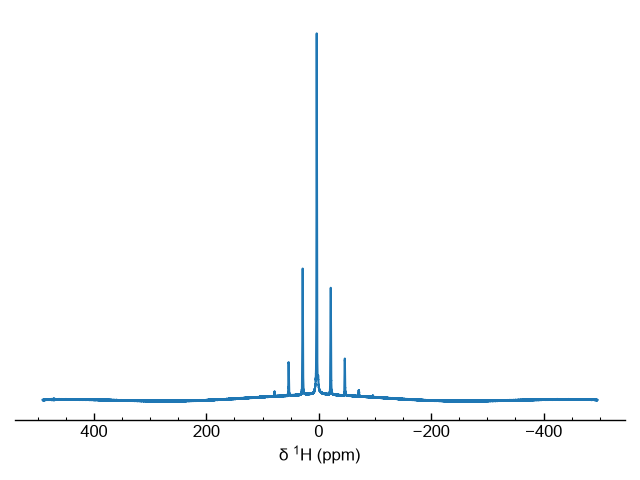

In [3]:
spec = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1")

fig, ax = plt.subplots()
ax.plot(spec["x_ppm"], spec["normalised_real_spectrum"])

ax.invert_xaxis() # <--- to get the axis the "right" way around
ax.tick_params('x', direction = 'in', labelsize = 'large')
ax.yaxis.set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.set_xlabel(nmr.NUC_label(spec["nuclide"]), fontsize = 'large')

plt.tight_layout()
plt.show()

### 1.2. Using the built-in plotting function

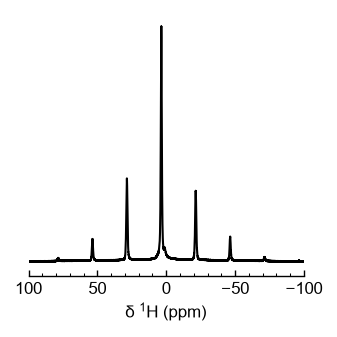

In [10]:
fig, ax = nmr.NMR1dplot(
    r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1",
    mass=[5.5],
    procno=[1],
    normalise=False,
    colour='black',
    xlims=[-100,100],
    
)

Overlaying several spectra (e.g. a stack of samples) just means passing
a list of paths — they get an automatic colour gradient:

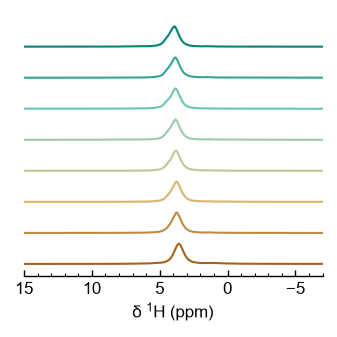

In [11]:
fnames = [r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\4",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\7",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\10",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\13",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\16",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\19",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\22"]

fig, ax = nmr.NMR1dplot(
    fnames,
    #procno=[1, 1, 1],
    colour='diverging',   # or a named matplotlib "colormap", e.g. 'coolwarm'
    yoffset=0.5,
    xlims= [-7,15]
)

### 1.2b. Adding an inset to a 1-d plot

Just like the 2-d contour plots below (§7.2b), `NMR1dplot` (and
`NMR1dheatmap`) can carry one or more insets. Pass `inset` as a dict (or
a list of dicts, for more than one inset). The only required key is
`bounds` -- `(x0, y0, width, height)` in axes-fraction coordinates of the
*parent* plot -- which sets the inset's placement and size. Every other
key accepts exactly the same keyword arguments as `NMR1dplot` itself
(`xlims`, `colour`, `normalise`, `fontsize`, `heatmap`, ...), so an inset
can zoom into a crowded region, use a different colour scheme, or even
switch to a heatmap (with its own colourbar) while the parent stays a
stacked-line plot -- none of the parent's own settings are inherited
automatically. `data_paths` can also be set per inset to show different
spectra than the parent plot; if omitted, the inset shows the same data.
`mark_inset=True` draws a connector box linking the inset back to the
region of the parent plot it corresponds to.

In [ ]:
fig, ax = nmr.NMR1dplot(
    fnames,
    colour='diverging',
    yoffset=0.5,
    xlims=[-7, 15],

    # Zoom into a crowded region, placed in the top-right corner at
    # ~38% of the main plot's width/height.
    inset={
        "bounds": (0.58, 0.55, 0.38, 0.38),   # (x0, y0, width, height), axes-fraction
        "xlims": [3.0, -1.0],                  # the inset's own zoom -- adjust to your peak
        "colour": "diverging",
        "fontsize": "small",
        "mark_inset": True,                    # draw a connector box back to the zoomed region
        "mark_inset_kwargs": {"edgecolor": "crimson", "linewidth": 1.2},
    },
)

# `inset` also accepts a list of dicts for more than one inset, and a
# "data_paths" key per inset to show different spectra than the parent
# plot (it defaults to the same `fnames` if omitted), e.g.:
#   inset=[{"bounds": (0.58, 0.55, 0.35, 0.35), "xlims": [3.0, -1.0]},
#          {"bounds": (0.06, 0.55, 0.35, 0.35), "xlims": [10.0, 6.0]}]
#
# An inset can also be a heatmap of its own -- useful to see a VT/kinetic
# series both as an offset stack (the main plot) and as an image (the
# inset), in one figure:
#   inset={"bounds": (0.58, 0.06, 0.38, 0.38), "heatmap": True,
#          "heatmap_cmap": "plasma", "heatmap_colorbar": True}
#
# The same `inset=...` kwarg works unchanged on NMR1dheatmap itself, and
# through NMR1dplot(heatmap=True, inset=...).

### 1.3. Adding VOCS Processing

VOCS (Variable Offset Cumulative Spectroscopy) combines several
sub-spectra acquired at different carrier offsets, each corrected for
its own finite-pulse excitation profile, into one broadband spectrum.
`NMR1dplot` does this for you when `vocs_sum=True` — just pass the list
of VOCS sub-spectra as `data_paths`:

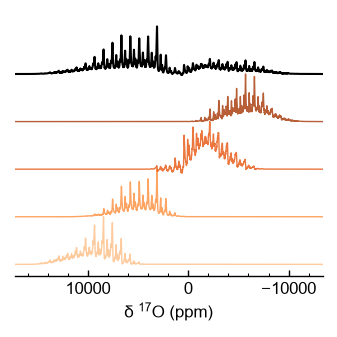

In [16]:
vocs_paths = [r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999912",
              r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999913",
              r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999914",
              r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999915",]

fig, ax = nmr.NMR1dplot(
    vocs_paths,
    #procno=[1, 1, 1],
    vocs_sum=True,
    plot_vocs_parts=True,     # also show each individual VOCS piece
    vocs_pulse="P1",          # acqus parameter holding the excitation pulse length
    vocs_npoints=8192,        # points in the common interpolation axis
    vocs_average=False,       # sum (not average) the pieces
    vocs_yoffset=1.0,
    vocs_colours=['#fdbe85','#fd8d3c','#e6550d','#a63603'],
)

If you want the *processed data itself* (*e.g.*, to fit or inspect it)
rather than just a plot, call the underlying function directly:

In [17]:
vocs_result = nmr.VOCSSum(vocs_paths, pulse="P1", npoints=8192)

vocs_result["ppm"]                  # common ppm axis
vocs_result["VOCS_sum"]             # summed spectrum
vocs_result["interpolated_slices"]  # each piece, interpolated onto the common axis
vocs_result["slices"]               # each piece's raw NMR1dimport() output

[{'x_ppm': array([17277.99215987, 17277.87963055, 17277.76710122, ...,
          2528.886084  ,  2528.77355467,  2528.66102535], shape=(131072,)),
  'x_Hz': array([1171442.4201535 , 1171434.79070076, 1171427.16124802, ...,
          171457.67905898,  171450.04960624,  171442.4201535 ],
        shape=(131072,)),
  'real_spectrum': array([0., 0., 0., ..., 0., 0., 0.], shape=(131072,)),
  'normalised_real_spectrum': array([0.06586693, 0.06589351, 0.06592227, ..., 0.06580193, 0.06582099,
         0.06584271], shape=(131072,)),
  'imag_spectrum': array([-0., -0., -0., ..., -0., -0., -0.], shape=(131072,)),
  'normalised_imag_spectrum': array([0.74077492, 0.74085685, 0.74093682, ..., 0.74051764, 0.74060526,
         0.74069104], shape=(131072,)),
  'nuclide': '17O',
  'BF1': 67.799908,
  'SFO1': 67.7996846690465,
  'path': 'C:\\Users\\quark\\OneDrive\\Documents\\NMR\\500MHz\\15_02_26_Li2MnO3_O17_1_3mm\\999912'},
 {'x_ppm': array([13277.97898394, 13277.86645462, 13277.75392529, ...,
         

Or, to VOCS-correct a single already-imported spectrum in place (no
combination with other spectra):

In [ ]:
spec = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1")
spec = nmr.apply_VOCS(spec, pulse="P1")

### 1.4 Adding and subtracting 1-d spectra

`nmrtools.arithmetic` combines any number of 1-d spectra with signed
weights, even when they don't share an identical ppm axis (different
`SW`/`SI`, slightly different referencing) -- every input spectrum is
interpolated onto one common axis first (ppm by default, since ppm is
field-independent; pass `x_unit="Hz"` if all inputs share the same `SFO1`).

- `combine_spectra` returns just the common axis, the combined trace,
  and the (unscaled) interpolated inputs -- handy for a quick plot.
- `combine_spectra_as_results` wraps the same computation in a dict
  shaped like an `NMR1dimport` result, so the combined spectrum can be
  fed straight into `fit_spectrum`, `NMR1dplot_with_fit`, etc.


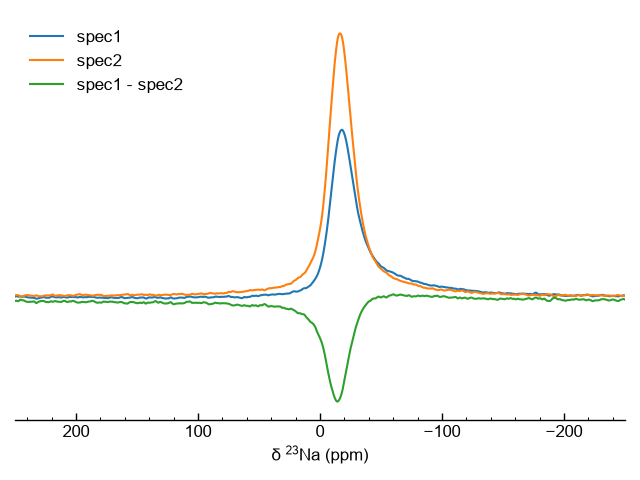

In [18]:
fname1 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\231"
fname2 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\232"

spec1 = nmr.NMR1dimport(fname1)
spec2 = nmr.NMR1dimport(fname2)

# spec1 - spec2, interpolated onto their common (overlapping) ppm range
diff = nmr.combine_spectra_as_results([spec1, spec2], ops=['+', '-'])

##########

fig, ax = plt.subplots()

ax.plot(spec1["x_ppm"], spec1["real_spectrum"], label='spec1')
ax.plot(spec2["x_ppm"], spec2["real_spectrum"], label='spec2')

ax.plot(diff["x_ppm"], diff["real_spectrum"], label='spec1 - spec2')

ax.set_xlim([-250, 250])
ax.invert_xaxis() # <--- to get the axis the "right" way around
ax.tick_params('x', direction = 'in', labelsize = 'large')
ax.yaxis.set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.set_xlabel(nmr.NUC_label(spec1["nuclide"]), fontsize = 'large')

ax.legend(frameon=False, loc=2)

plt.tight_layout()
plt.show()


For a *difference* spectrum, leave `common_range` at its default,
`'intersection'` -- only the region covered by *every* input spectrum is
used. Using `'union'` instead would zero-fill each spectrum outside its
own original range, which would manufacture a spurious "signal" in
exactly the region a difference spectrum is meant to reveal, not create.
`'union'` (zero-filled) is the convention `VOCSSum` uses instead, which
is the right choice when *summing* VOCS components.

`scaling_factors` weight each spectrum before combining -- e.g. to
correct for a mass/scan-count mismatch that wasn't already handled at
import time (`NMR1dimport(..., mass=...)`), or simply to compute
something like `2*spec1 - spec2`:


In [19]:
fname1 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\231"
fname2 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\232"

spec1 = nmr.NMR1dimport(fname1)
spec2 = nmr.NMR1dimport(fname2)

weighted_diff = nmr.combine_spectra_as_results(
    [spec1, spec2], ops=['+', '-'], scaling_factors=[2.0, 1.0],
)


The lower-level `combine_spectra` takes any number of spectra at once
and hands back the raw arrays (rather than an `NMR1dimport`-shaped
dict) -- useful for a quick look, or when you don't need the result to
feed into the fitting functions. `npoints` and `interp_kind` control the
resolution and interpolation order of the common axis:


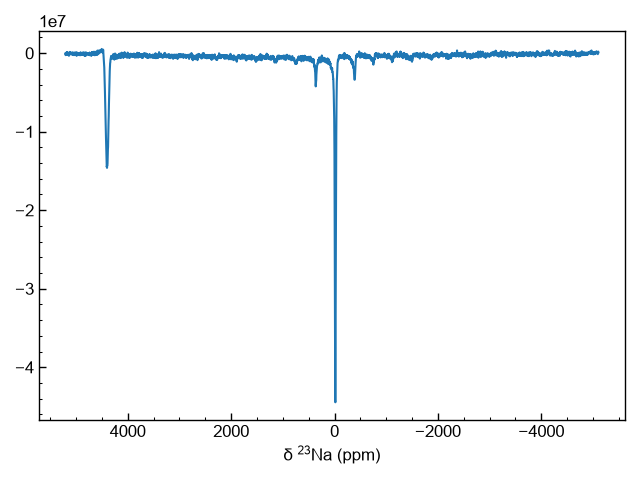

In [20]:
fname3 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\232"
spec3 = nmr.NMR1dimport(fname3)

combo = nmr.combine_spectra(
    [spec1, spec2, spec3], ops=['+', '-', '-'],
    scaling_factors=[1.0, 1.0, 0.5],
    common_range='intersection', npoints=4096, interp_kind='linear',
)

fig, ax = plt.subplots()
ax.plot(combo["x_ppm"], combo["combined_spectrum"])
ax.invert_xaxis()
ax.set_xlabel(nmr.NUC_label(spec1["nuclide"]))
plt.tight_layout()
plt.show()


### 1.5 Plotting several 1-d spectra as a heatmap

For a series of spectra that vary along some third axis -- a VT (variable-temperature) series, a titration, a kinetic run -- it's often clearer to look at them as rows of a 2-d heatmap than as an offset stack. `NMR1dheatmap` takes the same kind of `data_paths` list as `NMR1dplot`, interpolates every spectrum onto one common ppm/Hz axis (the same interpolation `combine_spectra` uses), and displays the stack as an image instead:


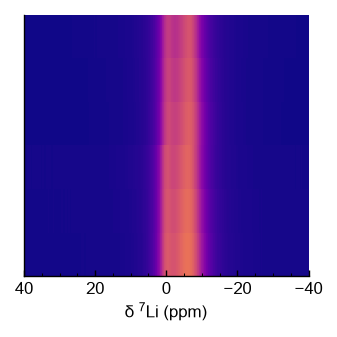

In [21]:
fnames_VT = [r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\4",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\8",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\12",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\16",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\20",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\24"]

fig, ax, im = nmr.NMR1dheatmap(
    fnames_VT,
    normalise=False,
    cmap='plasma',
    xlims=[40, -40],
)


By default the y-axis has no ticks at all -- the rows are just "spectrum 1, 2, 3, ..." in the order given. If you have a real value per spectrum (here, the VT series' set temperatures), pass it as `y_values` and turn ticks on with `y_ticks='all'` (one tick per row) or `y_ticks='auto'` (an automatically-thinned number of ticks, useful once you have many spectra). A colourbar and its label are opt-in via `colorbar`/`colorbar_label`:


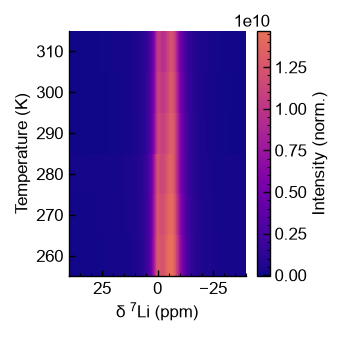

In [4]:
temperatures = [260,270,280,290,300,310]  # degC, one per entry in fnames

fnames_VT = [r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\4",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\8",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\12",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\16",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\20",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\24"]


fig, ax, im = nmr.NMR1dheatmap(
    fnames_VT,
    normalise=False,
    y_values=temperatures,
    y_ticks='all',           # or 'auto' for a thinned-out set of ticks
    ylabel='Temperature (K)',
    xlims=[-40, 40],
    cmap='plasma',
    colorbar=True,
    colorbar_label='Intensity (norm.)',
)


`NMR1dheatmap` is also wired directly into `NMR1dplot` -- pass `heatmap=True` and the same `y_values`/`y_ticks`/`ylabel` keywords (prefixed `heatmap_cmap`, `heatmap_vmin`/`heatmap_vmax`, `heatmap_colorbar`, `heatmap_colorbar_label` for the heatmap-only options that would otherwise clash with `NMR1dplot`'s own `color` argument), if you'd rather not import a second function:


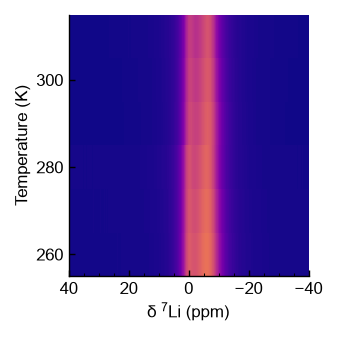

In [4]:
temperatures = [260,270,280,290,300,310]  # degC, one per entry in fnames

fnames_VT = [r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\4",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\8",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\12",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\16",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\20",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\24"]

fig, ax, im = nmr.NMR1dplot(
    fnames_VT,
    heatmap=True,
    normalise=False,
    y_values=temperatures,
    y_ticks='auto',
    y_tick_number=4,
    ylabel='Temperature (K)',
    heatmap_cmap='plasma',
    xlims=[40,-40],
)


### 1.6 Process a raw CPMG echo-train FID (`CPMGprocess`)

Everything above imports already-processed data from `pdata`. A CPMG
(Carr-Purcell-Meiboom-Gill) echo train is different -- it needs to be
read as a raw, unprocessed FID and split into its individual echoes
before it can be treated as an ordinary spectrum. `CPMGprocess` does
this in one call: it reads the raw `fid` file directly, splits it into
echoes using the echo spacing/blanking/echo-count read from `acqus`,
co-adds them, apodizes, zero-fills, and Fourier transforms -- returning
a results dict shaped just like `NMR1dimport`'s, so it plots with
`CPMGplot` and feeds into the same fitting tools as any other spectrum.

This tutorial doesn't have a real CPMG dataset lying around, so the
cell below fabricates a toy one first -- a synthetic `acqus` +
raw `fid` file, written to a temporary Bruker-style experiment
directory -- purely so the rest of this section has something concrete
to process (the same trick Section 6.3 uses for the pNMR-fitting
example). In real use you'd point `CPMGprocess` straight at your own
experiment directory instead of building `datapath` this way.

In [5]:
import os, tempfile
import numpy as np

# ---------------------------------------------------------------
# Fabricate a toy CPMG echo-train FID + acqus, purely for this demo.
# 64 echoes, each a decaying, off-resonance oscillation, plus noise.
# ---------------------------------------------------------------
rng = np.random.default_rng(1)

SW_h = 500_000.0            # Hz
dw = 0.5e6 / SW_h            # us -- matches CPMGprocess's own convention
echo_length_us = 400.0
blanking_us = 60.0
num_echoes = 64
safety = 8

period = int((echo_length_us + blanking_us) / (2 * dw))
blanking_pp = int(0.5 * blanking_us / (2 * dw) - safety)
core_len = period - 2 * blanking_pp

point_dt_s = 2 * dw * 1e-6            # seconds/point, matching CPMGprocess
t = np.arange(core_len) * point_dt_s
carrier_offset_hz = 500.0             # where the "peak" should end up
T2_echo = 3e-3

leading_blank = 500
fid_len = leading_blank + num_echoes * period + 200
fid = np.zeros(fid_len, dtype=complex)

for k in range(num_echoes):
    amp = np.exp(-k * period * point_dt_s / 0.05)   # decay across the echo train
    echo = amp * 2e4 * np.exp(-t / T2_echo) * np.exp(1j * 2 * np.pi * carrier_offset_hz * t)
    start = leading_blank + k * period + blanking_pp
    fid[start:start + core_len] += echo

fid += rng.normal(0, 30, fid_len) + 1j * rng.normal(0, 30, fid_len)
fid[:leading_blank + blanking_pp] = 0   # blanked receiver: genuinely zero, not just noise

datapath = tempfile.mkdtemp()

interleaved = np.empty(2 * fid_len, dtype=np.int32)
interleaved[0::2] = np.round(fid.real).astype(np.int32)
interleaved[1::2] = np.round(fid.imag).astype(np.int32)
interleaved.tofile(os.path.join(datapath, "fid"))

D = [0.0] * 32
D[6] = echo_length_us * 1e-6           # d6 -- echo length
CNST = [0.0] * 22
CNST[20] = blanking_us                 # cnst20 -- blanking
L = [0] * 24
L[22] = num_echoes                     # l22 -- number of echoes

def _fmt(vals):
    return "\n".join(" ".join(f"{v:.10g}" for v in vals[i:i + 8]) for i in range(0, len(vals), 8))

with open(os.path.join(datapath, "acqus"), "w") as f:
    f.write(f"""##$NUC1= <7Li>
##$BF1= 155.4
##$SFO1= 155.401
##$O1= 0.0
##$NS= 1
##$TD= {2 * fid_len}
##$SW_h= {SW_h}
##$BYTORDA= 0
##$DTYPA= 0
##$D= (0..{len(D)-1})
{_fmt(D)}
##$CNST= (0..{len(CNST)-1})
{_fmt(CNST)}
##$L= (0..{len(L)-1})
{_fmt(L)}
""")

print("toy CPMG dataset written to:", datapath)


toy CPMG dataset written to: C:\Users\quark\AppData\Local\Temp\tmpj7kc93v_


With a `datapath` in hand (real or, as here, synthetic), processing
and plotting works exactly like any other 1-d import. Auto-detection
(`first_point='auto'`, the default) locates the start of the echo
train for you; the `echo_delay_index`/`blanking_delay_index`/
`blanking_cnst_index`/`num_echoes_index` keyword defaults match a
commonly-used CPMG pulse program -- override them if your own pulse
program stores the echo length/blanking/echo-count elsewhere in
`acqus`'s `D`/`CNST`/`L` arrays.

echoes acquired / used: 64 / 64
auto-detected first echo point: 527


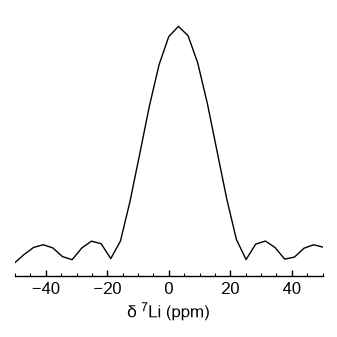

In [6]:
cpmg_results = nmr.CPMGprocess(datapath)

print("echoes acquired / used:", cpmg_results["num_echoes"], "/", cpmg_results["num_echoes_used"])
print("auto-detected first echo point:", cpmg_results["first_point"])

fig, ax = nmr.CPMGplot(cpmg_results, xlims=[50, -50])


If the auto-detected split looks wrong on real data (echoes visibly
misaligned when you plot a couple of them, as below), override it with
an explicit `first_point=...` rather than the `'auto'` default:

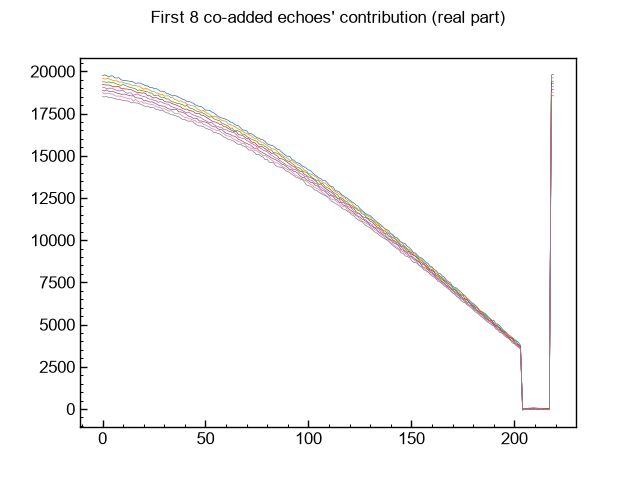

In [4]:
fig, ax = plt.subplots()
for echo in cpmg_results["echoes_real"][:8]:
    ax.plot(echo, lw=0.5)
ax.set_title("First 8 co-added echoes' contribution (real part)")
plt.show()

# e.g. cpmg_results = nmr.CPMGprocess(datapath, first_point=1234)


## 2. Fit an imported 1-d spectrum

Define your peak model(s) — chemical shift, initial FWHM, and (for
pseudo-Voigt peaks) the Gaussian/Lorentzian mixing parameter `eta`.
Bounding the shift to a narrow window around the expected position is
strongly recommended: with no bounds, `curve_fit` is free to slide
overlapping peaks anywhere, which can converge to a degenerate,
physically meaningless solution. Quantities may also be fixed (not fitted).


NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.692844 ± 0.011131
  fwhm      = 7.617438 ± 0.024107
  amplitude = 16968155704.917402 ± 0.001772
  eta       = 0.350123 ± 0.006927
  integral (raw) = 153605652729.4409
  integral (%)    = 65.42

Peak 2 (pseudo-voigt):
  shift     = -0.005240 ± 0.011286
  fwhm      = 5.283234 ± 0.026498
  amplitude = 11128515685.187311 ± 0.002688
  eta       = 0.798988 ± 0.013951
  integral (raw) = 81186106803.0095
  integral (%)    = 34.58

Fit quality:
------------------------------------------------------------
RMSE          : 6.856091e+07
Chi^2         : 1.193952e+18
Reduced Chi^2 : 4.893246e+15

Optimised params from fit:  [-5.69284407e+00  7.61743814e+00  1.69681557e+10  3.50122710e-01
 -5.24027616e-03  5.28323385e+00  1.11285157e+10  7.98987820e-01
  1.78005985e+06  3.34016693e+01]
Covariance in optimised params:  [[ 1.23906501e-04  2.16397229e-04  7.32784718e-06 

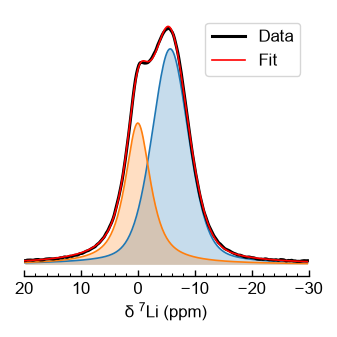

In [ ]:
peak_defs = [
    {"type": "pseudo-voigt", "shift": -5.20, "fwhm": 5.0, "eta" : 0.5,
     "bounds": {"shift": (-6.0, -5.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)}},
    {"type": "pseudo-voigt", "shift": -0.52, "fwhm": 5.0, "eta" : 0.5,
     "bounds": {"shift": (0.5, -1.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)}},
]

#  Example with fixed peaks:

# peak_defs = [
#     {"type": "pseudo-voigt", "shift": -5.20, "fwhm": 5.0, "eta" : 0.5,
#      "bounds": {"shift": (-6.0, -5.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)},
#      "fixed": {"eta": True}},
#     {"type": "pseudo-voigt", "shift": -0.52, "fwhm": 5.0, "eta" : 0.5,
#      "bounds": {"shift": (0.5, -1.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)},
#      "fixed": {"eta": True}},
# ]

fit = nmr.NMRFitWorkflow(
    r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\1",
    peak_defs,
    procno=1,
    fit_regions=[(20, -30)],     # restrict the fit to this ppm window; None = whole spectrum
    show_plot=True,
    show_components=True,        # overlay individual peaks + baseline
    show_report=True,            # print fitted parameters, uncertainties, integrals
    xlims=[20,-30],
)

print("Optimised params from fit: ", fit["popt"])             # fitted parameters (shift, fwhm, amplitude[, eta] per peak, then b0, b1)
print("Covariance in optimised params: ", fit["pcov"])        # full covariance matrix
print("Components: ", fit["components"])                      # individual peak curves + baseline (last entry)

If you’d rather drive the lower-level pieces yourself (*e.g.* to reuse an
already-imported spectrum, or fit several regions differently):

c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\fitting.py:927: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


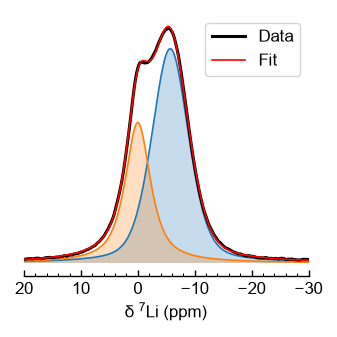

In [25]:
from opennmr.notebook.fitting import expand_pcov  # not re-exported at the top level -- see note below

spec = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\1")

popt, pcov_free, is_free, scale, x_ref = nmr.fit_spectrum(
    spec, peak_defs, fit_regions=[(20,-30)], use_normalised=True,
)
pcov = expand_pcov(pcov_free, is_free, len(popt))

y_fit, components = nmr.evaluate_fit(spec["x_ppm"], popt, peak_defs, x_ref=x_ref, return_components=True)
integrals, integrals_norm = nmr.compute_integrals(spec["x_ppm"], components)

fig, ax = nmr.NMR1dplot_with_fit(spec, popt, peak_defs, show_components=True, xlims=[-30,20])

Note: `expand_pcov`, `check_bound_hits`, `build_bounds`, and a few other
lower-level helpers aren’t re-exported at the package’s top level (only
the main entry points are, to keep `dir(nmrtools)` readable) — import
them from `nmrtools.fitting` directly if you need them, as above.

## 3. Modelling and Simulating Chemical Shift Anisotropy

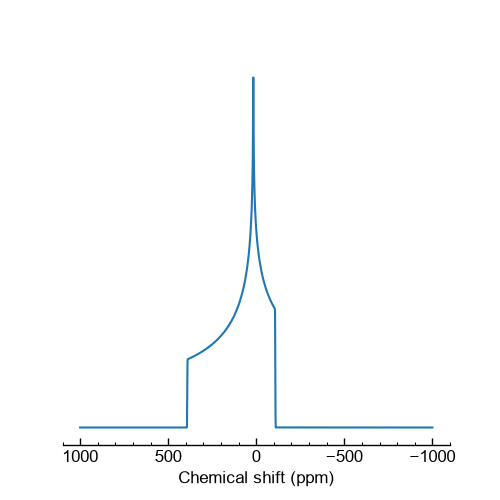

In [7]:
csa_example = nmr.csa_definition(100, 500, 0.5, convention='Herzfeld-Berger')

spec = nmr.make_static_csa_spectrum(csa_example, np.linspace(-1000, 1000, 5001), powder_scheme='zcw', n_zcw=200000)

#######

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(spec['x_ppm'], spec['real_spec'], '-')

ax.set_xlabel("Chemical shift (ppm)")
ax.yaxis.set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.invert_xaxis()

plt.show()

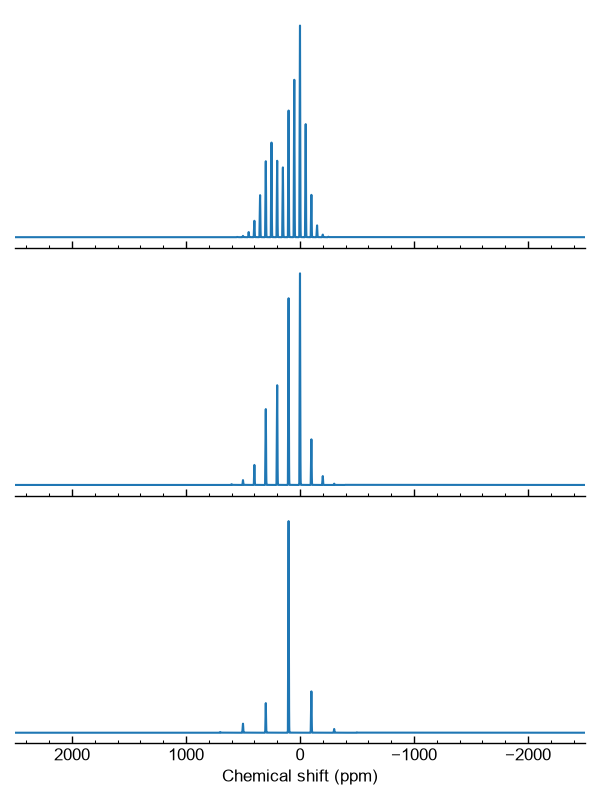

In [8]:
mas_rates = [25000, 50000, 100000]
csa_example = nmr.csa_definition(100, 500, 0.5, convention='Herzfeld-Berger')

fig, axes = plt.subplots(3, 1, figsize=(6, 8), sharex=True)

for ax, mas_Hz in zip(axes, mas_rates):

    spectrum = nmr.finite_mas_csa_spectrum(csa_example, np.linspace(-10000,10000,50001), larmor_Hz=500e6, mas_Hz=mas_Hz,
                                        n_time=4096, n_sidebands=100, fwhm=5.0, powder_scheme='zcw', n_zcw=320)

    ax.plot(spectrum['x_ppm'], spectrum['real_spec'], '-')

    ax.set_ylabel(f"{mas_Hz/1000:g} kHz")

    ax.set_xlim([-2500, 2500])
    ax.invert_xaxis()
    ax.yaxis.set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

axes[-1].set_xlabel(
    "Chemical shift (ppm)"
)


plt.tight_layout()
plt.show()

### 3.2: J-Coupling

In [5]:
from opennmr.notebook.utils import find_isotope_info, compute_BF1_SFO1
from opennmr.notebook.simulations import jcoupled_spectrum, multi_site_jcoupled_spectrum


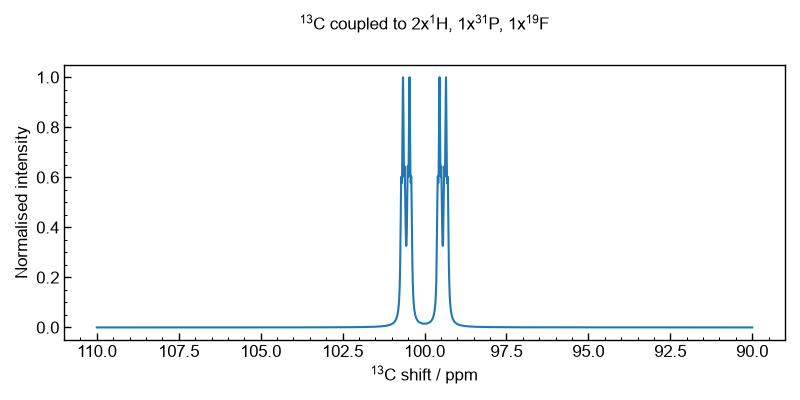

In [6]:
# A 13C coupled to 2 equivalent 1H, 1 31P and 1 19F simultaneously
# each group has its own n and J, and can be a different nuclide.

couplings = [
    {'nuclide': '1H',  'n': 2, 'J_Hz': 7.0},    # 2JCH
    {'nuclide': '31P', 'n': 1, 'J_Hz': 140.0},  # 1JCP
    {'nuclide': '19F', 'n': 1, 'J_Hz': 25.0},   # 3JCF
]

# Observe frequency for 13C at, say, an 11.74 T (500 MHz 1H) field
BF1, SFO1, nuclide = compute_BF1_SFO1('13C', B0_tesla=11.74)
larmor_Hz = SFO1 * 1e6

ppm_axis = np.linspace(90, 110, 20001)
spec = jcoupled_spectrum(
    center_ppm=100.0, larmor_Hz=larmor_Hz, couplings=couplings,
    ppm_axis=ppm_axis, fwhm=0.05, lineshape='lorentzian',
)

plt.figure(figsize=(8, 4))
plt.plot(spec['x_ppm'], spec['normalised_real_spec'])
plt.xlabel('$^{13}$C shift / ppm')
plt.ylabel('Normalised intensity')
plt.title('$^{13}$C coupled to 2x$^{1}$H, 1x$^{31}$P, 1x$^{19}$F')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

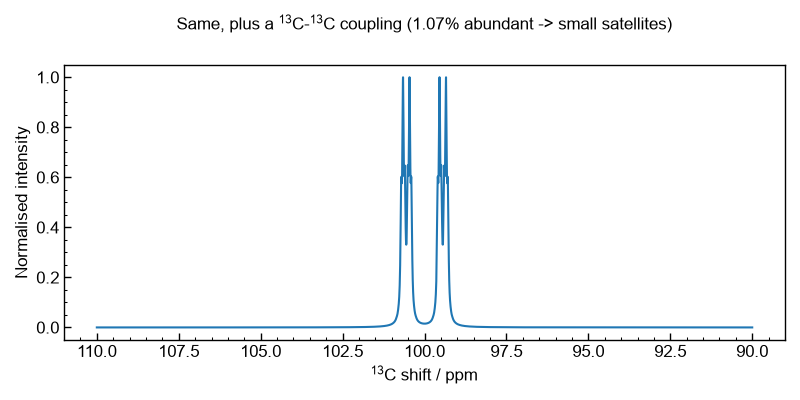

In [7]:
# Same idea, but see the effect of isotopic abundance directly:
# 13C-13C coupling (1.07% abundant partner) shows tiny satellites,
# whereas the 1H/31P/19F couplings above (all ~100% abundant) don't.
couplings_with_13C_satellite = couplings + [
    {'nuclide': '13C', 'n': 1, 'J_Hz': 35.0},  # 1JCC, only ~1% of molecules
]

spec2 = jcoupled_spectrum(
    center_ppm=100.0, larmor_Hz=larmor_Hz, couplings=couplings_with_13C_satellite,
    ppm_axis=ppm_axis, fwhm=0.05, lineshape='lorentzian',
)

plt.figure(figsize=(8, 4))
plt.plot(spec2['x_ppm'], spec2['normalised_real_spec'])
plt.xlabel('$^{13}$C shift / ppm')
plt.ylabel('Normalised intensity')
plt.title('Same, plus a $^{13}$C-$^{13}$C coupling (1.07% abundant -> small satellites)')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

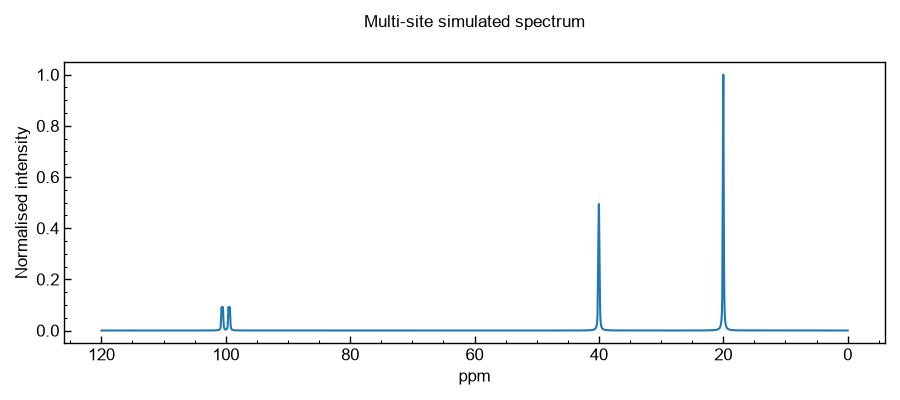

In [8]:
# Multiple chemical sites in one spectrum, each with its own
# coupling network -- e.g. a CH3-CH2-31P-type fragment.
sites = [
    {'ppm': 100.0, 'relative_intensity': 1.0, 'couplings': couplings},   # the quaternary/coupled C above
    {'ppm': 20.0,  'relative_intensity': 3.0, 'couplings': [
        {'nuclide': '1H', 'n': 2, 'J_Hz': 7.0},   # CH3 next to a CH2
    ]},
    {'ppm': 40.0,  'relative_intensity': 2.0, 'couplings': [
        {'nuclide': '1H', 'n': 3, 'J_Hz': 7.0},   # CH2 next to a CH3
        {'nuclide': '31P', 'n': 1, 'J_Hz': 12.0},
    ]},
]

ppm_axis_full = np.linspace(0, 120, 30001)
multi_spec = multi_site_jcoupled_spectrum(
    sites, larmor_Hz=larmor_Hz, ppm_axis=ppm_axis_full, fwhm=0.1,
)

plt.figure(figsize=(9, 4))
plt.plot(multi_spec['x_ppm'], multi_spec['normalised_real_spec'])
plt.xlabel('ppm')
plt.ylabel('Normalised intensity')
plt.title('Multi-site simulated spectrum')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

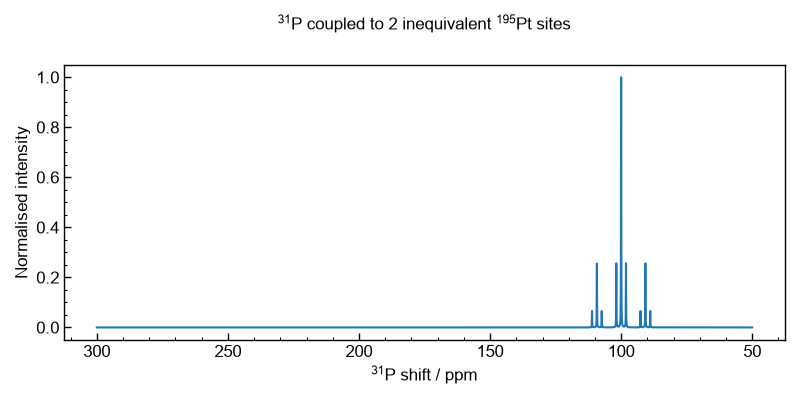

In [9]:
# 31P coupled to 2 inequivalent 195Pt sites (different J to each) --
# 195Pt is only ~33.8% naturally abundant, so (unlike the ~100%-abundant
# 1H/31P/19F partners above) this couples in as a set of satellites
# either side of the uncoupled centreband, not a clean multiplet with
# no centreband. Large couplings like these (hundreds to thousands of
# Hz) are typical for a direct M-P bond.

couplings = [
    {'nuclide': '195Pt', 'n': 1, 'J_Hz': 3000.0},
    {'nuclide': '195Pt', 'n': 1, 'J_Hz': 600.0},
]

BF1, SFO1, nuclide = compute_BF1_SFO1('31P', B0_tesla=9.40)  # 400 MHz (1H) field
larmor_Hz = SFO1 * 1e6

ppm_axis = np.linspace(50, 300, 100001)
spec = jcoupled_spectrum(
    center_ppm=100.0, larmor_Hz=larmor_Hz, couplings=couplings,
    ppm_axis=ppm_axis, fwhm=0.1, lineshape='lorentzian',
)

plt.figure(figsize=(8, 4))
plt.plot(spec['x_ppm'], spec['normalised_real_spec'])
plt.xlabel('$^{31}$P shift / ppm')
plt.ylabel('Normalised intensity')
plt.title('$^{31}$P coupled to 2 inequivalent $^{195}$Pt sites')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Inspect the underlying stick pattern (positions + intensities)
# for the first site, independent of the chosen linewidth.
for ppm, inten in zip(spec['stick_ppm'], spec['stick_intensity']):
    print(f"{ppm:9.4f} ppm   intensity {inten:.5f}")

### 3.3 Quadrupolar lineshapes (static and MAS)

`nmr.quadrupolar_spectrum` simulates the powder pattern of a quadrupolar nucleus (I ≥ 1), static (`mas_Hz=0`) or under MAS, at three levels of theory, for any choice of transitions:

| argument | options |
|---|---|
| `order` | `'first'` (first-order shift only), `'second'` (+ second order, perturbation theory), `'exact'` (diagonalises $H_Z + H_Q$) |
| `transitions` | `'ct'` (−1/2 ↔ +1/2), `'st'` (satellites), `'all'`, or group names such as `'ST1'` |

Things worth knowing before you use it:

* **Units.** `C_Q` is in **Hz** here (e.g. `3e6`); `larmor_Hz` is $|\gamma B_0|$ in Hz -- `nmr.larmor_frequency_Hz('27Al', 11.7467)` gives it from the field. (The *fitting* functions and `Site` below take `C_Q` in MHz.)
* **Intensities are quantitative.** All $2I$ transitions of a site sum to 1, so a CT-only spectrum integrates to the CT's true share (9/35 for I = 5/2).
* **Speed.** In high field every frequency is a closed-form function of the B0 direction in the EFG frame, so all crystallites are computed at once; under MAS the rotor modulation (≤ 4 harmonics) is integrated analytically and the γ-averaged sidebands come from one FFT per crystallite. A MAS CT simulation with ~4000 crystallites takes well under a second.
* **Powder average.** One octant of the sphere is used when that is exact by symmetry (it is here) -- 8× the orientation density for the same cost.
* Every result carries a one-line `'log'` of exactly what was simulated.

27Al Larmor frequency: 130.4245 MHz
nu_Q for C_Q = 5 MHz, I = 5/2: 750 kHz


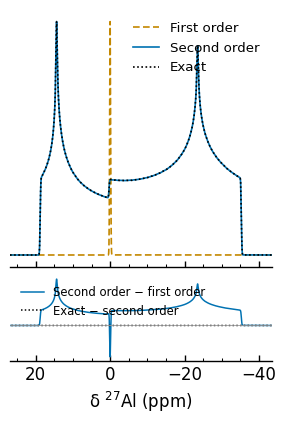

Static quadrupolar powder pattern: I = 2.5, C_Q = 5 MHz, eta_Q = 0.2, nu0 = 130.425 MHz, nu_Q = 750 kHz, delta_iso = 0 ppm; exact diagonalisation of H_Z + H_Q; transitions CT; 104006 orientations (zcw, one octant, exact by symmetry).


In [ ]:
nu0_Al = nmr.larmor_frequency_Hz('27Al', 11.7467)          # 11.7467 T = 500 MHz 1H: 130.42 MHz 27Al
print(f"27Al Larmor frequency: {nu0_Al/1e6:.4f} MHz")
print(f"nu_Q for C_Q = 5 MHz, I = 5/2: {nmr.quadrupolar_nu_Q(2.5, 5e6)/1e3:.0f} kHz")

# A frame that holds the whole central transition, from the pattern itself:
lo, hi = nmr.quadrupolar_axis_limits(2.5, 5e6, 0.2, nu0_Al, transitions='ct', fwhm=0.3)
axis = np.linspace(lo, hi, 4096)

# First order, second order and exact, side by side, with their differences underneath
orders = nmr.quadrupolar_order_comparison(2.5, 5e6, 0.2, nu0_Al, axis, transitions='ct', fwhm=0.3)
nmr.plot_quadrupolar_orders(orders, nuclide='27Al')
plt.show()
print(orders['exact']['log'])

At first order the central transition does not move at all (a single line at δ<sub>iso</sub>): its whole lineshape and its shift *below* δ<sub>iso</sub> come from second order. The lower panel shows what each order adds; "exact − second" is the third-and-higher-order part, negligible here (ν<sub>Q</sub> ≪ ν<sub>0</sub>).

The full pattern, CT and satellites together, and each transition group separately (`'components'`):

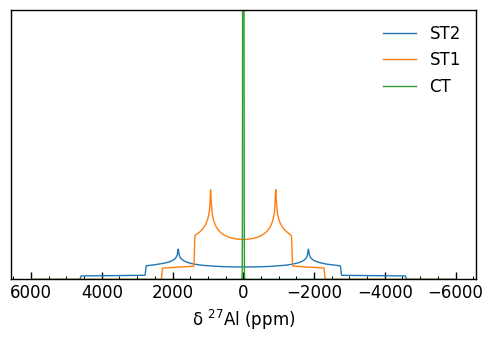

CT share of the total: 0.2571 (9/35 = 0.2571)


In [ ]:
lo, hi = nmr.quadrupolar_axis_limits(2.5, 2e6, 0.2, nu0_Al, transitions='all', fwhm=20)
axis = np.linspace(lo, hi, 8192)
full = nmr.quadrupolar_spectrum(2.5, 2e6, 0.2, nu0_Al, axis, transitions='all', order='exact', fwhm=20)

fig, ax = plt.subplots(figsize=(6, 3.5))
for group, spec in full['components'].items():
    ax.plot(axis, spec, lw=1, label=group)
ax.set_ylim(0, 3 * full['components']['ST1'].max())        # the CT goes off the top
ax.invert_xaxis(); ax.set_yticks([]); ax.legend(frameon=False)
ax.set_xlabel(nmr.NUC_label('27Al'))
plt.show()
print(f"CT share of the total: {full['components']['CT'].sum() / full['real_spec'].sum():.4f} (9/35 = {9/35:.4f})")

**Under MAS** the same call takes `mas_Hz`. The CT centreband carries the second-order MAS lineshape (narrowed, not removed, by MAS) at the isotropic quadrupolar shift; every spinning sideband is included, so with `transitions='all'` the satellites' sideband manifold appears too.

three MAS simulations in 1.84 s


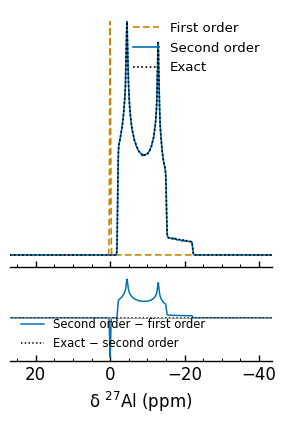

CT isotropic quadrupolar shift: -8.94 ppm (the MAS CT centre of gravity)


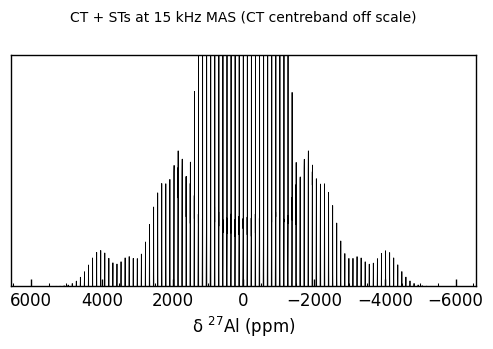

In [ ]:
import time
lo, hi = nmr.quadrupolar_axis_limits(2.5, 5e6, 0.2, nu0_Al, transitions='ct', fwhm=0.3)
axis = np.linspace(lo, hi, 4096)

t0 = time.perf_counter()
mas_orders = nmr.quadrupolar_order_comparison(2.5, 5e6, 0.2, nu0_Al, axis, mas_Hz=20e3,
                                              transitions='ct', fwhm=0.3)
print(f"three MAS simulations in {time.perf_counter() - t0:.2f} s")
nmr.plot_quadrupolar_orders(mas_orders, nuclide='27Al')
plt.show()

shift = nmr.quadrupolar_ct_isotropic_shift_Hz(2.5, 5e6, 0.2, nu0_Al) / nu0_Al * 1e6
print(f"CT isotropic quadrupolar shift: {shift:.2f} ppm (the MAS CT centre of gravity)")

# CT + satellites under MAS: the ST sideband manifold spans the static ST pattern
lo, hi = nmr.quadrupolar_axis_limits(2.5, 2e6, 0.2, nu0_Al, transitions='all', fwhm=3)
axis = np.linspace(lo, hi, 65536)
mas_all = nmr.quadrupolar_spectrum(2.5, 2e6, 0.2, nu0_Al, axis, mas_Hz=15e3, transitions='all', fwhm=3)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(axis, mas_all['real_spec'], color='k', lw=0.6)
ax.set_ylim(0, 0.04 * mas_all['real_spec'].max())          # zoom in on the ST sidebands
ax.set_title('CT + STs at 15 kHz MAS (CT centreband off scale)', fontsize=10)
ax.invert_xaxis(); ax.set_yticks([]); ax.set_xlabel(nmr.NUC_label('27Al'))
plt.show()

For a single crystallite (or a list of them), `nmr.quadrupolar_transition_frequencies` returns every transition's frequency offset and intensity at any level of theory -- useful to see the orders' contributions directly, orientation by orientation:

In [ ]:
theta, phi = np.deg2rad(40), np.deg2rad(25)        # B0 direction in the EFG frame
for order in ('first', 'second', 'exact'):
    f = nmr.quadrupolar_transition_frequencies(2.5, 5e6, 0.2, nu0_Al, theta, phi, order=order)
    print(f"{order:>6}: " + ", ".join(f"{lab} {nu/1e3:+9.3f} kHz" for lab, nu in zip(f['label'], f['offset_Hz'][0])))

 first: +3/2↔+5/2  -610.192 kHz, +1/2↔+3/2  -305.096 kHz, −1/2↔+1/2    -0.000 kHz, −3/2↔−1/2  +305.096 kHz, −5/2↔−3/2  +610.192 kHz
second: +3/2↔+5/2  -602.747 kHz, +1/2↔+3/2  -305.738 kHz, −1/2↔+1/2    -3.338 kHz, −3/2↔−1/2  +304.454 kHz, −5/2↔−3/2  +617.637 kHz
 exact: +3/2↔+5/2  -602.726 kHz, +1/2↔+3/2  -305.730 kHz, −1/2↔+1/2    -3.338 kHz, −3/2↔−1/2  +304.445 kHz, −5/2↔−3/2  +617.615 kHz


### 3.4 Combined Hamiltonian: CSA, quadrupolar and J on the same site

Real sites often have more than one anisotropic interaction: a quadrupolar nucleus with a sizeable CSA, J-coupled to a neighbour. Rather than one function per combination, a **`Site`** is a nucleus with an isotropic shift, to which interactions are *added*:

```python
site = (nmr.Site('27Al', delta_iso=12, label='Al(1)', amount=1, fwhm=0.5)
        .add_quadrupolar(C_Q=4.2, eta_Q=0.35)              # MHz
        .add_csa(aniso=60, asym=0.2, euler=(0, 90, 0))     # ppm; degrees
        .add_jcoupling('31P', n=2, J_Hz=300))              # any number of J groups
```

and `nmr.simulate_combined(sites, ppm_axis, larmor_Hz, mas_Hz=..., order=..., transitions=...)` simulates any number of such sites, static or MAS, with everything each site has.

* **One CSA and one EFG per site**, any number of J groups; a quadrupolar interaction only for I ≥ 1. `site.add('csa', ...)`, `site.remove('jcoupling')`, `site.to_dict()` / `nmr.Site.from_dict(...)` and `nmr.sites_to_json` round-trip a site exactly.
* **Physics.** Contributions add: CSA to first order (its higher orders and CSA–quadrupolar cross terms are ≲10⁻⁶ of the CSA), the quadrupolar part at the chosen `order`, and J as the heteronuclear, weak-coupling multiplet (natural abundance included). Homonuclear, strongly coupled systems need `nmr.spin_system_spectrum` instead.
* **Euler angles.** The CSA sits in the EFG frame as $D = R\,\mathrm{diag}(\delta_{xx},\delta_{yy},\delta_{zz})\,R^T$ with $R = R_z(\alpha)R_y(\beta)R_z(\gamma)$ (active, ZYZ, degrees): **β and α are the polar angles of the CSA's unique axis (δ<sub>zz</sub>) in the EFG frame**, γ turns the CSA about it. All zero: coincident tensors. Other programs use other conventions -- check before copying angles across.
* **Powder average.** One octant is used only when that is exact (no CSA, or a CSA whose axes coincide with the EFG's); a tilted CSA breaks the symmetry and the full sphere is used automatically (the log says so).
* `amount` is the relative number of nuclei (all transitions), so site ratios stay quantitative when only the CT is simulated.

Adding one interaction at a time shows what each does to a 27Al CT, static and at 15 kHz MAS:

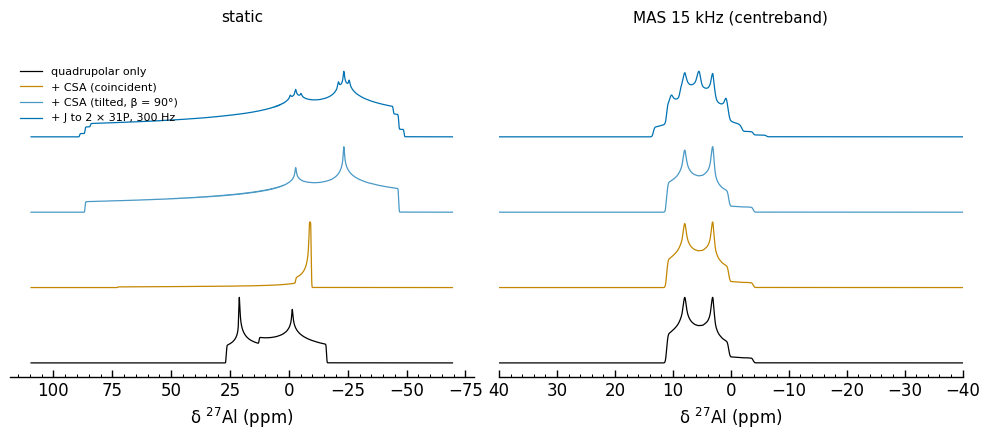

Site(Q (27Al, I = 2.5): δiso 12 ppm; quadrupolar C_Q 4.2 MHz, η_Q 0.35; CSA Δ 60 ppm, η 0.2 at Euler (0, 90, 0)°; J to 2×31P 300 Hz; amount 1, FWHM 0.4 ppm gaussian)


In [ ]:
base = dict(delta_iso=12, fwhm=0.4)
steps = {
    'quadrupolar only':        nmr.Site('27Al', label='Q', **base).add_quadrupolar(4.2, 0.35),
    '+ CSA (coincident)':      nmr.Site('27Al', label='Q', **base).add_quadrupolar(4.2, 0.35).add_csa(60, 0.2),
    '+ CSA (tilted, β = 90°)': nmr.Site('27Al', label='Q', **base).add_quadrupolar(4.2, 0.35).add_csa(60, 0.2, euler=(0, 90, 0)),
    '+ J to 2 × 31P, 300 Hz':  nmr.Site('27Al', label='Q', **base).add_quadrupolar(4.2, 0.35).add_csa(60, 0.2, euler=(0, 90, 0))
                                   .add_jcoupling('31P', n=2, J_Hz=300),
}
from opennmr.plotting.accessibility import ordered_qualitative_colours
colours = ordered_qualitative_colours('okabe_ito')
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, mas in zip(axes, (0.0, 15e3)):
    lo, hi = nmr.combined_axis_limits(list(steps.values())[-1], nu0_Al, transitions='ct', mas_Hz=mas)
    x = np.linspace(lo, hi, 16384)
    for k, (name, site) in enumerate(steps.items()):
        spec = nmr.simulate_combined(site, x, nu0_Al, mas_Hz=mas, transitions='ct')
        shown = (x > -40) & (x < 40) if mas else slice(None)
        y = spec['real_spec'] / spec['real_spec'][shown].max()
        ax.plot(x, y + 1.15 * k, lw=0.9, color=colours[k], label=name)
    if mas:
        ax.set_xlim(40, -40)       # the centreband; the sidebands (±115 ppm) are in the result too
    else:
        ax.invert_xaxis()
    ax.set_yticks([]); ax.set_xlabel(nmr.NUC_label('27Al'))
    for side in ('left', 'right', 'top'):
        ax.spines[side].set_visible(False)
    ax.set_title('static' if not mas else f'MAS {mas/1e3:g} kHz (centreband)', fontsize=11)
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
plt.tight_layout(); plt.show()
print(steps['+ J to 2 × 31P, 300 Hz'])

Several sites are simply a list. `nmr.plot_combined` draws the total and each site (`xlims` to show just the centreband when the axis also holds sidebands); the result also holds every site's spectrum (`'sites'`) and each site's transition groups (`'components'`), plus a `'log'` listing every site and setting. `nmr.combined_to_python` writes the notebook code that reproduces a simulation -- the GUI's **Simulate › Combined Hamiltonian** section offers the same thing as *Copy as Python*, so a simulation built by clicking can be rerun, changed or fitted here.

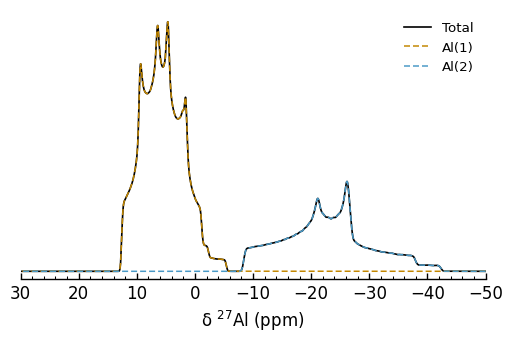

Al(1) (27Al, I = 2.5): δiso 12 ppm; quadrupolar C_Q 4.2 MHz, η_Q 0.35; CSA Δ 60 ppm, η 0.2; J to 1×31P 400 Hz; amount 2, FWHM 0.4 ppm gaussian
Al(2) (27Al, I = 2.5): δiso -8 ppm; quadrupolar C_Q 6 MHz, η_Q 0.7; amount 1, FWHM 0.6 ppm gaussian
MAS 20 kHz, nu0 = 130.4245 MHz, quadrupolar second-order, transitions ct, Al(1): 5797 orientations (octant), Al(2): 5797 orientations (octant).

import numpy as np
from opennmr.notebook.combined_hamiltonian import Site, simulate_combined

sites = [
    Site('27Al', delta_iso=12.0, label='Al(1)', amount=2.0, fwhm=0.4, lineshape='gaussian')
        .add_quadrupolar(C_Q=4.2, eta_Q=0.35)
        .add_csa(aniso=60.0, asym=0.2, convention='Haeberlen', euler=(0.0, 0.0, 0.0))
        .add_jcoupling('31P', n=1, J_Hz=400.0),
    Site('27Al', delta_iso=-8.0, label='Al(2)', amount=1.0, fwhm=0.6, lineshape='gaussian')
        .add_quadrupolar(C_Q=6.0, eta_Q=0.7),
]
ppm_axis = np.linspace(-226.97135105449846, 216.9271392306646, 16384)
spec = simulate_combined(s

In [ ]:
sites = [
    nmr.Site('27Al', 12, label='Al(1)', amount=2, fwhm=0.4).add_quadrupolar(4.2, 0.35)
        .add_csa(60, 0.2).add_jcoupling('31P', n=1, J_Hz=400),
    nmr.Site('27Al', -8, label='Al(2)', amount=1, fwhm=0.6).add_quadrupolar(6.0, 0.7),
]
lo, hi = nmr.combined_axis_limits(sites, nu0_Al, transitions='ct', mas_Hz=20e3)
x = np.linspace(lo, hi, 16384)
two_sites = nmr.simulate_combined(sites, x, nu0_Al, mas_Hz=20e3, transitions='ct')
nmr.plot_combined(two_sites, nuclide='27Al', pl_width=6, pl_height=3.5, xlims=(-50, 30))
plt.show()
print(two_sites['log'])
print()
print(nmr.combined_to_python(sites, x, larmor_Hz=nu0_Al, mas_Hz=20e3, transitions='ct'))

## 4. Fitting Chemical Shift Anisotropy


CSA FIT REPORT (Haeberlen convention, 1 site)

Parameters:
------------------------------------------------------------
  Site 1: d_iso      = 0.335792 ± 0.000116
  Site 1: Delta      = -110.113473 ± 0.192936
  Site 1: eta        = 0.909884 ± 0.006618
  Site 1: fwhm       = 0.633320 ± 0.000359
  Site 1: amplitude  = 50202088545.399689 ± 19562628.386793
  Site 1: pv_mix_eta = 0.509251 ± 0.001633
  b0                 = -56716373.330496 (fixed)
  b1                 = -168.849047 (fixed)

Fit quality:
------------------------------------------------------------
RMSE          : 8.027980e+07
Chi^2         : 8.580604e+20
Reduced Chi^2 : 6.445234e+15



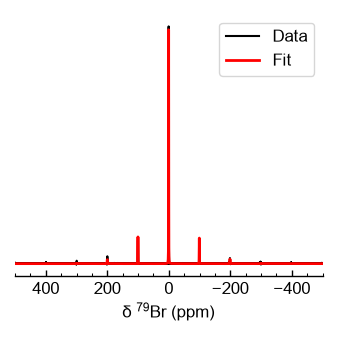

In [15]:
# KBr reference spectrum, 79Br, 2.5 mm HX probe, VT, 800 MHz
spec_to_fit = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_79Br_KBr_ref_VT_20260226\2"

peak_defs = {"type": "pseudo-voigt", "d_iso": 0.5, "span_or_Delta": -100, "skew_or_eta": 0.8, "fwhm": 0.5, "eta" : 0.5,
             "fixed": {"d_iso": False, "span_or_Delta": False, "skew_or_eta": False, "fwhm": False},}

csa_fit_test_KBr = nmr.NMRCSAFitWorkflow(
                                        spec_to_fit,
                                        p0=peak_defs,
                                        static=False,
                                        normalise=False,
                                        larmor_Hz=None,
                                        mas_Hz=20000,
                                        fit_regions=[(-1000, 1000)],
                                        show_plot=True,
                                        show_report=True,
                                        powder_scheme='zcw',
                                        n_zcw=320,
                                        xlims=[500,-500]
                                    )

Note: lineshape='gaussian' has no Gaussian/Lorentzian mixing to fit -- forcing every site's eta fixed (0.0).

CSA FIT REPORT (Haeberlen convention, 2 sites)

Parameters:
------------------------------------------------------------
  Site 1: d_iso      = -5.706610 ± 0.037559
  Site 1: Delta      = -188.392185 ± 2.369436
  Site 1: eta        = 0.546319 ± 0.070878
  Site 1: fwhm       = 8.155294 ± 0.051248
  Site 1: amplitude  = 17101193429.402046 ± 80354355.766962
  Site 1: pv_mix_eta = 0.000000 (fixed)
  Site 2: d_iso      = 0.323019 ± 0.040088
  Site 2: Delta      = -197.728814 ± 4.622997
  Site 2: eta        = 1.000000 ± 0.085786
  Site 2: fwhm       = 6.226352 ± 0.050323
  Site 2: amplitude  = 9806595292.580448 ± 150093813.149651
  Site 2: pv_mix_eta = 0.000000 (fixed)
  b0                 = 199786498.886274 (fixed)
  b1                 = 16358.649507 (fixed)

Fit quality:
------------------------------------------------------------
RMSE          : 1.086433e+08
Chi^2         : 7.2177

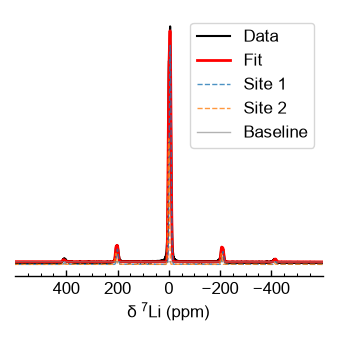

In [11]:
spec_to_fit = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\1"

# peak_defs = {"d_iso": 0.5, "span_or_Delta": -100, "skew_or_eta": 0.8, "fwhm": 0.5,
#              "fixed": {"d_iso": False, "span_or_Delta": False, "skew_or_eta": False, "fwhm": False},}

peak_defs = [{"label": "Site 1", "type": "pseudo-voigt", "d_iso": -5.693, "fwhm": 7.617, "eta": 0.350, "span_or_Delta": -200, "skew_or_eta": 0.8, "fixed": {"d_iso": True, "fwhm": True, "eta": True, "span_or_Delta": False, "skew_or_eta": False, "fwhm": False}},
             {"label": "Site 2", "type": "pseudo-voigt", "d_iso": -0.005, "fwhm": 5.283, "eta": 0.799, "span_or_Delta": -200, "skew_or_eta": 1.0, "fixed": {"d_iso": True, "fwhm": True, "eta": True, "span_or_Delta": False, "skew_or_eta": True,  "fwhm": False}}]

csa_fit_test_KBr = nmr.NMRCSAFitWorkflow(
                                        spec_to_fit,
                                        p0=peak_defs,
                                        static=False,
                                        normalise=False,
                                        larmor_Hz=None,
                                        mas_Hz=40000,
                                        fit_regions=[(-600, 600)],
                                        baseline_regions=[(50, 150), (-150, -50)],
                                        show_plot=True,
                                        show_report=True,
                                        show_components=True,
                                        powder_scheme='zcw',
                                        n_zcw=2000
                                    )
# From pseudo-voigt fit of isotropic only:

# Peak 1 (pseudo-voigt):
#   shift     = -5.692844 ± 0.011131
#   fwhm      = 7.617438 ± 0.024107
#   amplitude = 16968155704.917402 ± 0.001772
#   eta       = 0.350123 ± 0.006927
#   integral (raw) = 153605652729.4409
#   integral (%)    = 65.42

# Peak 2 (pseudo-voigt):
#   shift     = -0.005240 ± 0.011286
#   fwhm      = 5.283234 ± 0.026498
#   amplitude = 11128515685.187311 ± 0.002688
#   eta       = 0.798988 ± 0.013951
#   integral (raw) = 81186106803.0095
#   integral (%)    = 34.58

## 4.2 Fitting J-Coupled Spectra

`nmrtools.jcoupling_fitting` fits the multiplet simulator from §3.2 (`jcoupled_spectrum`) against an experimental spectrum, the same way `nmrtools.csa_fitting` (§4) fits the CSA simulator -- see the module's own docstring for the full picture. In short: for each chemical site you give a fixed *coupling topology* (which partner nuclide(s), and how many equivalent ones, `n`) plus a starting guess for each J; only the continuous parameters -- each J, the site's shift, linewidth, and amplitude -- are actually fitted. As in §3.2 and §9's lower-level pieces, these are not re-exported at the top level, so import them directly from the submodule.

In [2]:
from opennmr.notebook.jcoupling_fitting import (
    fit_jcoupling_spectrum, evaluate_jcoupling_fit,
    print_jcoupling_fit_report, NMR1dplot_with_jcoupling_fit,
    NMRJCouplingFitWorkflow,
)


### 4.2.1 (Toy example only) Building a synthetic spectrum to fit

As in §6.3, in real use you'd load an experimental spectrum with `nmr.NMR1dimport(datapath)` instead. `fit_jcoupling_spectrum` only needs a dict with the same keys `NMR1dimport` returns: `'x_ppm'`, `'real_spectrum'`, and `'SFO1'` (MHz). Here we build one by hand from `multi_site_jcoupled_spectrum` plus some noise, standing in for a real 13C spectrum with a CH3 (coupled to its own 3 protons) and a CH coupled to 2 further protons and a directly-bonded 31P.

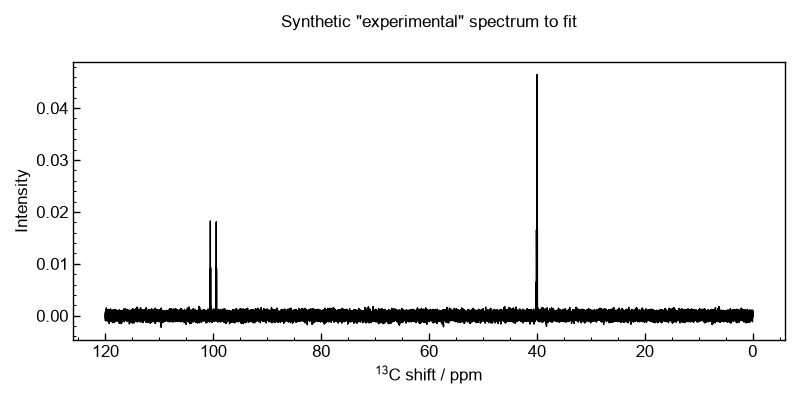

In [3]:
np.random.seed(0)

BF1, SFO1, nuclide = nmr.compute_BF1_SFO1('13C', B0_tesla=11.74)  # 500 MHz (1H) field
larmor_Hz = SFO1 * 1e6

true_sites = [
    {'ppm': 40.0, 'relative_intensity': 1.0, 'fwhm': 0.01,
     'couplings': [{'nuclide': '1H', 'n': 3, 'J_Hz': 7.2}]},           # CH3
    {'ppm': 100.0, 'relative_intensity': 0.6, 'fwhm': 0.01,
     'couplings': [
         {'nuclide': '1H',  'n': 2, 'J_Hz': 6.8},                     # CH, 2x vicinal 1H
         {'nuclide': '31P', 'n': 1, 'J_Hz': 138.0},                   # CH, 1JCP
     ]},
]

ppm_axis = np.linspace(0, 120, 60001)
truth = nmr.simulations.multi_site_jcoupled_spectrum(true_sites, larmor_Hz, ppm_axis, lineshape='lorentzian')

noise = np.random.normal(scale=0.01 * truth['real_spec'].max(), size=ppm_axis.shape)

experimental_spectrum = {
    'x_ppm': ppm_axis,
    'real_spectrum': truth['real_spec'] + noise,
    'SFO1': SFO1,
    'nuclide': '13C',
}

plt.figure(figsize=(8, 4))
plt.plot(experimental_spectrum['x_ppm'], experimental_spectrum['real_spectrum'], 'k-', lw=1)
plt.xlabel('$^{13}$C shift / ppm')
plt.ylabel('Intensity')
plt.title('Synthetic "experimental" spectrum to fit')
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()


### 4.2.2 Set up the fit and run it

`p0` is a list of sites (see §4's multi-site CSA `p0` for the same pattern): each needs a `center_ppm`, `fwhm`, and `couplings` (topology + starting J). A site with more than one coupling group -- the CH here, coupled to both 1H and 31P -- is exactly the case the module docstring flags as worth giving a `bounds['center_ppm']` window: without one, a so-so starting J can let the whole site drift to an unphysical shift while chasing a marginally better residual elsewhere on the axis, since the model is cheap to re-evaluate anywhere. `amplitude` is left out here and estimated automatically from the data near each `center_ppm`.

In [4]:
p0 = [
    {'label': 'CH3', 'center_ppm': 40.0, 'fwhm': 0.02,
     'bounds': {'center_ppm': (39, 41)},
     'couplings': [{'nuclide': '1H', 'n': 3, 'J_Hz': 7.0}]},
    {'label': 'CH', 'center_ppm': 100.0, 'fwhm': 0.02,
     'bounds': {'center_ppm': (99, 101)},
     'couplings': [
         {'nuclide': '1H',  'n': 2, 'J_Hz': 7.0},
         {'nuclide': '31P', 'n': 1, 'J_Hz': 137.0},
     ]},
]

popt, pcov_free, is_free, scale, fit_info = nmr.jcoupling_fitting.fit_jcoupling_spectrum(
    experimental_spectrum, p0, larmor_Hz=larmor_Hz, lineshape='lorentzian',
)


### 4.2.3 Report and plot

`print_jcoupling_fit_report` wants the full (not free-only) covariance matrix -- `expand_pcov`, same lower-level helper used for CSA/peak fits (§2, §4), is not re-exported at the top level either.

In [5]:
from opennmr.notebook.fitting import expand_pcov

pcov = expand_pcov(pcov_free, is_free, len(popt))

print_jcoupling_fit_report(
    experimental_spectrum['x_ppm'], experimental_spectrum['real_spectrum'],
    popt, pcov, is_free, fit_info,
)



J-COUPLING FIT REPORT (2 sites, lorentzian lineshape)

CH3:
------------------------------------------------------------
  center_ppm                  = 39.999988 ± 0.000024
  J_1 (3x1H)                  = 7.201500 ± 0.004441
  fwhm                        = 0.010094 ± 0.000065
  amplitude                   = 0.046109 ± 0.000218
  integral (raw)              = 0.0020
  integral (%)                = 62.37

CH:
------------------------------------------------------------
  center_ppm                  = 100.000022 ± 0.000052
  J_1 (2x1H)                  = 6.805577 ± 0.011280
  J_2 (1x31P)                 = 137.990853 ± 0.013066
  fwhm                        = 0.010244 ± 0.000144
  amplitude                   = 0.018049 ± 0.000189
  integral (raw)              = 0.0012
  integral (%)                = 37.63

Fit quality:
------------------------------------------------------------
RMSE          : 4.602417e-04
Chi^2         : 1.270956e-02
Reduced Chi^2 : 2.118613e-07



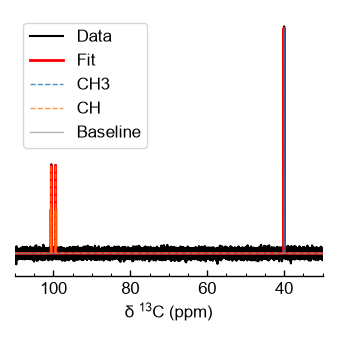

In [6]:
fig, ax = NMR1dplot_with_jcoupling_fit(
    experimental_spectrum, popt, fit_info,
    show_components=True, xlims=[110, 30],
)
plt.show()


### 4.2.3b Reporting in organic-chemistry notation

`print_jcoupling_fit_report(..., chemist_notation=True)` adds one extra line per site formatted the way an experimental section conventionally reports a multiplet -- e.g. `(ddd, 3J(C-F) = 36.3 Hz, 2J(C-H) = 11.0 Hz, 3J(C-H) = 4.2 Hz)`. Each coupling *group* in `p0` contributes one multiplicity letter (from its own number of lines), largest-|J| first by default. Give a group a `bond_label` (e.g. `'3J(C-F)'`) for a proper bond-counted label; without one you still get a correct multiplicity/J, just with a generic label (`'J(C-F)'`, no bond count -- that's chemical-structure knowledge this module has no way to infer on its own). You can also call `jcoupling_chemist_notation` directly if you want the string without the rest of the report.

In [7]:
# Re-fit the CH site alone with bond-labelled coupling groups, purely
# to demonstrate the notation option (same idea as 4.2.2, just with
# `bond_label` added to each group):
p0_labelled = [
    {'label': 'CH', 'center_ppm': 100.0, 'fwhm': 0.02,
     'bounds': {'center_ppm': (99, 101)},
     'couplings': [
         {'nuclide': '1H',  'n': 2, 'J_Hz': 7.0,   'bond_label': '3J(C-H)'},
         {'nuclide': '31P', 'n': 1, 'J_Hz': 137.0, 'bond_label': '1J(C-P)'},
     ]},
]

popt_l, pcov_free_l, is_free_l, scale_l, fit_info_l = nmr.jcoupling_fitting.fit_jcoupling_spectrum(
    experimental_spectrum, p0_labelled, larmor_Hz=larmor_Hz, lineshape='lorentzian',
    fit_regions=[(90, 110)],
)
pcov_l = expand_pcov(pcov_free_l, is_free_l, len(popt_l))

nmr.jcoupling_fitting.print_jcoupling_fit_report(
    experimental_spectrum['x_ppm'], experimental_spectrum['real_spectrum'],
    popt_l, pcov_l, is_free_l, fit_info_l, chemist_notation=True,
)



J-COUPLING FIT REPORT (1 site, lorentzian lineshape)

CH:
------------------------------------------------------------
  center_ppm                  = 100.000022 ± 0.000053
  J_1 (2x1H)                  = 6.805578 ± 0.011353
  J_2 (1x31P)                 = 137.990853 ± 0.013136
  fwhm                        = 0.010244 ± 0.000145
  amplitude                   = 0.018049 ± 0.000190
  integral (raw)              = 0.0012
  integral (%)                = 100.00
  Notation: (dt, 1J(C-P) = 138.0 Hz, 3J(C-H) = 6.8 Hz)

Fit quality:
------------------------------------------------------------
RMSE          : 7.459684e-04
Chi^2         : 3.338868e-02
Reduced Chi^2 : 5.565337e-07



### 4.2.4 On real data: `NMRJCouplingFitWorkflow`

For a real Bruker dataset, skip building the dict by hand -- `NMRJCouplingFitWorkflow` is the end-to-end driver (import, fit, plot, report), exactly like `NMRCSAFitWorkflow` in §4:

In [ ]:
# spec_to_fit = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_13C_some_sample\1"
#
# jcoupling_fit_test = NMRJCouplingFitWorkflow(
#     spec_to_fit,
#     p0=p0,
#     larmor_Hz=None,          # taken from the dataset's own SFO1 if omitted
#     lineshape='lorentzian',
#     fit_regions=[(30, 110)],
#     show_plot=True,
#     show_report=True,
#     show_components=True,
# )


## 4.3 Fitting quadrupolar lineshapes

`nmr.fit_quadrupolar_spectrum` fits one or more quadrupolar sites (δ<sub>iso</sub>, C<sub>Q</sub> in **MHz**, η<sub>Q</sub>, FWHM, amplitude) to a 1D spectrum, static or MAS, with the simulator of §3.3 as the model -- the same fitter as the GUI's **Fit › Quadrupolar**. As for the CSA fits (§4), `bounds`/`fixed` can be global or per site, and a linear baseline is estimated and held (or fitted, `fit_baseline=True`).

What the data cannot tell you, and the report therefore says:

* **the sign of C<sub>Q</sub>** -- a lineshape depends on C<sub>Q</sub>² (second order), so |C<sub>Q</sub>| is reported;
* **δ<sub>iso</sub> and C<sub>Q</sub> separately**, when a CT is poorly resolved: the CT sits at δ<sub>iso</sub> plus a shift ∝ C<sub>Q</sub>²(1 + η<sub>Q</sub>²/3)/ν<sub>0</sub>. The report gives the CT centre of gravity and P<sub>Q</sub> = C<sub>Q</sub>√(1 + η<sub>Q</sub>²/3), which are well determined even then (a second field separates the two).

### 4.3.1 (Toy example only) a synthetic 27Al spectrum to fit

As in §4.2.1, in real use load a spectrum with `nmr.NMR1dimport(datapath)`; the fitter only needs `'x_ppm'`, `'real_spectrum'`, `'SFO1'` (MHz) and, to read the spin, `'nuclide'`. Here: a static CT, simulated *exactly* on a finer powder grid than the fit uses, plus noise.

In [ ]:
import time
nu0_Al = nmr.larmor_frequency_Hz('27Al', 11.7467)          # as in §3.3, so this section runs on its own
rng = np.random.default_rng(1)
x = np.linspace(60, -80, 4096)                  # descending, as NMR1dimport returns
true = dict(d_iso=12.0, C_Q=4.2, eta_Q=0.35, fwhm=0.8)
y = nmr.quadrupolar_spectrum(2.5, true['C_Q'] * 1e6, true['eta_Q'], nu0_Al, x[::-1], transitions='ct',
                             order='exact', delta_iso=true['d_iso'], fwhm=true['fwhm'],
                             n_zcw=46368)['normalised_real_spec'][::-1]
static_27Al = {'x_ppm': x, 'real_spectrum': 1000 * y + 10 * rng.standard_normal(x.size),
               'SFO1': nu0_Al / 1e6, 'nuclide': '27Al'}

### 4.3.2 Start from the data, fit, report

`estimate_quadrupolar_start` reads a starting C<sub>Q</sub> from the pattern's width (by matching simulations: the CT width scales as C<sub>Q</sub>²) and δ<sub>iso</sub> from its centre of gravity less the isotropic quadrupolar shift. It is a *start*: η<sub>Q</sub> is only guessed.

start: {'d_iso': 11.644, 'C_Q': 4.008, 'eta_Q': 0.5, 'fwhm': 0.847}


QUADRUPOLAR FIT REPORT
Quadrupolar fit: I = 2.5, nu0 = 130.425 MHz, static, second-order model, transitions CT, gaussian broadening, 1 site(s), 28657 orientations, window whole spectrum.

Site 1
  d_iso (ppm)     = 12.0007 ± 0.0023
  C_Q (MHz)       = 4.20016 ± 0.00032
  eta_Q           = 0.349959 ± 0.00017
  fwhm (ppm)      = 0.803453 ± 0.0065
  amplitude       = 999.935 ± 2.1
  P_Q (MHz)       = 4.28503 ± 0.00033
  CT c.o.g. (ppm) = 5.5242 ± 0.0025

R^2 = 0.99820   RMSE = 10.02   reduced chi^2 = 100.6
Sign of C_Q is not determined by a lineshape; |C_Q| is reported.


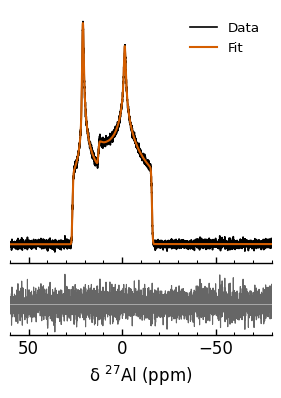

true: {'d_iso': 12.0, 'C_Q': 4.2, 'eta_Q': 0.35, 'fwhm': 0.8}


In [ ]:
start = nmr.estimate_quadrupolar_start(static_27Al, I=2.5, eta_Q=0.5)
print("start:", {k: round(v, 3) for k, v in start.items()})

popt, pcov_free, is_free, scale, info = nmr.fit_quadrupolar_spectrum(static_27Al, start)

from opennmr.notebook.fitting import expand_pcov
pcov = expand_pcov(pcov_free, is_free, len(popt))
xs = np.sort(static_27Al['x_ppm'])
y_fit = nmr.evaluate_quad_fit(xs, popt, info)
ys = static_27Al['real_spectrum'][np.argsort(static_27Al['x_ppm'])]
report = nmr.print_quadrupolar_fit_report(xs, ys, y_fit, popt, pcov, is_free, info)
fig, ax = nmr.NMR1dplot_with_quad_fit(static_27Al, popt, info)
plt.show()
print("true:", true)

### 4.3.3 The same under MAS -- and on real data

Under MAS pass `mas_Hz`. On real data, `nmr.NMRQuadFitWorkflow(datapath, p0=None, mas_Hz=...)` does import → start estimate → fit → report → plot in one call (`p0=None` estimates the start; pass a list of dicts for several sites, as in §4). Things to check before trusting a fit:

* the whole pattern -- and, under MAS, its sidebands -- inside the fit window; the report warns when the fitted pattern runs past it, or when the baseline was estimated on the pattern's tail (then give `baseline_regions` or `fit_baseline=True`);
* `order='second'` is accurate while ν<sub>Q</sub> ≪ ν<sub>0</sub>; the report warns when it is not (then use `order='exact'`);
* powder resolution: a fit with too few orientations absorbs powder "ripple" into a larger FWHM -- refit with a larger `n_zcw` to check.

d_iso (ppm)  11.9982 ± 0.0017
C_Q (MHz)    4.1989 ± 0.0005
eta_Q        0.3501 ± 0.0002
fwhm (ppm)   0.4977 ± 0.0027
P_Q = 4.2838 ± 0.0005 MHz,  CT centre of gravity = 5.526 ± 0.001 ppm
true: d_iso 12, C_Q 4.2, eta_Q 0.35, fwhm 0.5


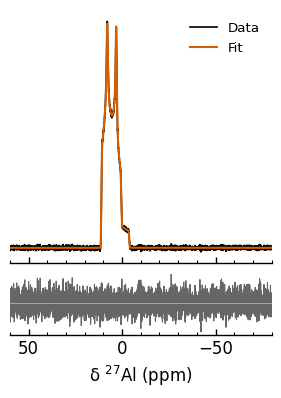

In [ ]:
rng = np.random.default_rng(2)
x = np.linspace(60, -80, 4096)
y = nmr.quadrupolar_spectrum(2.5, 4.2e6, 0.35, nu0_Al, x[::-1], mas_Hz=15e3, transitions='ct',
                             order='exact', delta_iso=12.0, fwhm=0.5, n_zcw=28657)['normalised_real_spec'][::-1]
mas_27Al = {'x_ppm': x, 'real_spectrum': 1000 * y + 5 * rng.standard_normal(x.size),
            'SFO1': nu0_Al / 1e6, 'nuclide': '27Al'}

start = nmr.estimate_quadrupolar_start(mas_27Al, I=2.5, mas_Hz=15e3)
popt, pcov_free, is_free, scale, info = nmr.fit_quadrupolar_spectrum(mas_27Al, start, mas_Hz=15e3)
pcov = expand_pcov(pcov_free, is_free, len(popt))
err = np.sqrt(np.diag(pcov))
for name, i in (('d_iso (ppm)', 0), ('C_Q (MHz)', 1), ('eta_Q', 2), ('fwhm (ppm)', 3)):
    print(f"{name:<12} {popt[i]:.4f} ± {err[i]:.4f}")
d = nmr.quadrupolar_derived(popt, pcov, info)[0]
print(f"P_Q = {d['P_Q']:.4f} ± {d['P_Q_err']:.4f} MHz,  CT centre of gravity = {d['delta_cg']:.3f} ± {d['delta_cg_err']:.3f} ppm")
print("true: d_iso 12, C_Q 4.2, eta_Q 0.35, fwhm 0.5")
fig, ax = nmr.NMR1dplot_with_quad_fit(mas_27Al, popt, info)
plt.show()

# On real data (replace the path with your experiment):
# fit_27Al = nmr.NMRQuadFitWorkflow(r"C:\path\to\27Al_MAS_experiment\1", p0=None, mas_Hz=15000,
#                                   fit_regions=[(-80, 60)], save_report=True, save_csv=True)

## 4.4 Fitting with the Combined Hamiltonian

`nmr.fit_combined(results, sites, ...)` fits any list of `Site`s (§3.4) -- so any mix of CSA, quadrupolar and J, static or MAS -- to a spectrum. The sites you pass are the starting model; `fit['sites']` are the fitted ones (ready to simulate, plot or refit).

**Parameter names** (per site; `nmr.site_parameter_names(site)` lists a site's own):

| name | what | free by default? |
|---|---|---|
| `delta_iso`, `amount`, `fwhm` | every site | yes |
| `eta` | Lorentzian fraction, pseudo-Voigt broadening only | yes |
| `aniso`, `asym` | CSA Δ/η (Haeberlen) or span/skew (Herzfeld-Berger) | yes |
| `alpha`, `beta`, `gamma` | CSA Euler angles in the EFG frame | **no** -- rarely determined by one 1D spectrum |
| `C_Q` (MHz), `eta_Q` | quadrupolar | yes |
| `J1`, `J2`, … | the site's J groups, in the order added | yes |

`fixed` removes names from the free set; `vary` replaces it. Both take a list (every site) or `{label: [names]}`; `bounds` takes `{name: (lo, hi)}` and/or `{label: {name: (lo, hi)}}`. Amounts are started by a non-negative least-squares fit of the starting shapes, so they need no guessing, and the reported **shares (%) are numbers of nuclei** (all transitions count, even for a CT-only fit) -- provided the excitation was non-selective.

The report gives every value with a 1σ error rounded to the digits it supports, the shares, and P<sub>Q</sub> and the CT centre of gravity for quadrupolar sites; it warns about parameters on a bound, strongly correlated pairs, a clipped window, a baseline estimated on the pattern, and a poor R².

### 4.4.1 What a spectrum does -- and does not -- determine

The example below is two 27Al sites: Al(1) with a quadrupolar coupling, a 60 ppm CSA and a 400 Hz J to one 31P; Al(2) quadrupolar only, at half the amount. The lesson of this example, found while testing it:

* **A fast-MAS CT spectrum pins down δ<sub>iso</sub>, C<sub>Q</sub>, η<sub>Q</sub>, J and the site ratio very precisely, but hardly the CSA**: at 20 kHz the CT's spinning sidebands hold < 1 % of the intensity, and Δ = +60/η = 0.2 and Δ = −26/η = 0 fit to within 0.3 % in χ². Fix (or ignore) the CSA there.
* **A static spectrum then determines the CSA**, once the quadrupolar parameters are fixed at their MAS values -- but a static powder lineshape is *multimodal*: started from the wrong sign of Δ the fit settles in a wrong minimum with a poor R². `nmr.fit_combined_multistart` fits from a grid of starts and keeps the best.

This two-step route (MAS for the quadrupolar parameters, static -- or slow MAS -- for the CSA) is the standard experimental strategy, and it is what the fit should follow too.

### 4.4.2 (Toy example only) two synthetic spectra of the same sample

In [ ]:
import time
nu0_Al = nmr.larmor_frequency_Hz('27Al', 11.7467)          # 130.42 MHz, as in §3.3
truth = [
    nmr.Site('27Al', 12, label='Al1', amount=2, fwhm=0.5).add_quadrupolar(4.2, 0.35)
        .add_csa(60, 0.2).add_jcoupling('31P', n=1, J_Hz=400),
    nmr.Site('27Al', -8, label='Al2', amount=1, fwhm=0.8).add_quadrupolar(6.0, 0.7),
]
def synthetic(mas_Hz, lo, hi, n, seed):
    rng = np.random.default_rng(seed)
    x = np.linspace(hi, lo, n)
    y = nmr.simulate_combined(truth, x[::-1], nu0_Al, mas_Hz=mas_Hz, transitions='ct',
                              order='exact', n_zcw=17711)['real_spec'][::-1]
    return {'x_ppm': x, 'real_spectrum': 1000 * y / y.max() + 4 * rng.standard_normal(n),
            'SFO1': nu0_Al / 1e6, 'nuclide': '27Al'}

mas_data = synthetic(20e3, -450, 450, 16384, seed=0)     # wide enough to hold the sidebands
static_data = synthetic(0.0, -150, 150, 8192, seed=1)

### 4.4.3 Step 1 -- the MAS spectrum: quadrupolar parameters, shifts, J and amounts

The starting model is deliberately off. The CSA is held at a guess (`fixed`), for the reason above.

fitted in 9.3 s
COMBINED-HAMILTONIAN FIT REPORT
Combined-Hamiltonian fit: MAS 20 kHz, nu0 = 130.4245 MHz, quadrupolar second-order, transitions ct, 2584 orientations, window whole spectrum, baseline estimated and held.
Al1 (27Al, I = 2.5): δiso 11.9948 ppm; quadrupolar C_Q 4.19993 MHz, η_Q 0.350278; CSA Δ 40 ppm, η 0.5; J to 1×31P 400.514 Hz; amount 616827, FWHM 0.502831 ppm gaussian
Al2 (27Al, I = 2.5): δiso -7.99241 ppm; quadrupolar C_Q 5.99996 MHz, η_Q 0.700877; amount 311160, FWHM 0.8088 ppm gaussian

Al1
  delta_iso (ppm)   = 11.9948 ± 0.0019
  amount            = 616827 ± 254
  fwhm (ppm)        = 0.5028 ± 0.0033
  aniso (ppm)       = 40 (fixed)
  asym              = 0.5 (fixed)
  alpha (deg)       = 0 (fixed)
  beta (deg)        = 0 (fixed)
  gamma (deg)       = 0 (fixed)
  C_Q (MHz)         = 4.19993 ± 0.00062
  eta_Q             = 0.35028 ± 0.00028
  J1 (Hz)           = 400.51 ± 0.25
  share (%)         = 66.469 ± 0.027
  P_Q (MHz)         = 4.28495 ± 0.00065
  CT c.o.g. (ppm)

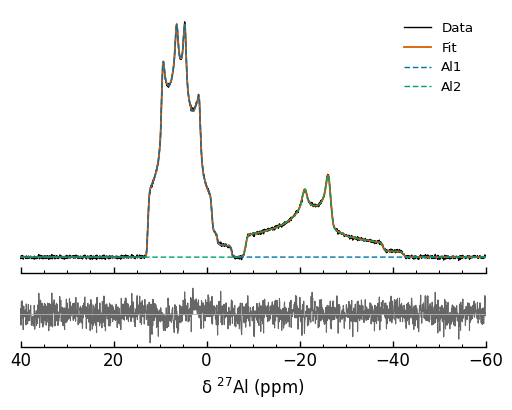

In [ ]:
start = [
    nmr.Site('27Al', 10, label='Al1', fwhm=1).add_quadrupolar(4.0, 0.5)
        .add_csa(40, 0.5).add_jcoupling('31P', n=1, J_Hz=350),
    nmr.Site('27Al', -5, label='Al2', fwhm=1).add_quadrupolar(5.5, 0.5),
]
t0 = time.perf_counter()
mas_fit = nmr.fit_combined(mas_data, start, mas_Hz=20e3, transitions='ct',
                           fixed={'Al1': ['aniso', 'asym']})
print(f"fitted in {time.perf_counter() - t0:.1f} s")
nmr.print_combined_fit_report(mas_fit)
nmr.plot_combined_fit(mas_fit, pl_width=6, pl_height=3.5, xlims=(-60, 40))
plt.show()

### 4.4.4 Step 2 -- the static spectrum: the CSA, with the MAS values fixed

`mas_fit['sites']` carry the MAS results; the static fit starts from them with δ<sub>iso</sub>, C<sub>Q</sub>, η<sub>Q</sub> and J fixed, and scans Δ over both signs and two η values. `screen_n_zcw` screens every start on a coarser powder set and refits only the best one at full resolution.

8 starts in 34 s
  Al1: aniso = 80, Al1: asym = 0.2         R² 0.9979
  Al1: aniso = 40, Al1: asym = 0.2         R² 0.9979
  Al1: aniso = 40, Al1: asym = 0.8         R² 0.9979
  Al1: aniso = 80, Al1: asym = 0.8         R² 0.9979
  Al1: aniso = -40, Al1: asym = 0.8        R² 0.9979
  Al1: aniso = -80, Al1: asym = 0.8        R² 0.4680
  Al1: aniso = -40, Al1: asym = 0.2        R² 0.2607
  Al1: aniso = -80, Al1: asym = 0.2        R² 0.2591
COMBINED-HAMILTONIAN FIT REPORT
Combined-Hamiltonian fit: static, nu0 = 130.4245 MHz, quadrupolar second-order, transitions ct, 28657 orientations, window whole spectrum, baseline estimated and held.
Al1 (27Al, I = 2.5): δiso 11.9948 ppm; quadrupolar C_Q 4.19993 MHz, η_Q 0.350278; CSA Δ 59.9809 ppm, η 0.200264; J to 1×31P 400.514 Hz; amount 693834, FWHM 0.501294 ppm gaussian
Al2 (27Al, I = 2.5): δiso -7.99241 ppm; quadrupolar C_Q 5.99996 MHz, η_Q 0.700877; amount 347292, FWHM 0.80314 ppm gaussian
Multi-start: 8 starts; 5 reached the best chi^2 (within 1

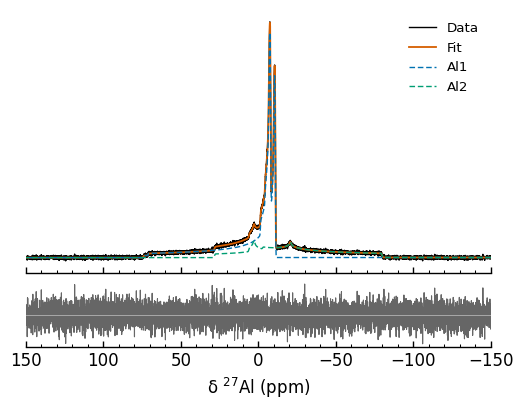

In [ ]:
t0 = time.perf_counter()
static_fit = nmr.fit_combined_multistart(
    static_data, mas_fit['sites'],
    starts={'Al1': {'aniso': [-80, -40, 40, 80], 'asym': [0.2, 0.8]}},
    screen_n_zcw=2584, transitions='ct', verbose=False,
    fixed={'Al1': ['delta_iso', 'C_Q', 'eta_Q', 'J1'], 'Al2': ['delta_iso', 'C_Q', 'eta_Q']})
print(f"{len(static_fit['starts'])} starts in {time.perf_counter() - t0:.0f} s")
for row in static_fit['starts']:
    print(f"  {row['start']:<40} R² {row['r2']:.4f}")
nmr.print_combined_fit_report(static_fit)
nmr.plot_combined_fit(static_fit, pl_width=6, pl_height=3.5)
plt.show()

### 4.4.5 On real data

`nmr.NMRCombinedFitWorkflow(datapath, sites, **fit_kwargs)` imports a processed Bruker spectrum, fits, prints the report and plots; `save_report=`, `save_csv=` and `fname=` write the report, the data/fit/sites/baseline table and the figure. Every keyword of `fit_combined` (`mas_Hz`, `transitions`, `order`, `fixed`, `vary`, `bounds`, `fit_regions`, `fit_baseline`, …) passes through.

```python
sites = [nmr.Site('27Al', 12, label='AlO6').add_quadrupolar(4.0, 0.4),
         nmr.Site('27Al', 65, label='AlO4').add_quadrupolar(6.0, 0.5)]
fit = nmr.NMRCombinedFitWorkflow(r"C:\path\to\27Al_MAS_experiment\1", sites,
                                 mas_Hz=15000, transitions='ct',
                                 save_report='fit_report.txt', save_csv='fit.csv', fname='fit.png')
refined = fit['sites']            # e.g. the start for a static or second-field fit
```

Before trusting a combined fit: read the warnings; check that fixing or freeing a parameter the data barely constrain (the CSA from fast MAS, Euler angles, a small J) does not move the others; scan starting values for static patterns; and for quantitative shares remember that CT intensities assume non-selective excitation.

## 5. pNMR Simulator: Bond Pathways

### 5.1 (Optional) inspect the raw neighbor-distance distribution first

This helps you choose sensible shell boundaries (`shell_bins`) before
committing to them below — look for the gaps in the sorted distances.

In [17]:
cif_filename = r"C:\Users\quark\OneDrive\Documents\Neutron\LIRO_Combined_Refinement\Refinement_Results_20250122\CIF_LRMO_C2m_disord.cif"

structure, site_data = nmr.read_cif_with_occupancies(
    cif_filename, atom_of_interest="Li", verbose=True
)

d = nmr.shell_distance_histogram(
    structure, site_data, "Li", max_r=6.0, ignore_species=["O", "O2-"]
)
# np.diff(d) will show the gaps that should become your shell boundaries
print(d[:20])

[2.71457736 2.71457736 2.71457736 2.71457736 2.71457736 2.71457736
 2.71457736 2.71457736 2.74773054 2.74773054 2.74773054 2.74773054
 2.74773054 2.74773054 2.74773054 2.74773054 2.85401211 2.85401211
 2.85401211 2.85401211]


c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\pnmr_simulator.py:86: UserWarning: Issues encountered while parsing CIF: 3 fractional coordinates rounded to ideal values to avoid issues with finite precision.
Skipping relative stoichiometry check because CIF does not contain formula keys.
  structures = parser.parse_structures(primitive=False)


### 5.2 Define shells, shift contributions, and nuclide/field, then simulate

- `shell_bins`: coordination shells around the site of interest, e.g. NN / NNN.
- `shift_dict`: ppm contribution per neighbor species, per shell. Species not
  listed (and vacancies, `'Va'`) contribute 0 by convention.
- `nuclide` / `B0_tesla`: used only for ppm<->Hz referencing (`BF1`, `SFO1`);
  independent of `atom_of_interest`, which is the *structural* site label.

In [18]:
shell_bins = [
    ("NN",  0.0, 3.10),
    ("NNN", 3.50, 4.20),
]

shift_dict = {
    "NN":  {"Mn": 250,  "Ru": -10, "Li": 0.0},
    "NNN": {"Mn": -60, "Ru": -3,  "Li": 0.0},
}

spectrum_dict, shift_table = nmr.generate_spectrum_dict(
    cif_filename=cif_filename,
    atom_of_interest="Li",
    shell_bins=shell_bins,
    shift_dict=shift_dict,
    ignore_species=["O", "O2-"],
    nuclide="7Li",
    B0_tesla=9.4,          # simulated/target spectrometer field, in Tesla
    broadening=1.0,        # Gaussian sigma, ppm
    xlims=[-1000, 2800],
    output_dir=None,       # defaults to <cif dir>/pnmr_simulation
    verbose=True,
)

print(spectrum_dict.keys())
print("nuclide:", spectrum_dict["nuclide"])
print("BF1 (MHz):", spectrum_dict["BF1"], " SFO1 (MHz):", spectrum_dict["SFO1"])
print("shift table + spectrum dict saved under:", spectrum_dict["path"])

shift_table.head()

dict_keys(['x_ppm', 'x_Hz', 'real_spectrum', 'normalised_real_spectrum', 'imag_spectrum', 'normalised_imag_spectrum', 'nuclide', 'BF1', 'SFO1', 'path'])
nuclide: 7Li
BF1 (MHz): 155.55543  SFO1 (MHz): 155.55543
shift table + spectrum dict saved under: C:\Users\quark\OneDrive\Documents\Neutron\LIRO_Combined_Refinement\Refinement_Results_20250122\pnmr_simulation


,Site,Config,NN_Li,NN_Ru,NNN_Ru,Total_shift,p,NNN_Mn,NNN_Li,NN_Mn
0,0,0,5,6.0,4.0,-72.0,1.050672e-07,0.0,0.0,0.0
1,0,1,5,6.0,3.0,-129.0,2.968331e-07,1.0,0.0,0.0
2,0,2,5,6.0,3.0,-69.0,1.169485e-06,0.0,1.0,0.0
3,0,3,5,6.0,2.0,-186.0,3.016737e-07,2.0,0.0,0.0
4,0,4,5,6.0,2.0,-126.0,2.670146e-06,1.0,1.0,0.0


### 5.3 Plot the simulated spectrum on its own

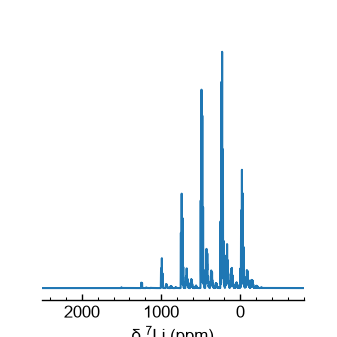

In [19]:
ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True, xlims=[2500,-800])
plt.show()
plt.tight_layout()

### 5.4 Compare against an experimental spectrum

Load (or already have) an experimental spectrum in the same dict shape —
e.g. from your Bruker-processing pipeline — and overlay it.

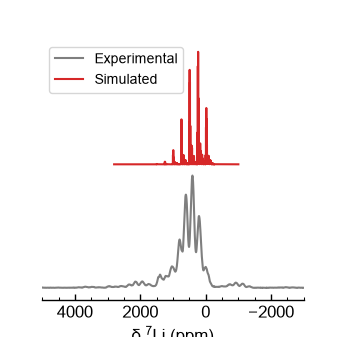

In [20]:
# experimental_dict = load_your_experimental_spectrum(...)
# Must have the same keys as spectrum_dict above.

experimental_dict = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\100MHz_UCSB\100_ENB_20230807_Li2Ru0p5Mn0p5O3_300123A_Pristine_7Li\991000")

ax = nmr.plot_comparison(spectrum_dict, experimental_dict, axis="ppm", channel="real", offset = 1.1)
ax.set_xlim([5000, -3000])
plt.show()
plt.tight_layout()

### 5.5 More complex example

[{'site_index': 0, 'coordinates': array([0., 0., 0.]), 'occupancies': [{'species': 'Na+', 'probability': 1.0}], 'contains Na+': True}, {'site_index': 1, 'coordinates': array([1.488615  , 0.85945227, 5.36493333]), 'occupancies': [{'species': 'Na+', 'probability': 1.0}], 'contains Na+': True}, {'site_index': 2, 'coordinates': array([2.22044605e-16, 1.71890454e+00, 1.07298667e+01]), 'occupancies': [{'species': 'Na+', 'probability': 1.0}], 'contains Na+': True}, {'site_index': 3, 'coordinates': array([0.    , 0.    , 8.0474]), 'occupancies': [{'species': 'Ni2+', 'probability': 0.25}, {'species': 'Mn3+', 'probability': 0.3}, {'species': 'Mn4+', 'probability': 0.2}, {'species': 'Fe3+', 'probability': 0.25}], 'contains Na+': False}, {'site_index': 4, 'coordinates': array([ 1.488615  ,  0.85945227, 13.41233333]), 'occupancies': [{'species': 'Ni2+', 'probability': 0.25}, {'species': 'Mn3+', 'probability': 0.3}, {'species': 'Mn4+', 'probability': 0.2}, {'species': 'Fe3+', 'probability': 0.25}], 

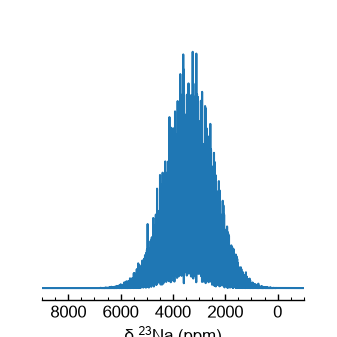

In [21]:
# "C:\Users\quark\OneDrive\Documents\Calculations\Pedro_Na_O3_Cathode\CIF_O3_NaNiMnFe_based_on_EntryWithCollCode19572.cif"

cif_filename = r"C:\Users\quark\OneDrive\Documents\Calculations\Pedro_Na_O3_Cathode\CIF_O3_NaNiMnFe_with_charges_based_on_EntryWithCollCode19572.cif"

structure, site_data = nmr.read_cif_with_occupancies(
    cif_filename, atom_of_interest="Na+", verbose=True
)

print(site_data)

d = nmr.shell_distance_histogram(
    structure, site_data, "Na+", max_r=6.0, ignore_species=["O", "O2-"]
)
# np.diff(d) will show the gaps that should become your shell boundaries
print(d[:20])

shell_bins = [
    ("NN",  0.0, 3.20),
    ("NNN", 3.80, 4.40),
]

shift_dict = {
    "NN":  {"Ni2+": -68, "Mn3+": 246, "Mn4+": 460, "Fe3+": 45, "Na+": 0.0},
    "NNN": {"Ni2+": 300, "Mn3+": 440, "Mn4+": -34, "Fe3+": 800, "Na+": 0.0},
}

spectrum_dict, shift_table = nmr.generate_spectrum_dict(
    cif_filename=cif_filename,
    atom_of_interest="Na+",
    shell_bins=shell_bins,
    shift_dict=shift_dict,
    ignore_species=["O", "O2-"],
    nuclide="23Na",
    B0_tesla=11.7,          # simulated/target spectrometer field, in Tesla
    broadening=1.0,        # Gaussian sigma, ppm
    xlims=[9000,-1000],
    output_dir=None,       # defaults to <cif dir>/pnmr_simulation
    verbose=True,
)

print(spectrum_dict.keys())
print("nuclide:", spectrum_dict["nuclide"])
print("BF1 (MHz):", spectrum_dict["BF1"], " SFO1 (MHz):", spectrum_dict["SFO1"])
print("shift table + spectrum dict saved under:", spectrum_dict["path"])

shift_table.head()

ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True)
plt.show()
plt.tight_layout()

### 5.6 Examining the shifts as a function of composition

We can also plot the shifts as a function of local composition, to make sense of the local interactions

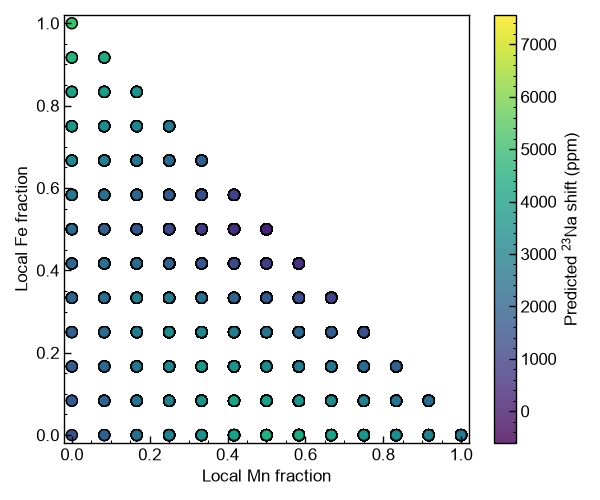

In [22]:
df = shift_table.copy()

# Total number of magnetic/transition-metal neighbours
tm_cols = [
    "NN_Ni2+", "NN_Mn4+", "NN_Mn3+", "NN_Fe3+",
    "NNN_Ni2+", "NNN_Mn4+", "NNN_Mn3+", "NNN_Fe3+",
]

df["TM_total"] = df[tm_cols].sum(axis=1)

df["Mn_fraction"] = (
    df["NN_Mn3+"] + df["NNN_Mn3+"] + df["NN_Mn4+"] + df["NNN_Mn4+"]
) / df["TM_total"]

df["Fe_fraction"] = (
    df["NN_Fe3+"] + df["NNN_Fe3+"]
) / df["TM_total"]

fig, ax = plt.subplots(figsize=(6, 5))

sc = ax.scatter(
    df["Mn_fraction"],
    df["Fe_fraction"],
    c=df["Total_shift"],
    s=60, #1000 * df["p"],
    cmap="viridis",
    edgecolor="k",
    alpha=0.8,
)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Predicted $^{23}$Na shift (ppm)")

ax.set_xlabel("Local Mn fraction")
ax.set_ylabel("Local Fe fraction")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.show()

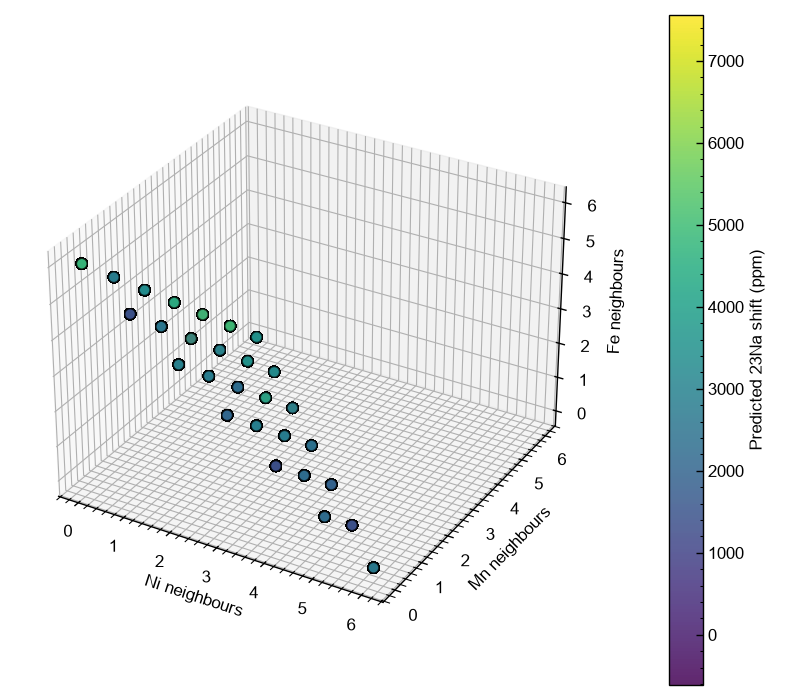

In [23]:
df = shift_table.copy()

# Combine NN and NNN neighbours
df["Ni_NN"] = df["NN_Ni2+"] #+ df["NNN_Ni2+"]
df["Mn_NN"] = df["NN_Mn3+"] + df["NN_Mn4+"] #+ df["NNN_Mn3+"] + df["NNN_Mn4+"] 
df["Fe_NN"] = df["NN_Fe3+"] #+ df["NNN_Fe3+"]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df["Ni_NN"],
    df["Mn_NN"],
    df["Fe_NN"],
    c=df["Total_shift"],
    s= 60, #1500 * df["p"],
    cmap="viridis",
    edgecolor="k",
    alpha=0.85,
)

ax.set_xlabel("Ni neighbours")
ax.set_ylabel("Mn neighbours")
ax.set_zlabel("Fe neighbours")

cbar = fig.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("Predicted 23Na shift (ppm)")

plt.tight_layout()
plt.show()

## 6. Fitting pNMR Spectra Against CIF-Predicted Environments

Section 8 *simulates* a spectrum from a CIF: it enumerates every
disordered local environment, works out its shift from `shift_dict`, and
broadens the result into a lineshape. This section goes the other
direction -- it *fits* an experimental spectrum, using the CIF prediction
to decide where the peaks should be, so that a peak's centre comes from
the structure rather than from a guess. Only width, intensity, and (for
pseudo-Voigt) the Gaussian/Lorentzian mixing fraction are fitted by
default; the shift is fixed at its CIF-predicted value unless you
explicitly ask for it to float.

The building blocks, used in this order:

1. **`predict_environments`** -- enumerate every (site, disorder-config)
   shift the CIF predicts, unbroadened.
2. **`group_environments`** -- merge shifts too close together to resolve
   into single candidate peaks, remembering which environments went into
   each one.
3. **`fit_predicted_spectrum`** -- filter those groups against your data
   (region of interest, signal-to-noise) and fit one peak per surviving
   group -- the *maximal* fit, one peak per CIF environment group.
4. **`merge_low_integral_peaks` / `merge_groups_to_picks`** -- simplify a
   crowded maximal fit into far fewer peaks, automatically or by hand.
5. **`refit_merged_groups`** -- re-fit the simplified peak set, this time
   with each centre free to move.
6. **`fit_cif_envelope`** -- a different strategy entirely: fit the whole
   predicted shift distribution as one continuous envelope, for CIFs
   whose disorder is too combinatorially rich to resolve into discrete
   peaks at all.

All of it lives in `pnmr_fit`, imported below as `pf`.

In [24]:
import numpy as np
import pandas as pd
from pymatgen.core import Structure, Lattice

from opennmr.notebook import pnmr_fit as pf

pd.set_option("display.width", 140)
np.random.seed(0)


### 6.1 `predict_environments` -- enumerate every disordered environment

The same underlying calculation as Section 8's `generate_spectrum_dict` /
`build_shift_table` -- read the CIF's site occupancies, find neighbours
by shell, enumerate every disorder configuration, and total up the shift
from `shift_dict` -- but returned as a flat, **unbroadened** table (no
spectrum built here) with two extra columns:

- `label` -- compact string, nonzero counts only, e.g. `"NN:5Fe+1Mn NNN:6Fe"`
- `composition` -- a dict `{shell: {species: count, ...}, ...}` listing
  *every* species in `shift_dict[shell]`, including zeros -- used later
  for the full per-peak breakdown (Section 10.10)

For this section we'll build a small toy CIF to work with first --
a rocksalt-like lattice with a Li site and a Fe/Mn-disordered metal site
(70:30), a stand-in for something like the mixed-metal site in an
LFP-type material -- so the whole workflow is reproducible without
needing your own CIF/spectrum yet. A worked example on real data follows
in 10.12-10.13.

In [38]:
# ---------------------------------------------------------------------------
# Toy CIF: rocksalt-like lattice, Li site + Fe/Mn-disordered metal site
# ---------------------------------------------------------------------------
lattice = Lattice.cubic(4.0)
struct = Structure(lattice, ["Li", "Fe", "O"], [[0, 0, 0], [0.5, 0.5, 0.5], [0.5, 0, 0]])
struct.replace(1, {"Fe": 0.7, "Mn": 0.3})
struct.make_supercell([2, 2, 2])
struct.to(filename="toy.cif")

shell_bins = [("NN", 0.0, 3.7), ("NNN", 3.7, 4.2)]
shift_dict = {
    "NN": {"Fe": 150.0, "Mn": 400.0},   # ppm per NN Fe / Mn
    "NNN": {"Fe": 8.0, "Mn": 20.0},     # ppm per NNN Fe / Mn (Li has no shift
                                        # entry, so it contributes 0 -- see
                                        # the printed warning when this runs)
}

predicted = pf.predict_environments("toy.cif", "Li", shell_bins, shift_dict,
                                     ignore_species=["O"])
predicted.sort_values("Total_shift")[["Site", "Config", "Total_shift", "p", "label"]].head(10)


c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymatgen\io\cif.py:1821: UserWarning: Site labels are not unique, which is not compliant with the CIF spec (https://www.iucr.org/__data/iucr/cifdic_html/1/cif_core.dic/Iatom_site_label.html):`['Li_1', 'Li_2', 'Li_3', 'Li_4', 'Li_5', 'Li_6', 'Li_7', 'Li_8', 'Mn:0.3, Fe:0.7_1', 'Mn:0.3, Fe:0.7_1', 'Mn:0.3, Fe:0.7_2', 'Mn:0.3, Fe:0.7_2', 'Mn:0.3, Fe:0.7_3', 'Mn:0.3, Fe:0.7_3', 'Mn:0.3, Fe:0.7_4', 'Mn:0.3, Fe:0.7_4', 'Mn:0.3, Fe:0.7_5', 'Mn:0.3, Fe:0.7_5', 'Mn:0.3, Fe:0.7_6', 'Mn:0.3, Fe:0.7_6', 'Mn:0.3, Fe:0.7_7', 'Mn:0.3, Fe:0.7_7', 'Mn:0.3, Fe:0.7_8', 'Mn:0.3, Fe:0.7_8', 'O_1', 'O_2', 'O_3', 'O_4', 'O_5', 'O_6', 'O_7', 'O_8']`.
  return str(CifWriter(structure, **kwargs))
c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pymatgen\io\cif.py:1825: UserWarning: Site labels are not unique, which is not compliant with the CIF spec (https://www.iucr.org/__data/iucr/cifdic_html/1/cif_core.dic/Iatom_

,Site,Config,Total_shift,p,label
8,0,8,1200.0,0.007206,NN:8Fe NNN:6Li
17,1,8,1200.0,0.007206,NN:8Fe NNN:6Li
26,2,8,1200.0,0.007206,NN:8Fe NNN:6Li
35,3,8,1200.0,0.007206,NN:8Fe NNN:6Li
53,5,8,1200.0,0.007206,NN:8Fe NNN:6Li
62,6,8,1200.0,0.007206,NN:8Fe NNN:6Li
44,4,8,1200.0,0.007206,NN:8Fe NNN:6Li
71,7,8,1200.0,0.007206,NN:8Fe NNN:6Li
34,3,7,1450.0,0.024706,NN:1Mn+7Fe NNN:6Li
43,4,7,1450.0,0.024706,NN:1Mn+7Fe NNN:6Li


### 6.2 `group_environments` -- merging shifts you can't resolve

`tolerance` (ppm) sets how close two predicted shifts have to be before
they're treated as one peak. Left unset, it defaults to the *smallest
non-zero pathway contribution* in `shift_dict` -- a reasonable starting
guess, but not a substitute for thinking about your actual experimental
resolution (10.13 works through a real case where this default goes
badly wrong).

`method` controls how grouping is done:

- **`'probability'`** (default) -- seed-based: take the single most
  probable environment remaining, pull in everything within
  `+/- 0.5*tolerance` of *its* shift, remove them from the pool, repeat.
  Each group is anchored to one seed, so its span can never exceed
  `tolerance` -- it can't chain.
- **`'sequential'` / `'hierarchical'`** -- decide grouping pairwise along
  the sorted shift axis (single-linkage clustering) instead, and so
  *can* chain: if A-B and B-C are each within tolerance but A-C isn't,
  all three still end up in one group, however far apart A and C are.
  `max_group_span` (raises an error if any group exceeds it) is a useful
  guard if you use either of these.

The result's `members` column records exactly which environments went
into each group, and each member's `fraction_in_group` -- its CIF
probability as a fraction of the group total -- is what later splits a
fitted peak's integral back out per environment (10.5).

In [39]:
groups, tolerance = pf.group_environments(predicted, shift_dict=shift_dict)
print(f"Tolerance used for grouping: {tolerance} ppm "
      f"(= smallest non-zero pathway contribution, NNN-Fe)")
groups[["group_shift", "group_p", "n_members"]]


Tolerance used for grouping: 8.0 ppm (= smallest non-zero pathway contribution, NNN-Fe)


,group_shift,group_p,n_members
0,1200.0,0.057648,8
1,1450.0,0.197650,8
2,1700.0,0.296475,8
3,1950.0,0.254122,8
4,2200.0,0.136137,8
5,2450.0,0.046675,8
6,2700.0,0.010002,8
7,2950.0,0.001225,8
8,3200.0,0.000066,8


### 6.3 (Toy example only) Building a synthetic spectrum to fit

In real use you'd load your own experimental spectrum with
`nmr.NMR1dimport` (Section 1) and pass that `results` dict straight to
`fit_predicted_spectrum` below. Here we fabricate one from a subset of
the predicted groups, plus Gaussian broadening and noise, purely so the
rest of this section has something concrete to fit.

In [40]:
x_ppm = np.linspace(3400, 1000, 4000)  # nmrtools stores ppm axes descending
fwhm_true = 12.0
sigma_true = fwhm_true / (2 * np.sqrt(2 * np.log(2)))

true_peaks = groups[groups["group_p"] > 0.01]  # pretend the rare, high-Mn tail was never measured
y = np.zeros_like(x_ppm)
for _, row in true_peaks.iterrows():
    y += 50 * row["group_p"] * np.exp(-0.5 * ((x_ppm - row["group_shift"]) / sigma_true) ** 2)
y += np.random.normal(0, 0.03, size=y.shape)

results = {
    "x_ppm": x_ppm, "x_Hz": x_ppm * 155.5,
    "real_spectrum": y, "normalised_real_spectrum": y / np.max(np.abs(y)),
    "imag_spectrum": np.zeros_like(y), "normalised_imag_spectrum": np.zeros_like(y),
    "nuclide": "7Li", "BF1": 155.5, "SFO1": 155.5, "path": "synthetic",
}


### 6.4 `fit_predicted_spectrum` -- the "maximal fit"

The end-to-end driver: predicts, groups, then internally

- **`select_groups`** -- drops groups outside `fit_regions` (default:
  the whole spectrum) and groups whose local signal-to-noise in the
  *experimental* data falls below `snr_threshold` -- a CIF-predicted
  site isn't necessarily an observable one.
- **`groups_to_peak_defs`** -- one peak per surviving group, shift FIXED
  at the CIF-predicted value (`float_shift_window` relaxes this).
- **`fitting.fit_spectrum`** -- the actual nonlinear fit.

giving one fitted peak per surviving CIF-environment group -- the
*maximal* fit, before any simplification. Key arguments: `fit_regions`,
`tolerance`/`group_method`/`max_group_span` (grouping, 10.2),
`snr_threshold` (filtering), `peak_type`/`fwhm_init`/`fwhm_bounds`
(the lineshape), `float_shift_window` (let shift move instead of fixing
it). `show_report=True` prints a fit-quality report, bound-hit warnings,
and the environment report (10.5) automatically.


NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (gaussian):
  shift     = 1200.000000 (fixed)
  fwhm      = 12.034746 ± 0.045148
  amplitude = 2.866269 ± 0.009312
  integral (raw) = 36.7186
  integral (%)    = 5.82

Peak 2 (gaussian):
  shift     = 1450.000000 (fixed)
  fwhm      = 11.986901 ± 0.013050
  amplitude = 9.896248 ± 0.009331
  integral (raw) = 126.2728
  integral (%)    = 20.00

Peak 3 (gaussian):
  shift     = 1700.000000 (fixed)
  fwhm      = 11.998571 ± 0.008715
  amplitude = 14.825795 ± 0.009326
  integral (raw) = 189.3563
  integral (%)    = 30.00

Peak 4 (gaussian):
  shift     = 1950.000000 (fixed)
  fwhm      = 11.987266 ± 0.010153
  amplitude = 12.720957 ± 0.009331
  integral (raw) = 162.3200
  integral (%)    = 25.71

Peak 5 (gaussian):
  shift     = 2200.000000 (fixed)
  fwhm      = 12.001087 ± 0.019019
  amplitude = 6.794436 ± 0.009325
  integral (raw) = 86.7973
  integral (%)    = 13.75

Peak 6 (gaussian):
 

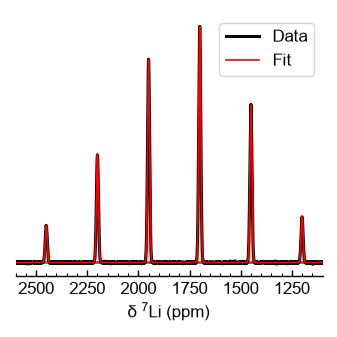

In [41]:
out = pf.fit_predicted_spectrum(
    results, "toy.cif", "Li", shell_bins, shift_dict,
    ignore_species=["O"],
    fit_regions=[(1100, 2600)],   # excludes the high-Mn tail -- also
                                   # exercises the "outside fit_regions"
                                   # rejection path, on top of those
                                   # groups being genuinely absent here
    snr_threshold=3.0,
    peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
    use_normalised=False,
    show_plot=True, show_report=True
)


### 6.5 Reading the output

`out` is a dict; the pieces worth knowing:

- **`kept` / `dropped`** -- which predicted groups survived filtering,
  and (for `dropped`) why: `"outside fit_regions"` or
  `"below S/N threshold"`.
- **`integrals` / `integrals_norm` / `integral_errors`** -- one entry per
  *fitted peak* (i.e. per group).
- **`environment_report`** -- `split_integrals_by_environment`'s output:
  each fitted peak's integral divided back out across its member
  environments, in proportion to their CIF-probability ratio *within*
  that group -- one row per individual environment, not per peak.

Both `print_environment_report` (called automatically above via
`show_report=True`) and this DataFrame are worth checking against
whatever ground truth you have.

In [42]:
true_frac = true_peaks.set_index("group_shift")["group_p"]
true_frac = true_frac / true_frac.sum()

print("Recovered vs. true peak fraction (integral_pct_of_total, summed per peak):")
recovered = out["environment_report"].groupby("peak_shift")["integral_pct_of_total"].sum()
for shift, true_pct in (100 * true_frac).items():
    print(f"  {shift:8.1f} ppm   true {true_pct:6.2f}%   "
          f"recovered {recovered.get(shift, float('nan')):6.2f}%")

print(f"\n{len(out['kept'])} peaks kept, {len(out['dropped'])} groups dropped "
      f"(see out['dropped'] for why).")
out["environment_report"].head()


Recovered vs. true peak fraction (integral_pct_of_total, summed per peak):
    1200.0 ppm   true   5.77%   recovered   5.82%
    1450.0 ppm   true  19.79%   recovered  20.00%
    1700.0 ppm   true  29.69%   recovered  30.00%
    1950.0 ppm   true  25.45%   recovered  25.71%
    2200.0 ppm   true  13.63%   recovered  13.75%
    2450.0 ppm   true   4.67%   recovered   4.72%
    2700.0 ppm   true   1.00%   recovered    nan%

6 peaks kept, 3 groups dropped (see out['dropped'] for why).


,peak_shift,environment_label,environment_shift,fraction_within_peak,integral_abs,integral_pct_of_total,integral_abs_err
0,1200.0,NN:8Fe NNN:6Li,1200.0,0.125,4.589824,0.72706,0.014912
1,1200.0,NN:8Fe NNN:6Li,1200.0,0.125,4.589824,0.72706,0.014912
2,1200.0,NN:8Fe NNN:6Li,1200.0,0.125,4.589824,0.72706,0.014912
3,1200.0,NN:8Fe NNN:6Li,1200.0,0.125,4.589824,0.72706,0.014912
4,1200.0,NN:8Fe NNN:6Li,1200.0,0.125,4.589824,0.72706,0.014912


### 6.6 Driving the lower-level pieces yourself

As in Section 3, if you want more control -- fitting several regions
differently, or reusing a `groups` table across several experimental
spectra -- `fit_predicted_spectrum`'s three internal steps are ordinary
functions:

In [27]:
kept, dropped, noise = pf.select_groups(
    groups, results, fit_regions=[(1100, 2600)], snr_threshold=3.0, tolerance=tolerance,
)
peak_defs = pf.groups_to_peak_defs(
    kept, peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
)
print(f"{len(kept)} kept, {len(dropped)} dropped, noise estimate = {noise:.4g}")
peak_defs[0]


6 kept, 3 dropped, noise estimate = 0.0301


{'type': 'gaussian',
 'shift': 1200.0,
 'fwhm': 10.0,
 'fixed': {'shift': True},
 'bounds': {'fwhm': (2.0, 40.0), 'amplitude': (0.0, inf)},
 'A_init': 2.870088535176418}

### 6.7 Simplifying a crowded fit automatically: `merge_low_integral_peaks`

A CIF with a lot of combinatorial disorder can produce far more
CIF-resolvable groups than your spectrum can actually resolve. Rather
than hand-picking which to combine, `merge_low_integral_peaks` absorbs
low-integral peaks into their nearest neighbour automatically. A peak is
a merge candidate if its integral is below `integral_threshold`, below
`relative_threshold` (default 5%) of the biggest peak, or (if
`integral_errors` is given) statistically indistinguishable from zero at
`n_sigma`. Merging cascades -- a merged peak can itself absorb further
neighbours -- and is greedy/order-dependent, so inspect the returned
`merge_log` before trusting it, the same way you'd check `kept`/`dropped`
above.

`relative_threshold` is lowered to 20% below purely so this small toy
example (whose peaks are all fairly evenly sized) actually produces a
merge to look at -- the 5% default is more appropriate once you have a
genuinely crowded fit, as in the real-data example in 10.13.

In [28]:
merged_groups, merge_log = pf.merge_low_integral_peaks(
    out["kept"], out["integrals"],
    integral_errors=out["integral_errors"],
    relative_threshold=0.2,
    merge_tolerance=300.0,   # ppm -- how close two peaks must be to merge
)
print(merge_log)         # exactly what got absorbed into what
merged_groups[["group_shift", "group_p", "n_source_peaks", "source_span"]]


   absorbed_shift  absorbed_integral  into_shift  into_integral  merged_shift  merged_integral
0          2450.0          29.820703      2200.0      86.797296   2263.928175       116.617999
1          1200.0          36.718591      1450.0     126.272769   1393.680158       162.991360


,group_shift,group_p,n_source_peaks,source_span
0,1393.548387,0.255298,2,250.0
1,1700.000000,0.296475,1,0.0
2,1950.000000,0.254122,1,0.0
3,2263.829787,0.182812,2,250.0


### 6.8 Simplifying a fit manually: `merge_groups_to_picks`

If you'd rather choose the final peak centres yourself -- read off the
maximal fit or the raw spectrum by eye -- `merge_groups_to_picks` merges
every maximal-fit peak onto whichever `pick` is nearest to it, no
threshold involved. `assignment_report` shows which peak went to which
pick and how far; a `pick_shift` far from the resulting `group_shift`
(the CIF-probability-weighted prediction for what actually got assigned
to it) is a sign you picked a point the CIF prediction doesn't support.

In [29]:
picks_groups, assignment_report = pf.merge_groups_to_picks(
    out["kept"], picks=[1350.0, 2000.0], integrals=out["integrals"],
)
print(assignment_report)
picks_groups[["pick_shift", "group_shift", "n_source_peaks"]]


   peak_shift  nearest_pick  distance  assigned
0      1200.0        1350.0     150.0      True
1      1450.0        1350.0     100.0      True
2      1700.0        2000.0     300.0      True
3      1950.0        2000.0      50.0      True
4      2200.0        2000.0     200.0      True
5      2450.0        2000.0     450.0      True


,pick_shift,group_shift,n_source_peaks
0,1350.0,1393.548387,2
1,2000.0,1927.165586,4


### 6.9 Refitting a simplified peak set: `refit_merged_groups`

Re-fits a simplified peak set (from either 10.7 or 10.8) against the
same spectrum, this time with each centre free to move within
`+/- shift_float_window` ppm -- safer now than on the maximal fit, since
there are far fewer, better-separated peaks. `shift_float_window` has no
sensible default; pick something you can justify (e.g. the
`tolerance`/`merge_tolerance` used to build the merged groups, or your
estimate of referencing uncertainty). The result adds `shift_report`:
how far each peak's fitted centre drifted from the CIF-predicted
`group_shift` it started from -- printed automatically as part of
`show_report=True`.


NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (gaussian):
  shift     = 1699.999164 ± 0.122280
  fwhm      = 11.998573 ± 0.287946
  amplitude = 14.825794 ± 0.308128
  integral (raw) = 189.3563
  integral (%)    = 53.84

Peak 2 (gaussian):
  shift     = 1950.005524 ± 0.142445
  fwhm      = 11.987263 ± 0.335432
  amplitude = 12.720963 ± 0.308273
  integral (raw) = 162.3201
  integral (%)    = 46.16

Fit quality:
------------------------------------------------------------
RMSE          : 9.747806e-01
Chi^2         : 2.375493e+03
Reduced Chi^2 : 9.532475e-01


PREDICTED ENVIRONMENTS CONTRIBUTING TO THE FIT

Peak at 1700.000 ppm (53.84% of total, 8 environment(s)):
    NN:2Mn+6Fe NNN:6Li                        12.5% of peak  ->    6.73% of total (abs 23.67 +/- 0.4919)
    NN:2Mn+6Fe NNN:6Li                        12.5% of peak  ->    6.73% of total (abs 23.67 +/- 0.4919)
    NN:2Mn+6Fe NNN:6Li                        12.5% of peak  ->

,predicted_shift,fitted_shift,shift_delta,n_members,n_source_peaks
0,1700.0,1699.998820,-0.001180,8,1
1,1950.0,1950.005633,0.005633,8,1


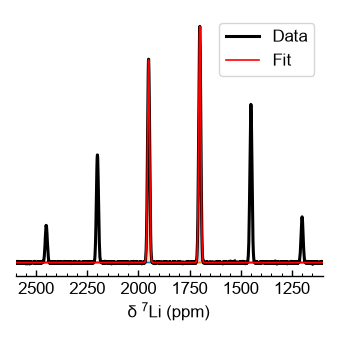

In [30]:
refit = pf.refit_merged_groups(
    merged_groups, results,
    shift_float_window=50.0,
    fit_regions=[(1100, 2600)],
    peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
    use_normalised=False,
    show_plot=True, show_report=True,
)
refit["shift_report"]


### 6.10 Labelling peaks with their dominant CIF environment

`dominant_environment(members)` picks out the single member environment
contributing the largest share of a peak's probability (ties broken by
raw probability); `format_environment_label` turns its `composition`
dict into a readable multi-line string. `add_dominant_environment_labels`
puts both on a plot automatically -- pass `show_composition_labels=True`
to `fit_predicted_spectrum`/`refit_merged_groups` rather than calling it
directly.

Labels get real collision avoidance (rendered text boxes, stacked
vertically with leader lines back to their peak) and the figure
auto-widens to fit them -- but with many peaks that's still a lot of
text, so `composition_label_kwargs={"max_labels": N}` or
`{"min_peak_fraction": f}` cap it to the biggest peaks only.

c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\fitting.py:927: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


peak 0: Shift = 1200 ppm  (12% of peak)  |  NN: Fe = 8, Mn = 0  |  NNN: Fe = 0, Mn = 0
peak 1: Shift = 1450 ppm  (12% of peak)  |  NN: Fe = 7, Mn = 1  |  NNN: Fe = 0, Mn = 0
peak 2: Shift = 1700 ppm  (12% of peak)  |  NN: Fe = 6, Mn = 2  |  NNN: Fe = 0, Mn = 0
peak 3: Shift = 1950 ppm  (12% of peak)  |  NN: Fe = 5, Mn = 3  |  NNN: Fe = 0, Mn = 0
peak 4: Shift = 2200 ppm  (12% of peak)  |  NN: Fe = 4, Mn = 4  |  NNN: Fe = 0, Mn = 0
peak 5: Shift = 2450 ppm  (12% of peak)  |  NN: Fe = 3, Mn = 5  |  NNN: Fe = 0, Mn = 0


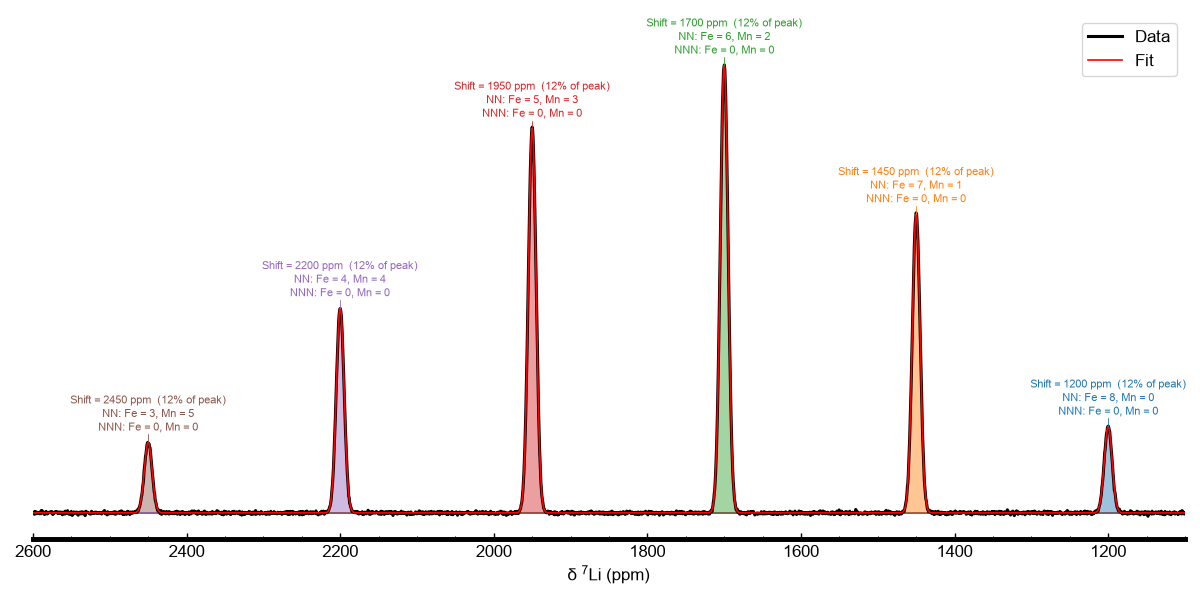

In [33]:
labelled = pf.fit_predicted_spectrum(
    results, "toy.cif", "Li", shell_bins, shift_dict,
    ignore_species=["O"],
    fit_regions=[(1100, 2600)],
    snr_threshold=3.0,
    peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
    use_normalised=False,
    show_plot=True, show_report=False,
    show_composition_labels=True,
    xlims=[2600,1100]
)

for i, row in labelled["kept"].iterrows():
    dom = pf.dominant_environment(row["members"])
    print(f"peak {i}: " +
          pf.format_environment_label(row["group_shift"], dom["composition"], dom["fraction_in_group"]).replace("\n", "  |  "))


### 6.11 Alternative: fitting the whole predicted envelope with `fit_cif_envelope`

Sometimes a CIF's disorder is too combinatorially rich to resolve into a
handful of discrete peaks at all -- `group_environments` collapsing
almost everything into one or two groups regardless of a sensible
`tolerance` is the tell (10.13 works through exactly this). For that
case, `fit_cif_envelope` sidesteps grouping/peak-fitting entirely: it
fits the *whole* predicted shift distribution as one continuous envelope
against the data, floating only four global, physically-meaningful
parameters:

- **`shift_scale`** -- multiplies *every* `shift_dict` pathway constant
  at once, correcting a systematically over/under-estimated contact-shift
  magnitude without re-guessing each pathway constant by hand
- **`x_offset`** -- a rigid referencing offset
- **`sigma`** -- an inhomogeneous broadening width
- **`intensity_scale`** -- overall amplitude

It can't tell you "this peak is environment X" the way
`fit_predicted_spectrum` can -- there are no discrete peaks in this
model -- but it's a fast way to (a) sanity-check/calibrate `shift_dict`
against real data, and (b) get a meaningful fit at all when discrete
peaks aren't the right physical picture.

In [34]:
env_out = pf.fit_cif_envelope(
    results, "toy.cif", "Li", shell_bins, shift_dict,
    ignore_species=["O"],
    fit_regions=[(1100, 2600)],
    sigma_init=15.0,
    use_normalised=False,
)
print(env_out["popt"])   # shift_scale, x_offset, sigma, intensity_scale, b0, b1
print("RMSE:", env_out["rmse"])


{'shift_scale': np.float64(0.9999995170716328), 'x_offset': np.float64(0.0026003478317455607), 'sigma': np.float64(5.093241964612308), 'intensity_scale': np.float64(50.021677023195835), 'b0': np.float64(0.00016076930343856914), 'b1': np.float64(1.321932662784417e-06)}
RMSE: 0.02951989640981085


### 6.12 Worked example on real data: a mixed Mn/Ru layered oxide

Putting 10.1-10.10 together end to end on a real CIF and a real
experimental spectrum -- predict, group, fit the maximal set, simplify by
hand onto peaks read off the spectrum, refit with shift free, and read
off each fitted peak's dominant environment.

c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\pnmr_simulator.py:86: UserWarning: Issues encountered while parsing CIF: 3 fractional coordinates rounded to ideal values to avoid issues with finite precision.
Skipping relative stoichiometry check because CIF does not contain formula keys.
  structures = parser.parse_structures(primitive=False)


[2.71457736 2.71457736 2.71457736 2.71457736 2.71457736 2.71457736
 2.71457736 2.71457736 2.74773054 2.74773054 2.74773054 2.74773054
 2.74773054 2.74773054 2.74773054 2.74773054 2.85401211 2.85401211
 2.85401211 2.85401211]

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (gaussian):
  shift     = -195.275228 (fixed)
  fwhm      = 90.000000 ± 5.230322
  amplitude = 2839.921683 ± 247.989399
  integral (raw) = 251344.2800
  integral (%)    = 0.17

Peak 2 (gaussian):
  shift     = -135.781162 (fixed)
  fwhm      = 84.892313 ± 5.040116
  amplitude = 6319.313138 ± 198.920258
  integral (raw) = 570606.4007
  integral (%)    = 0.37

Peak 3 (gaussian):
  shift     = -76.524053 (fixed)
  fwhm      = 82.560507 ± 0.841033
  amplitude = 28938.421633 ± 306.983504
  integral (raw) = 2543192.5151
  integral (%)    = 1.67

Peak 4 (gaussian):
  shift     = -12.183945 (fixed)
  fwhm      = 72.215489 ± 0.312917
  amplitude = 38743.625216 ± 371.133601

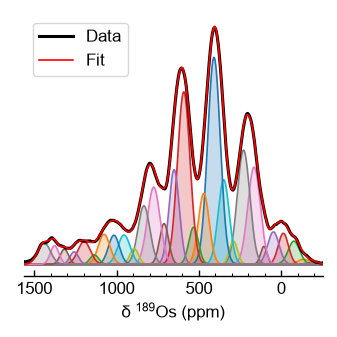

In [25]:
cif_filename = r"C:\Users\quark\OneDrive\Documents\Neutron\LIRO_Combined_Refinement\Refinement_Results_20250122\CIF_LRMO_C2m_disord.cif"

# 10.1: inspect neighbour distances first, to choose shell_bins (as in 8.1)
structure, site_data = nmr.read_cif_with_occupancies(cif_filename, atom_of_interest="Li", verbose=True)
d = nmr.shell_distance_histogram(structure, site_data, "Li", max_r=6.0, ignore_species=["O", "O2-"])
print(d[:20])   # look for the gaps that should become your shell boundaries

shell_bins = [
    ("NN",  0.0, 3.10),
    ("NNN", 3.50, 4.20),
]
shift_dict = {
    "NN":  {"Mn": 240,  "Ru": -5, "Li": 0.0},
    "NNN": {"Mn": -60, "Ru": -3,  "Li": 0.0},
}

experimental_dict = nmr.NMR1dimport(
    r"C:\Users\quark\OneDrive\Documents\NMR\100MHz_UCSB\100_ENB_20230807_Li2Ru0p5Mn0p5O3_300123A_Pristine_7Li\991000"
)

# 10.4: the maximal fit
out = pf.fit_predicted_spectrum(
    experimental_dict, cif_filename, "Li", shell_bins, shift_dict,
    ignore_species=["O", "O2-"],
    fit_regions=[(-250, 1560)],
    snr_threshold=6.0,
    group_method="probability", tolerance=100.0,   # ppm, for grouping predicted peaks
    peak_type="gaussian", fwhm_init=50.0, fwhm_bounds=(10.0, 90.0),
    use_normalised=False,
    show_plot=True, show_report=True,
)


     peak_shift  nearest_pick    distance  assigned
0   -195.275228         -10.0  185.275228      True
1   -135.781162         -10.0  125.781162      True
2    -76.524053         -10.0   66.524053      True
3    -12.183945         -10.0    2.183945      True
4     48.361168         -10.0   58.361168      True
5    106.006663         210.0  103.993337      True
6    165.150419         210.0   44.849581      True
7    229.270637         210.0   19.270637      True
8    290.653979         210.0   80.653979      True
9    349.813625         401.0   51.186375      True
10   408.679831         401.0    7.679831      True
11   470.716242         401.0   69.716242      True
12   532.617536         602.0   69.382464      True
13   592.107286         602.0    9.892714      True
14   650.749926         602.0   48.749926      True
15   711.892394         796.0   84.107606      True
16   774.616170         796.0   21.383830      True
17   834.182639         796.0   38.182639      True
18   893.438

c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\fitting.py:927: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()



NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo_voigt):
  shift     = -14.612329 ± 0.628348
  fwhm      = 120.000000 ± 2.231048
  amplitude = 40638.125072 ± 431.851363
  eta       = 0.963749 ± 0.047662
  integral (raw) = 6894545.2740
  integral (%)    = 4.55

Peak 2 (pseudo_voigt):
  shift     = 199.648238 ± 0.147132
  fwhm      = 120.000000 ± 0.526255
  amplitude = 182332.245971 ± 571.801848
  eta       = 0.819289 ± 0.020194
  integral (raw) = 30782722.1255
  integral (%)    = 20.33

Peak 3 (pseudo_voigt):
  shift     = 406.762601 ± 0.100476
  fwhm      = 120.000000 ± 0.363267
  amplitude = 286748.655304 ± 714.476600
  eta       = 0.501413 ± 0.015609
  integral (raw) = 44129712.9312
  integral (%)    = 29.14

Peak 4 (pseudo_voigt):
  shift     = 605.288860 ± 0.152819
  fwhm      = 120.000000 ± 0.439250
  amplitude = 219478.223739 ± 936.431686
  eta       = 0.124116 ± 0.024908
  integral (raw) = 29473359.4852
  integral (%)

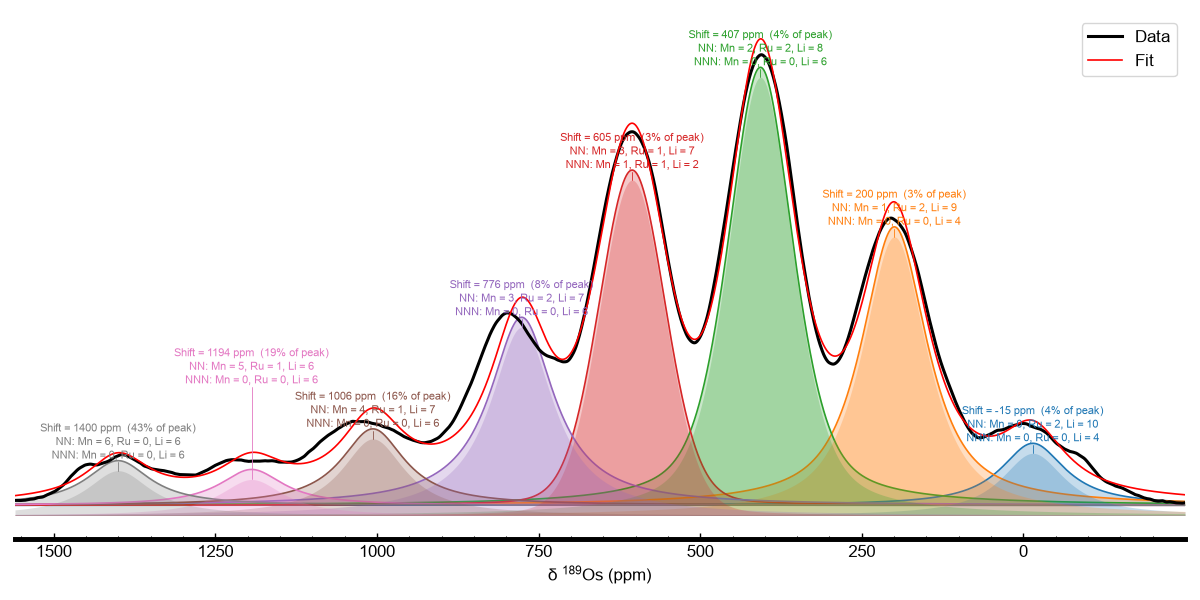

In [26]:
# 10.8: simplify by hand onto peak centres read off the maximal fit / raw spectrum
merged_groups, assignment_report = pf.merge_groups_to_picks(
    out["kept"],
    picks=[-10.0, 210.0, 401.0, 602.0, 796.0, 1025.0, 1203.0, 1403.0],
    integrals=out["integrals"],
)
print(assignment_report)

# 10.9: refit with shift free, and show composition labels on the plot
refit = pf.refit_merged_groups(
    merged_groups, out["results"],
    shift_float_window=50.0,   # ppm the centre is allowed to move
    fit_regions=[(-250, 1560)],
    use_normalised=False,
    peak_type="pseudo_voigt", fwhm_init=50.0, fwhm_bounds=(10.0, 120.0),
    show_composition_labels=True,
)

# 10.10: dominant environment per fitted peak
for i, row in refit["kept"].iterrows():
    dom = pf.dominant_environment(row["members"])
    print(f"peak {i}: " +
          pf.format_environment_label(row["group_shift"], dom["composition"], dom["fraction_in_group"]).replace("\n", "  |  "))


### 6.13 Worked example: when grouping goes wrong, and `fit_cif_envelope` as the fix

A cautionary real case, Li2MnO3's honeycomb-disordered Mn/Li layer.
With `shift_dict = {"NN": {"Mn": 245}, "NNN": {"Mn": -50}}`,
`gcd(245, 50) = 5`: enumerating NN/NNN Mn counts produces ~91 distinct
shift values with a **median spacing of 45 ppm**, and *every* gap
between adjacent values is <= 50 ppm. `default_tolerance` (the smallest
non-zero pathway constant, 50 ppm here) is, by construction, almost
guaranteed to bridge every one of those gaps -- `group_environments`
collapses all ~2800 predicted environments into essentially *one* group,
however the fit region is chosen, and a single fixed-position peak
obviously can't fit a spectrum with real structure across it. Letting
the shift float instead doesn't fix this either -- you'd just get one
peak sliding around several real features, not resolving any of them.

Two lessons, not just one:

1. **Mechanically**: don't trust `default_tolerance` blindly -- pass
   `tolerance` explicitly (tied to your actual expected resolution) and
   use `max_group_span` as a tripwire, so a collapse like this raises
   loudly instead of silently producing nonsense.
2. **Physically**: a honeycomb-disordered TM layer with binomial site
   disorder is the textbook case for an unresolved, continuously-varying
   envelope rather than a stick spectrum of a few sharp sites -- even a
   *sane* tolerance here still leaves dozens of narrow, closely-spaced
   lines. `fit_cif_envelope` (10.11) is the more appropriate model for
   this material, not just a workaround for a grouping bug.

In [ ]:
cif_filename = r"C:\Users\quark\OneDrive\Documents\Neutron\Pristine_Materials_UCSB_D2b_MarApr2024\Li2MnO3\CIF_Li2MnO3_20250124.cif"

shell_bins = [
    ("NN",  0.0, 3.10),
    ("NNN", 3.50, 4.20),
]
shift_dict = {
    "NN":  {"Mn": 245, "Li": 0.0},
    "NNN": {"Mn": -50, "Li": 0.0},
}

experimental_dict = nmr.NMR1dimport(
    r"C:\Users\quark\OneDrive\Documents\NMR\100MHz_UCSB\100_ENB_20230710_Li2MnO3_enb\901"
)

# The default tolerance collapses almost everything into one group --
# see for yourself before ever calling fit_predicted_spectrum:
predicted = pf.predict_environments(cif_filename, "Li", shell_bins, shift_dict, ignore_species=["O", "O2-"])
groups, tol = pf.group_environments(predicted, shift_dict=shift_dict)
print(f"default tolerance = {tol} ppm -> {len(groups)} group(s), "
      f"widest span = {groups['span'].max():.1f} ppm")


default tolerance = 50 ppm -> 37 group(s), widest span = 5.0 ppm


c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\pnmr_simulator.py:86: UserWarning: Issues encountered while parsing CIF: Skipping relative stoichiometry check because CIF does not contain formula keys.
  structures = parser.parse_structures(primitive=False)


In [ ]:
# Fix #1 (mechanical): pick a real tolerance, guard against another collapse
groups, tol = pf.group_environments(predicted, tolerance=20.0, shift_dict=shift_dict,
                                     max_group_span=100.0)
print(f"tolerance=20 ppm -> {len(groups)} groups -- resolvable, but still dozens of narrow lines")

# Fix #2 (physical): fit the envelope instead of discrete peaks
env_out = pf.fit_cif_envelope(
    experimental_dict, cif_filename, "Li", shell_bins, shift_dict,
    ignore_species=["O", "O2-"],
    fit_regions=[(400, 1800)],
    sigma_init=50.0,        # a rough guess at the real linewidth
    use_normalised=False,
)
print(env_out["popt"])   # shift_scale, x_offset, sigma, intensity_scale


tolerance=20 ppm -> 37 groups -- resolvable, but still dozens of narrow lines


c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\pnmr_simulator.py:86: UserWarning: Issues encountered while parsing CIF: Skipping relative stoichiometry check because CIF does not contain formula keys.
  structures = parser.parse_structures(primitive=False)


{'shift_scale': np.float64(0.9980460408219713), 'x_offset': np.float64(-7.631554030297538), 'sigma': np.float64(20.111460890530935), 'intensity_scale': np.float64(2321756.573738001), 'b0': np.float64(5106.8376081012875), 'b1': np.float64(-0.0003163805119680097)}


## 7. Import and plot a 2-d dataset, extract a row and a column, and plot everything together (all at once)

### 7.1. Import once, plot manually

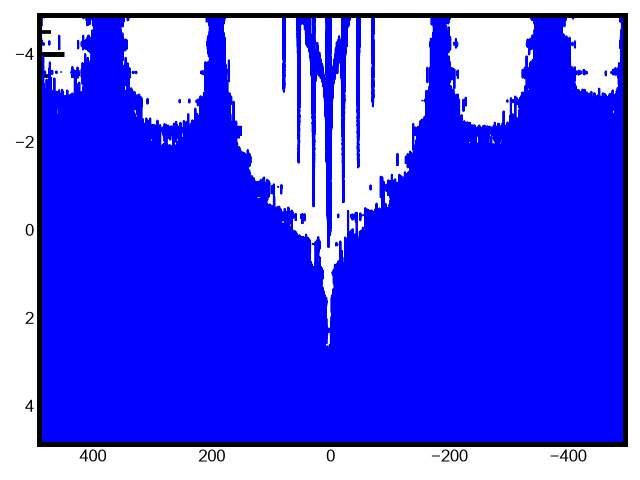

In [45]:
ds = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\2", 
                     procno=1, homonuclear=False)

# ds["spectrum"] is the 2D matrix, shape (n_F1, n_F2)
fig, ax = plt.subplots()
ax.contour(ds["x_ppm"], ds["y_ppm"], ds["spectrum"], levels=100, colors='blue')
ax.invert_xaxis()
ax.invert_yaxis()

plt.tight_layout()
plt.show()

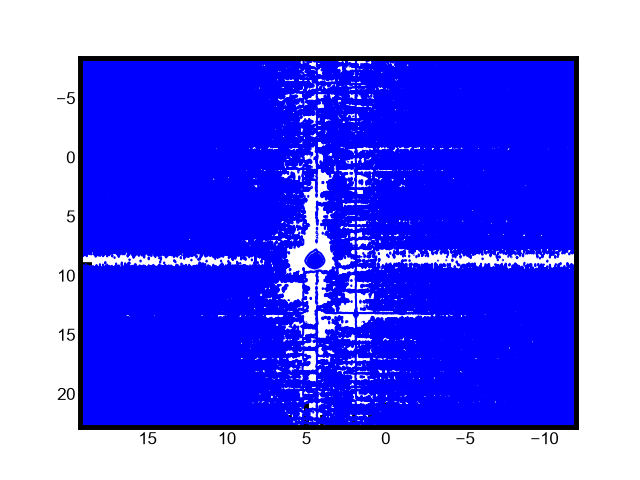

In [46]:
DQSQ = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_20260119\6", homonuclear=False)

fig, ax = plt.subplots()
ax.contour(DQSQ["x_ppm"], DQSQ["y_ppm"], DQSQ["spectrum"], levels=15, colors='blue')
ax.invert_xaxis()
ax.invert_yaxis()

### 7.2. Contour plot with the built-in plotter

For a homonuclear double-quantum (or other multiple-quantum) correlation
spectrum, overlay the relevant diagonal(s):

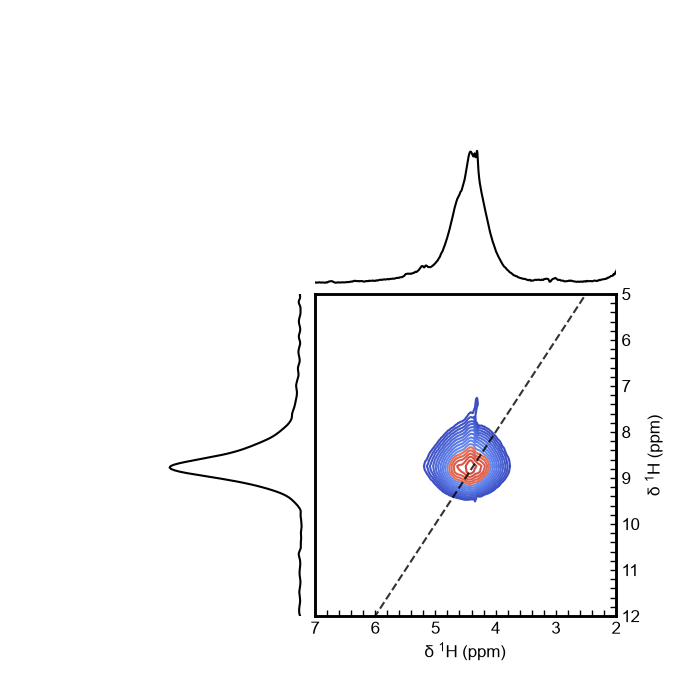

In [ ]:
DQSQ = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_20260119\6", homonuclear=False)

fig, ax = nmr.NMR2Dplotter(
    DQSQ,                          # or pass the path directly instead of DQSQ
    homonuclear=True,
    colour_spectra='coolwarm',     # None = black contours; or e.g. 'coolwarm'
    show_nQ_line=True,
    clevels=20,
    factor=5e-2,                   # lowest contour level, as a fraction of the max
    nQ=[2],                        # single- and double-quantum diagonals
    nQ_colours=['black'],
    xlims=[7, 2], ylims=[12, 5],
    proj_scale=1.5,
    show_projections=True,         # or 'f1' or 'f2' to only have projections for one axis
    fontsize='large'
)

### 7.2b. Adding an inset to a contour plot

Any contour or overlay plot can carry one or more insets -- e.g. to zoom
into a crowded region without a second, separate figure. Pass `inset` as
a dict (or a list of dicts, for more than one inset). The only required
key is `bounds` -- `(x0, y0, width, height)` in axes-fraction coordinates
of the *parent* plot -- which sets the inset's placement and size. Every
other key accepts exactly the same keyword arguments as `NMR2Dplotter`
itself (`xlims`/`ylims`, `factor`, `clevels`, `colour_spectra`,
`fontsize`, ...), so an inset can be independently zoomed, contoured, and
styled. `mark_inset=True` draws a connector box linking the inset back to
the region of the parent plot it corresponds to.

(One exception: an inset's own `show_projections` is not supported and
raises if set -- the 1D projections rely on matplotlib machinery that
isn't compatible with an axes that is itself positioned relative to
another one.)

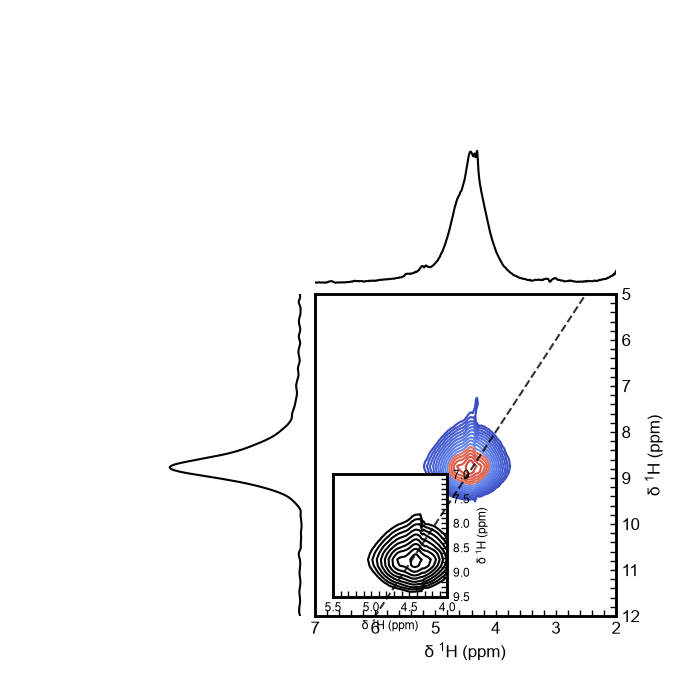

In [13]:
DQSQ = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_20260119\6", homonuclear=False)

fig, ax = nmr.NMR2Dplotter(
    DQSQ,
    homonuclear=True,
    colour_spectra='coolwarm',
    show_nQ_line=True,
    clevels=20,
    factor=5e-2,
    nQ=[2],
    nQ_colours=['black'],
    xlims=[7, 2], ylims=[12, 5],
    proj_scale=1.5,
    show_projections=True,
    fontsize='large',

    # Zoom into a crowded cross-peak region, placed in the bottom-left
    # corner of the plot at ~38% of the main plot's width/height.
    inset={
        "bounds": (0.06, 0.06, 0.38, 0.38),        # (x0, y0, width, height), axes-fraction
        "xlims": [5.5, 4.0], "ylims": [9.5, 7.0],   # the inset's own zoom -- adjust to your peak
        "clevels": 12, "factor": 8e-2,              # can differ from the main plot's own
        "fontsize": "small",
        "mark_inset": False,                         # draw a connector box back to the zoomed region
        "mark_inset_kwargs": {"edgecolor": "crimson", "linewidth": 1.2},
    },
)

# `inset` also accepts a list of dicts for more than one inset, and a
# "dataset" key per inset to show a different spectrum than the parent
# plot (it defaults to the same dataset, DQSQ, if omitted), e.g.:
#   inset=[{"bounds": (0.06, 0.06, 0.3, 0.3), "xlims": [5.5, 4.0], "ylims": [9.5, 7.0]},
#          {"bounds": (0.62, 0.06, 0.3, 0.3), "xlims": [3.0, 2.2], "ylims": [6.0, 5.2]}]
#
# The same `inset=...` kwarg works unchanged through NMR2D_multi_plot
# (as a shared kwarg, or per-panel via panel_kwargs), NMR2D_overlay_plot,
# and NMR2D_summary_plot's own `contour_kwargs`.

### 7.3. Extract a row and a column

Rows fix an F1 position and span F2; columns fix an F2 position and span
F1 (matches TopSpin’s own row/column trace convention — see the
`nmrtools.two_d` module docstring - access *via* `nmr.two_d?` if you want the full explanation).

In [52]:
row = nmr.NMR2d_get_trace(DQSQ, axis="f1", shift=8.7)   # nearest F1 position to 8.7 ppm
col = nmr.NMR2d_get_trace(DQSQ, axis="f2", shift=4.4)   # nearest F2 position to 4.4 ppm

# or by 1-based index instead of shift:
row = nmr.NMR2d_get_trace(DQSQ, axis="f1", index=464)

print(row["x"], row["y"])                       # the extracted trace
print("Row shift = ", row["shift"])             # the actual position it was extracted at
print("Row width = ", row["width"])             # how many adjacent points were combined (default 1)

[ 19.25230555  19.24849111  19.24467667 ... -11.98416054 -11.98797499
 -11.99178943] [-242365 -224529 -202067 ... -230673 -241188 -247842]
Row shift =  8.680590332241465
Row width =  1


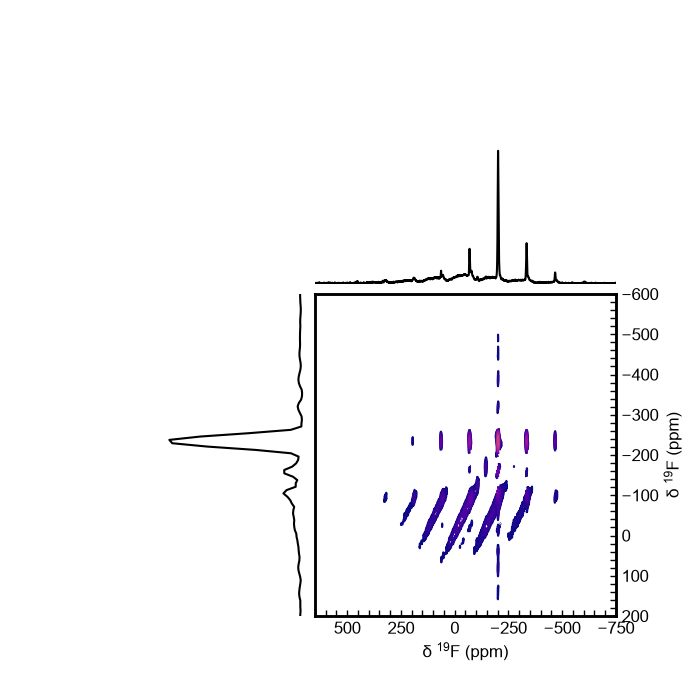

In [53]:
aMAT_example_fname = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_19F_FeF3_0p333H2O_20260604\10"
aMAT_example = nmr.NMR2dimport(aMAT_example_fname, homonuclear=False)

fig, ax = nmr.NMR2Dplotter(
    aMAT_example,                          # or pass the path directly instead of DQSQ
    homonuclear=True,
    colour_spectra='plasma',     # None = black contours; or e.g. 'coolwarm'
    #show_nQ_line=True,
    contour_fraction_x=None, contour_fraction_y=None,
    ncontourpts_x=32768, ncontourpts_y=512,
    clevels=20,
    factor=2e-2,                   # lowest contour level, as a fraction of the max
    #nQ=[1],                        # single- and double-quantum diagonals
    #nQ_colours=['black'],
    projection_mode='max',
    xlims=[-750,650], ylims=[-600,200],
    proj_scale=1.5,
    show_projections=True,         # or 'f1' or 'f2' to only have projections for one axis
    fontsize='large'
)


To pull several rows/columns at once (*e.g.*, every 10th row across a
range), use the batch version, which is what you’ll normally want before
fitting:

In [54]:
aMAT_example_fname = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_19F_FeF3_0p333H2O_20260604\10"
aMAT_example = nmr.NMR2dimport(aMAT_example_fname, homonuclear=False)

slices = nmr.NMR2D_get_slices(
    aMAT_example,
    #rows=[440, 450, 460],       # by index
    row_shifts=[-60, -233],     # and/or by shift -- combined, de-duplicated
    row_width=5,                 # sum this many adjacent rows for extra S/N
    # columns=[3870, 3910],
    # column_width=1,
)

#slices["rows"]      # list of trace dicts, sorted by position
#slices["columns"]

for i in range(0,int(len(slices['columns']))):
    print(slices['columns'][i].keys())
    print(slices['columns'][i]['shift'])

### 7.4. Plot the extracted row/column, alongside the contour plot

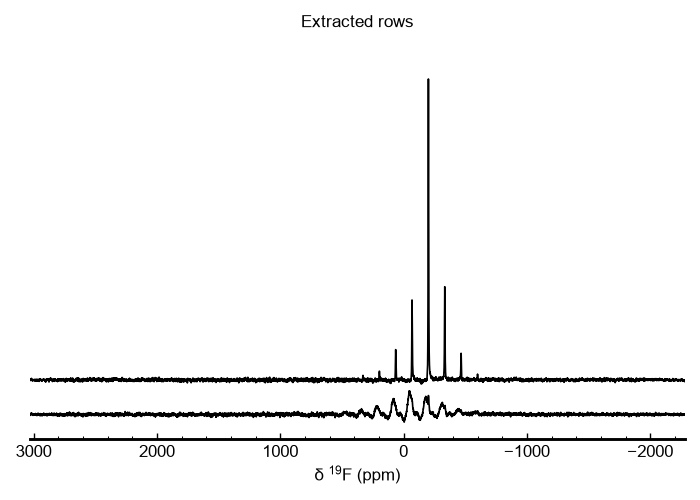

In [55]:
fig, ax = nmr.NMR2D_plot_slices(slices, mode="rows")
#fig, ax = nmr.NMR2D_plot_slices(slices, mode="columns")

To show the contour plot and the extracted slices side by side (or
stacked, or in a grid) in one figure:

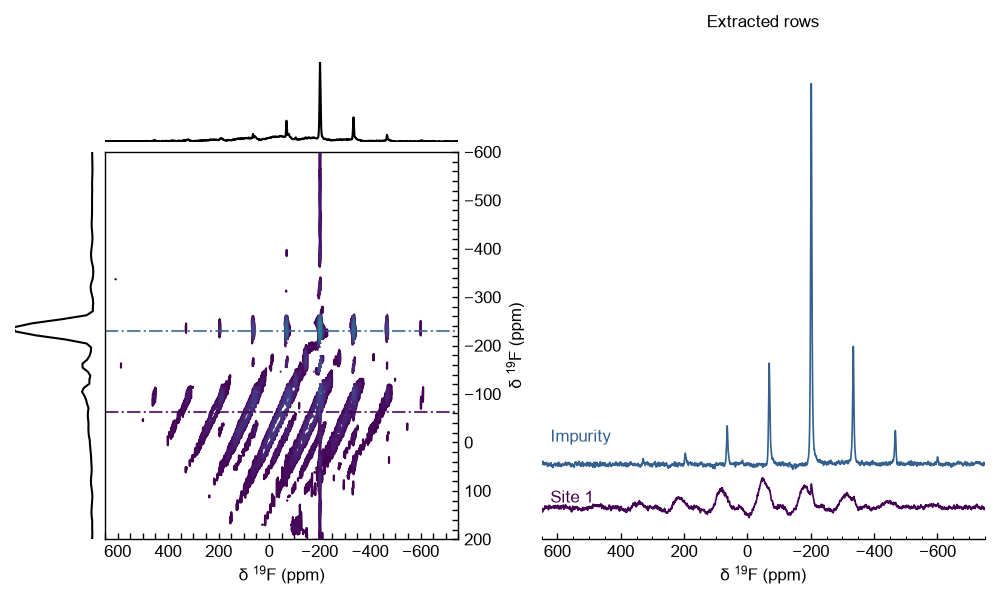

In [ ]:
aMAT_example_fname = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_19F_FeF3_0p333H2O_20260604\10"
aMAT_example = nmr.NMR2dimport(aMAT_example_fname, homonuclear=False)

fig, axes = nmr.NMR2D_summary_plot(
    aMAT_example,
    pl_height=6.0, pl_width=10.0,
    slices=slices,
    slices_mode="rows",
    layout="grid",                               # "row" | "column" | "grid"
    clevels=20,
    factor=1e-2,
    colour_spectra="viridis",
    show_projections=True,                       # or 'f1', or 'f2' for single-axis projection
    projection_size=0.8,
    #show_nQ_line=True,
    contour_kwargs={"contour_fraction_x": None, "contour_fraction_y" : None,
                    "ncontourpts_x": 32768, "ncontourpts_y": 512, "projection_mode": "max"},
    #nQ=[1],                                      # single- and double-quantum diagonals
    #nQ_colours=['black'],
    xlims=[-750,650], ylims=[-600,200],
    slices_on_contour_mode="rows",
    slices_on_contour_linestyle='-.',
    slices_on_contour_alpha=0.8,
    show_nQ_markers=False,
    nQ_marker_offset=0.1,
    show_labels=True,
    label_style='text',                          # 'text' or 'legend'
    labels=['Site 1', 'Impurity'],
    label_fontsize='large',
    label_side='left',                           # 'left' or 'right'
    label_pad=0.05,                              # larger number: further away from spectrum
    # save_fig=True,
    # fig_name='Example_2d_with_slices',
    # save_format='svg'
)

### 7.5 Add external projections

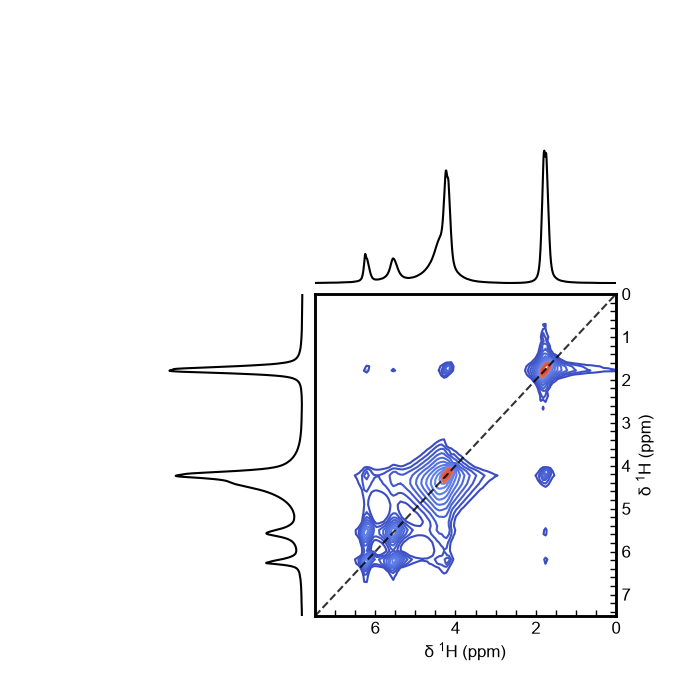

In [14]:
EXSY_ex = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2261", homonuclear=False)
spinecho_fname = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\1"

fig, ax = nmr.NMR2Dplotter(
    EXSY_ex,                          # or pass the path directly instead of DQSQ
    homonuclear=True,
    colour_spectra='coolwarm',     # None = black contours; or e.g. 'coolwarm'
    show_nQ_line=True,
    clevels=20,
    factor=1e-3,                   # lowest contour level, as a fraction of the max
    nQ=[1],                        # single- and double-quantum diagonals
    nQ_colours=['black'],
    xlims=[0, 7.5], ylims=[0, 7.5],
    f1_external_projection=spinecho_fname,
    external_projection_color='black',
    proj_scale=1.5,
    show_projections=True,         # or 'f1' or 'f2' to only have projections for one axis
    fontsize='large'
)

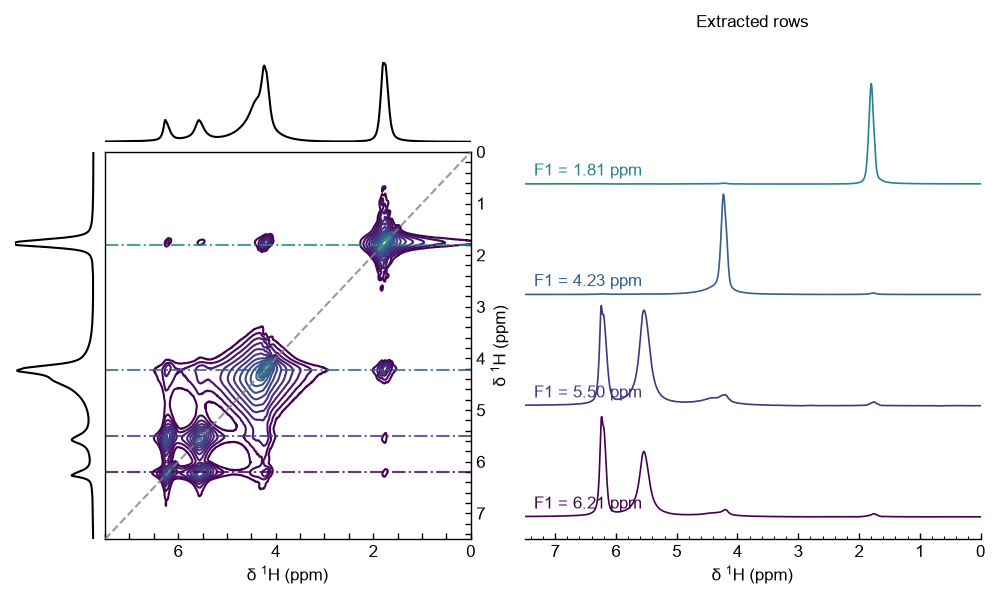

In [10]:
EXSY_ex = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2261", homonuclear=False)
spinecho_fname = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\1"

slices = nmr.NMR2D_get_slices(
    EXSY_ex,
    row_shifts=[1.80, 4.22, 5.50, 6.20],     # and/or by shift -- combined, de-duplicated
    row_width=1,                # sum this many adjacent rows for extra S/N
    normalise=True,
)

fig, axes = nmr.NMR2D_summary_plot(
    EXSY_ex,
    pl_height=6.0, pl_width=10.0,
    slices=slices,
    slices_mode="rows",
    layout="grid",                               # "row" | "column" | "grid"
    clevels=20,
    factor=1e-3,
    colour_spectra="viridis",
    show_projections=True,                       # or 'f1', or 'f2' for single-axis projection
    projection_size=0.8,
    show_nQ_line=True,
    nQ=[1],
    contour_kwargs={"contour_fraction_x": None, "contour_fraction_y" : None,
                    "ncontourpts_x": 32768, "ncontourpts_y": 512, "projection_mode": "max",
                    "f1_external_projection": spinecho_fname,
                    "f2_external_projection": spinecho_fname, "external_projection_color": 'black',},
    #nQ=[1],                                      # single- and double-quantum diagonals
    #nQ_colours=['black'],
    xlims=[0, 7.5], ylims=[0, 7.5],
    slices_on_contour_mode="rows",
    slices_on_contour_linestyle='-.',
    slices_on_contour_alpha=0.8,
    show_nQ_markers=False,
    nQ_marker_offset=0.1,
    show_labels=True,
    label_style='text',                          # 'text' or 'legend'
    #labels=['Site 1', 'Impurity'],
    label_fontsize='large',
    label_side='left',                           # 'left' or 'right'
    label_pad=0.05,                              # larger number: further away from spectrum
    # save_fig=True,
    # fig_name='Example_2d_with_slices',
    # save_format='svg'
)

### 7.6 Plotting multiple 2-d datasets

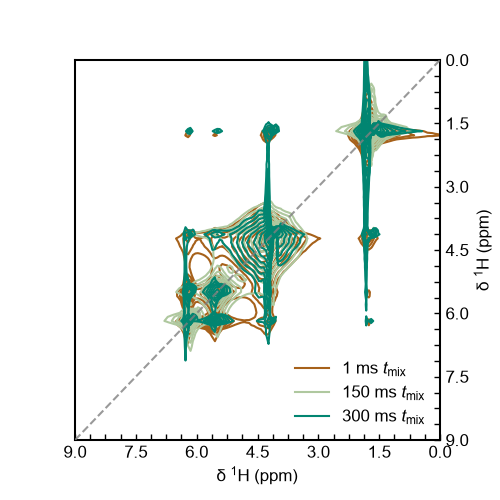

In [57]:
EXSY_1 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2261"
EXSY_2 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2262"
EXSY_3 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2263"

three_overlaid_exsys = nmr.NMR2D_overlay_plot([EXSY_1, EXSY_2, EXSY_3],
                                                xlims=[0, 9], ylims=[0, 9],
                                                pl_height=5, pl_width=5,
                                                labels=[r'1 ms $\mathit{t}_{mix}$', r'150 ms $\mathit{t}_{mix}$', r'300 ms $\mathit{t}_{mix}$'],
                                                equal_tickspacing=True,
                                                legend_kwargs={"loc": 4, "frameon": False}, 
                                                show_nQ_line=True,
                                                nQ=[1],)
                                                #x_offsets=[0,0.5,1.0], y_offsets=[0,0.0,0.0],)

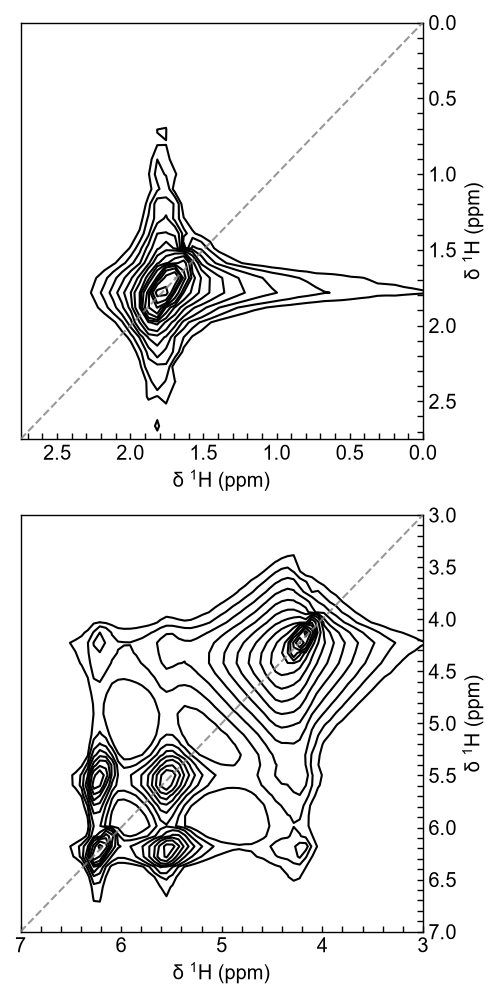

In [59]:
EXSY_1 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2261"
EXSY_2 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2262"

multi_2d_side_by_side = nmr.NMR2D_multi_plot([EXSY_1, EXSY_1], 
                                             layout="column", 
                                             panel_kwargs=[
                                                 {"xlims": [0.0, 2.75], "ylims": [0.0, 2.75], "show_nQ_line": True},
                                                 {"xlims": [3.0, 7.0], "ylims": [3.0, 7.0], "show_nQ_line": True}
                                             ],
                                             #colour_spectra='coolwarm',
                                             show_projections=False, fontsize='x-large')

In [4]:
for ax in multi_2d_side_by_side[1]:
    print("xlabel:", ax.xaxis.label.get_fontsize())
    print("ylabel:", ax.yaxis.label.get_fontsize())
    print("title:", ax.title.get_fontsize())
    print("ticks:", [t.get_fontsize() for t in ax.get_xticklabels()[:2]])

xlabel: 10.0
ylabel: 10.0
title: 12.0
ticks: [10.0, 10.0]
xlabel: 10.0
ylabel: 10.0
title: 12.0
ticks: [10.0, 10.0]


## 8. Fit rows extracted from a 2-d dataset and plot the integrals


2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 2.332337
  fwhm      = 7.700000 ± 4.438889
  amplitude = 511180.558725 ± 180642.324605
  eta       = 0.400000 ± 1.122673
  integral (raw) = 4986078.8150
  integral (%)    = 42.54

Peak 2 (pseudo-voigt):
  shift     = -0.290952 ± 0.792184
  fwhm      = 5.400000 ± 1.685791
  amplitude = 873627.043946 ± 315324.854663
  eta       = 0.717309 ± 0.851442
  integral (raw) = 6733696.6713
  integral (%)    = 57.46

Fit quality:
------------------------------------------------------------
RMSE          : 3.136429e+05
Chi^2         : 6.446900e+15
Reduced Chi^2 : 9.838691e+10


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6
-

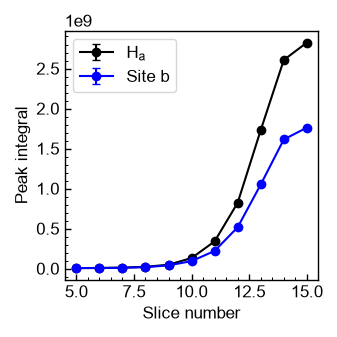

In [60]:
ds = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2")

slices = nmr.NMR2D_get_slices(ds, rows=list(range(5, 16)))   # rows 1-20
# or: nmr.NMR2D_get_slices(ds, row_shifts=[...])
# or, to fit every row: rows=nmr.select_2d_traces(ds, axis="f1", fit_all=True)

peak_defs = [
    {"type": "pseudo-voigt", "shift": -5.69, "fwhm": 7.62, "eta" : 0.35,
     "bounds": {"shift": (-5.58, -5.70), "fwhm" : (7.6, 7.7), "eta" : (0.3, 0.4)}},
    {"type": "pseudo-voigt", "shift": -0.005, "fwhm": 5.28, "eta" : 0.8,
     "bounds": {"shift": (0.5, -1.0), "fwhm" : (5.2, 5.4), "eta" : (0.7, 0.9)}},
]

fitted = nmr.NMR2D_fit_slices(
    slices,
    peak_defs,
    mode="rows",
    fit_regions=[(20,-30)],
    noise_region=(-150,-50),      # optional: peaks below sn_threshold here are fixed to 0
    sn_threshold=3,
    plot_integrals=False,       # we'll plot explicitly below for more control
    show_report=False,
    show_warnings=True,
)

print(fitted["rows"])                        # list of per-row fit results
print(fitted["rows"][0]["integrals"])        # this row's fitted peak area(s)
print(fitted["rows"][0]["integral_errors"])  # propagated from the amplitude uncertainty

fig, ax = nmr.NMR2D_plot_integrals(
    fitted["rows"],
    mode="rows",
    x_axis="shift",     # or "index"
    normalised=False,   # True -> each row's peaks normalised to 100%
    show_errors=True,
    peak_labels=[r'$\mathregular{H}_{a}$', 'Site b'],
    show_top_spine=True,
    show_right_spine=True,
    colours=['black', 'blue']
)

To also see the fitted curves overlaid on the extracted rows:

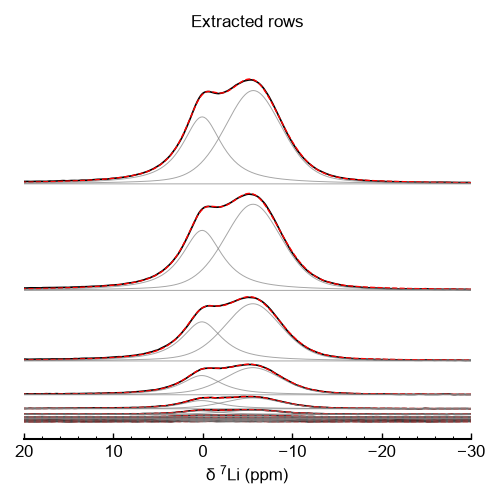

In [61]:
fig, ax = nmr.NMR2D_plot_slices(
    slices, mode="rows", fits=fitted["rows"],
    show_fits=True, show_fit_components=True,
    pl_width=5, pl_height=5,
    xlims=[20,-30]
)

Or combine the contour, fitted slices, and integrals in one figure:

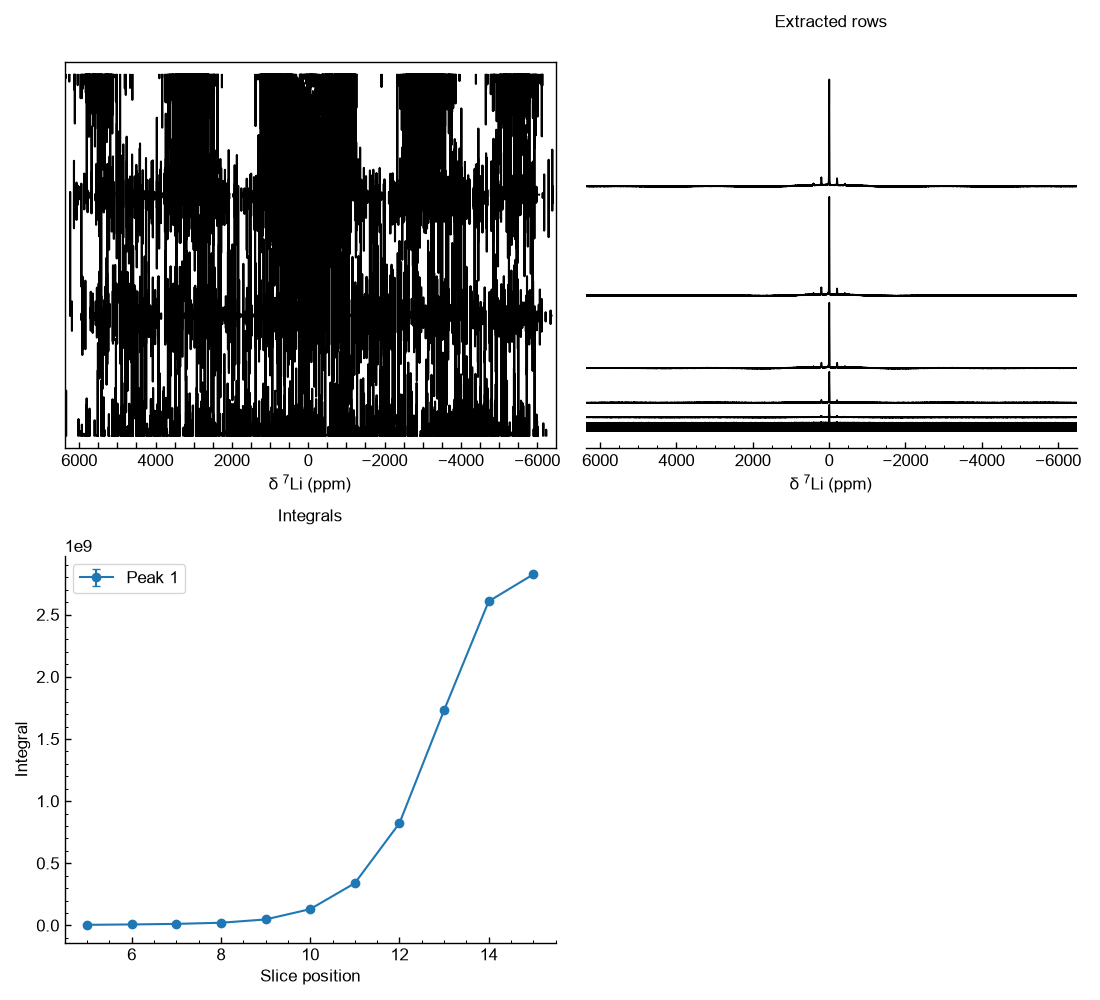

In [62]:
integral_curves = [{
    "x": [f["shift"] for f in fitted["rows"]],
    "y": [f["integrals"][0] for f in fitted["rows"]],
    "yerr": [f["integral_errors"][0] for f in fitted["rows"]],
    "label": "Peak 1",
}]

fig, axes = nmr.NMR2D_summary_plot(
    ds, slices=slices, fits=fitted["rows"], integrals=integral_curves,
    slices_mode="rows", layout="grid",
)

Or, all of the above in a single call:


2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 9.803828
  fwhm      = 7.600000 ± 15.358850
  amplitude = 218252.734280 ± 313366.498859
  eta       = 0.300000 ± 3.248408
  integral (raw) = 2017317.1845
  integral (%)    = 28.50

Peak 2 (pseudo-voigt):
  shift     = -1.000000 ± 1.340907
  fwhm      = 5.200000 ± 2.768374
  amplitude = 686068.806028 ± 652884.552246
  eta       = 0.700000 ± 1.490597
  integral (raw) = 5060989.2117
  integral (%)    = 71.50

Fit quality:
------------------------------------------------------------
RMSE          : 7.793583e+06
Chi^2         : 3.980653e+18
Reduced Chi^2 : 6.074921e+13


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6


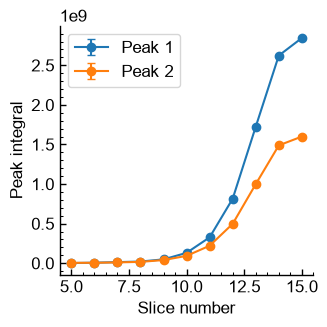

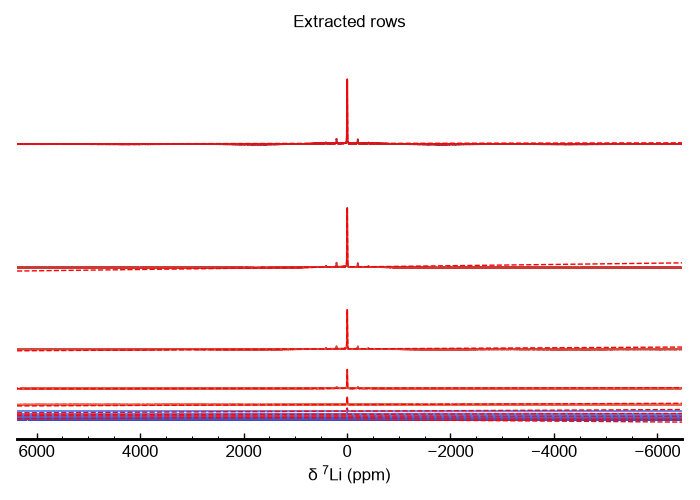

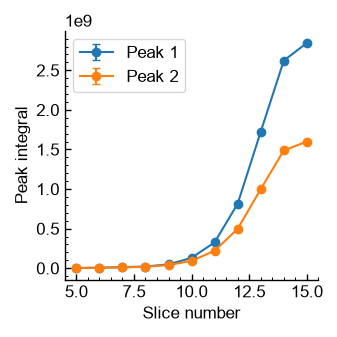

In [63]:
out = nmr.NMR2D_workflow(
    r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2",
    peak_defs=peak_defs,
    rows=list(range(5, 16)),
    fit_regions=[(20,-30)],
    baseline_regions=[(-150,-50)],
    normalise=False,
    show_slices=True, show_fits=True, show_integrals=True,
    show_report=False, show_warnings=True
)

out["rows"]["slices"]           # extracted traces
out["rows"]["fits"]             # fit results, same schema as NMR2D_fit_slices output
out["rows"]["figure"]           # the extracted-slices plot
out["rows"]["integral_figure"]  # the integrals plot

## 9. Fit relaxation curves (T1 / T2 / T1rho) from a 2-d dataset

`nmrtools.relaxation` fits a named model (see
`nmrtools.relaxation.RELAXATION_MODELS`) to each peak's integral series
across a pseudo-2D relaxation experiment:

```
NMR2D_get_slices -> [NMR2D_fit_slices | NMR2D_integrate_slices]
                  -> NMR2D_fit_relaxation -> NMR2D_plot_relaxation
```

or all of that in one call with `NMR2D_relaxation_workflow`. Delay times
are read automatically from the dataset's Bruker `vdlist` unless you
pass one explicitly.

Available models: `saturation_recovery`, `inversion_recovery` (T1);
`exponential_decay` (T2, or T1rho from a spin-lock decay); their
`biexponential_*` counterparts for two resolvable components; and
`stretched_decay`/`stretched_recovery` (Kohlrausch-Williams-Watts) for a
distribution of relaxation times. T1rho experiments reuse the T1/T2
functional forms -- just relabel the reported rate constant yourself.


### 9.1 End-to-end with `NMR2D_relaxation_workflow`

As with `NMR2D_workflow`, this drives the whole pipeline in one call.
`annotate=True` labels each fitted curve directly on the plot with its
rate constant; `colors` sets each series' data-point colour (the fit
curve is automatically drawn as a paler shade of the same colour, so
the two stay visually tied). `annotate_position`, `annotate_offset` and
`annotate_ha`/`annotate_va` control exactly where each label sits --
either a single value applied to every series, or a list with one entry
per series (in the order given, after any `show_series` filtering).


In [64]:
nmr.RELAXATION_MODELS

{'saturation_recovery': {'func': <function opennmr.notebook.relaxation.saturation_recovery(t, M0, T1)>,
  'params': ['M0', 'T1'],
  'p0': <function opennmr.notebook.relaxation._p0_mono(t, y)>,
  'bounds': <function opennmr.notebook.relaxation._bounds_mono(t, y)>,
  'rate_param': 'T1'},
 'inversion_recovery': {'func': <function opennmr.notebook.relaxation.inversion_recovery(t, M0, T1, C=2.0)>,
  'params': ['M0', 'T1', 'C'],
  'p0': <function opennmr.notebook.relaxation._p0_mono_C(t, y)>,
  'bounds': <function opennmr.notebook.relaxation._bounds_mono_C(t, y)>,
  'rate_param': 'T1'},
 'exponential_decay': {'func': <function opennmr.notebook.relaxation.exponential_decay(t, M0, T2)>,
  'params': ['M0', 'T2'],
  'p0': <function opennmr.notebook.relaxation._p0_mono(t, y)>,
  'bounds': <function opennmr.notebook.relaxation._bounds_mono(t, y)>,
  'rate_param': 'T2'},
 'biexponential_decay': {'func': <function opennmr.notebook.relaxation.biexponential_decay(t, A1, T2a, A2, T2b)>,
  'params': ['A


2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 9.803828
  fwhm      = 7.600000 ± 15.358850
  amplitude = 218252.734280 ± 313366.498859
  eta       = 0.300000 ± 3.248408
  integral (raw) = 2017317.1845
  integral (%)    = 28.50

Peak 2 (pseudo-voigt):
  shift     = -1.000000 ± 1.340907
  fwhm      = 5.200000 ± 2.768374
  amplitude = 686068.806028 ± 652884.552246
  eta       = 0.700000 ± 1.490597
  integral (raw) = 5060989.2117
  integral (%)    = 71.50

Fit quality:
------------------------------------------------------------
RMSE          : 7.793583e+06
Chi^2         : 3.980653e+18
Reduced Chi^2 : 6.074921e+13


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6


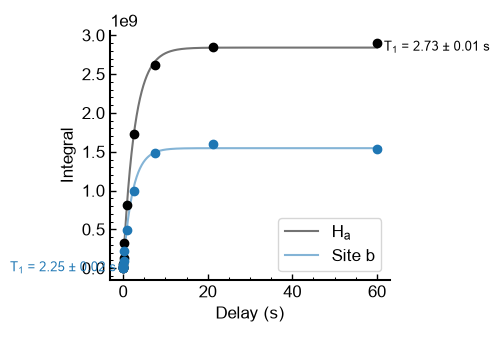

In [65]:
peak_defs = [
    {"type": "pseudo-voigt", "shift": -5.69, "fwhm": 7.62, "eta" : 0.35,
     "bounds": {"shift": (-5.58, -5.70), "fwhm" : (7.6, 7.7), "eta" : (0.3, 0.4)}},
    {"type": "pseudo-voigt", "shift": -0.005, "fwhm": 5.28, "eta" : 0.8,
     "bounds": {"shift": (0.5, -1.0), "fwhm" : (5.2, 5.4), "eta" : (0.7, 0.9)}},
]

fitted_satrec = nmr.NMR2D_relaxation_workflow(
    r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2",
    peak_defs=peak_defs,
    rows=list(range(5, 17)),
    fit_regions=[(20, -30)],
    baseline_regions=[(-150, -50)],
    show_report=True,
    normalise=False,
    model='saturation_recovery',
    peak_labels=[r'$\mathregular{H}_{a}$', 'Site b'],
    annotate=True,                        # label each curve with its fitted T1
    colours=['black', 'tab:blue'],          # one data colour per peak
    annotate_position=['end', 'start'],    # per-series label placement along the curve
    annotate_offset=[(5, 0), (-5, 0)],     # (dx, dy) in points, per series
    annotate_ha=['left', 'right'],
    pl_width=5.0,
    show_top_spine=False, show_right_spine=False,
    logplot=False,
)

print(fitted_satrec["relaxation_fits"][0]["params"])  # fitted M0, T1 for peak 1


### 9.2 Driving it manually, for finer control

Useful for trying several models against the same fitted slices without
re-fitting the peaks each time, or for tuning colours/label placement
after seeing a first draft. `colors`, `fit_colors`, `fit_shade`,
`annotate_position`, `annotate_offset`, `annotate_ha` and `annotate_va`
are all exposed directly on `NMR2D_plot_relaxation`:



2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 9.803828
  fwhm      = 7.600000 ± 15.358850
  amplitude = 218252.734280 ± 313366.498859
  eta       = 0.300000 ± 3.248408
  integral (raw) = 2017317.1845
  integral (%)    = 28.50

Peak 2 (pseudo-voigt):
  shift     = -1.000000 ± 1.340907
  fwhm      = 5.200000 ± 2.768374
  amplitude = 686068.806028 ± 652884.552246
  eta       = 0.700000 ± 1.490597
  integral (raw) = 5060989.2117
  integral (%)    = 71.50

Fit quality:
------------------------------------------------------------
RMSE          : 7.793583e+06
Chi^2         : 3.980653e+18
Reduced Chi^2 : 6.074921e+13


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6


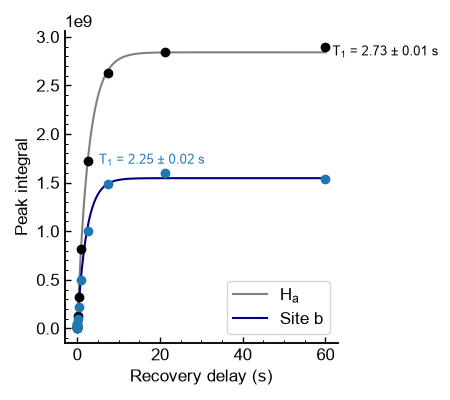

In [66]:
ds = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2")
slices = nmr.NMR2D_get_slices(ds, rows=list(range(5, 17)))

fitted = nmr.NMR2D_fit_slices(
    slices, peak_defs, mode="rows",
    fit_regions=[(20, -30)], baseline_regions=[(-150, -50)],
    show_report=False, show_warnings=True,
)

relax_fits = nmr.NMR2D_fit_relaxation(
    fitted["rows"], model="saturation_recovery",
    peak_labels=[r'$\mathregular{H}_{a}$', 'Site b'],
    use_errors=True,   # weight the fit by each slice's propagated integral error
    show_report=True,
)

fig, ax = nmr.NMR2D_plot_relaxation(
    relax_fits,
    annotate=True,
    colours=['black', 'tab:blue'],     # data-point colour per series
    fit_colours=[None, 'navy'],        # None -> auto pale tint of the data colour; override just Site b
    fit_shade=0.5,                    # paleness of the *automatic* fit curves (ignored where fit_colors is set)
    annotate_position=['end', 0.3],   # 'start' / 'middle' / 'end', or a 0-1 fraction along the curve
    annotate_offset=[(5, 0), (0, 8)],
    annotate_ha=['left', 'center'],
    annotate_va=['center', 'bottom'],
    xlabel="Recovery delay (s)", ylabel="Peak integral",
    pl_width=4.5, pl_height=4.0,
)


Delays come from the dataset's own `vdlist` by default (resolved from
`fitted["rows"]`). Pass one explicitly -- a Bruker experiment path, the
dict from `read_vdlist`, or a plain array of seconds (1-based F1 index)
-- if the pseudo-2D wasn't acquired with a Topspin `vdlist`, or to
override it:


In [81]:
vd = nmr.read_vdlist(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2")

relax_fits = nmr.NMR2D_fit_relaxation(fitted["rows"], model="saturation_recovery", vdlist=vd)
# or: vdlist=r"...\2"                         (a Bruker experiment path)
# or: vdlist=[0.001, 0.01, 0.1, 1.0, 5.0, ...]  (seconds, one per slice)



--- Peak 1 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 2.84118e+09 ± 7.424e+06
  T1      = 2.73152 ± 0.01354

  T1 = 2.73 ± 0.01 s

  RMSE          = 2.307e+07
  Reduced chi^2 = 21.51


--- Peak 2 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 1.54596e+09 ± 8.959e+06
  T1      = 2.24984 ± 0.02436

  T1 = 2.25 ± 0.02 s

  RMSE          = 2.778e+07
  Reduced chi^2 = 26.17



### 9.3 Region-based integration, when individual peaks aren't resolved

If peaks are too overlapping/poorly resolved to be worth fitting,
integrate bulk regions instead with `NMR2D_integrate_slices` -- its
output is shaped closely enough to `NMR2D_fit_slices`'s that it drops
straight into `NMR2D_fit_relaxation` in place of a fitted-peaks series:


In [67]:
region_series = nmr.NMR2D_integrate_slices(
    slices, regions=[[3.4, 4.5], [4.5, 8.0]], mode="rows",
    region_labels=["Region 1", "Region 2"],
    subtract_baseline=True, baseline_regions=[(-150, -50)],
)

relax_fits_regions = nmr.NMR2D_fit_relaxation(
    region_series["rows"], model="saturation_recovery",
    peak_labels=["Region 1", "Region 2"],
)



--- Region 1 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 6.29104e+07 ± 1.059e+06
  T1      = 2.49842 ± 0.1664

  T1 = 2.50 ± 0.17 s

  RMSE          = 1.616e+06
  Reduced chi^2 = 0.1294


--- Region 2 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 1.30699e+08 ± 2.295e+06
  T1      = 2.35966 ± 0.1602

  T1 = 2.36 ± 0.16 s

  RMSE          = 5.771e+06
  Reduced chi^2 = 0.1918



### 9.4 Fitting an arbitrary `(t, y)` array directly

`fit_relaxation` isn't tied to 2-d datasets at all -- fit any delay/
intensity series directly, e.g. integrals you've already extracted by
some other route:


In [68]:
import numpy as np

t = np.array([0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0])
y = np.array([120, 480, 800, 1850, 2400, 2700, 2820])

fit = nmr.fit_relaxation(t, y, model="saturation_recovery")
nmr.print_relaxation_report(fit)

# format_time_value auto-picks a sensible unit (s/ms/us/ns) for display
print(nmr.format_time_value(fit["params"]["T1"], fit["errors"]["T1"]))



RELAXATION FIT REPORT (saturation_recovery)
  M0      = 2717.03 ± 94.45
  T1      = 0.394782 ± 0.054

  T1 = 395 ± 54 ms

  RMSE          = 116.7
  Reduced chi^2 = 1.906e+04

395 ± 54 ms


The same `rows=` -> `columns=` swap works throughout (`NMR2D_get_slices`,
`NMR2D_relaxation_workflow`) if what you actually want is column
extraction/fitting (*e.g.* a T1 buildup along F1 at a fixed F2 shift)
instead of rows.


## 10. Fitting pseudo-2d datasets with CSA models

Before trusting a frozen shape across an entire delay series, fit ONE
high-S/N spectrum by hand -- e.g. the shortest-delay (most-inverted) or the
longest-delay (fully-relaxed) row, whichever has the best signal, or a
separate reference scan entirely if you have one. This is just
`NMRCSAFitWorkflow` on a single 1D spectrum (see the previous notebook /
conversation for more on its options); use it to settle on:

- the number of sites and a reasonable `p0` for each,
- `lineshape` ('gaussian', 'lorentzian', or 'pseudo_voigt') and, if
  pseudo-Voigt, starting `eta` values,
- which shape parameters are free vs. `fixed` per site,
- a `powder_scheme`/`n_zcw` (or `n_theta`/`n_phi`) that's converged.

This fit is *not* automatically reused by the relaxation workflow below --
`NMR2D_csa_relaxation_workflow` does its own reference-slice fit internally,
using the same `p0` you pass it. This step is purely for you to check the
model is sensible before committing to fitting (and freezing) it across the
whole series.

### 10.1 Start with fitting a 1-d dataset


CSA FIT REPORT (Haeberlen convention, 2 sites)

Parameters:
------------------------------------------------------------
  Site 1: d_iso      = -5.724165 ± 0.009595
  Site 1: Delta      = -187.726701 ± 1.264217
  Site 1: eta        = 0.510887 ± 0.040151
  Site 1: fwhm       = 7.655878 ± 0.019289
  Site 1: amplitude  = 16778978872.160200 ± 24811488.230019
  Site 1: pv_mix_eta = 0.288336 ± 0.006524
  Site 2: d_iso      = -0.089034 ± 0.008467
  Site 2: Delta      = -196.496551 ± 2.248558
  Site 2: eta        = 1.000000 ± 0.042051
  Site 2: fwhm       = 5.259582 ± 0.020487
  Site 2: amplitude  = 11094929501.586327 ± 40982045.805804
  Site 2: pv_mix_eta = 0.813488 ± 0.009088
  b0                 = 199786498.886274 (fixed)
  b1                 = 16358.649507 (fixed)

Fit quality:
------------------------------------------------------------
RMSE          : 5.302922e+07
Chi^2         : 1.719598e+19
Reduced Chi^2 : 2.818551e+15


Warnings:
------------------------------------------------------

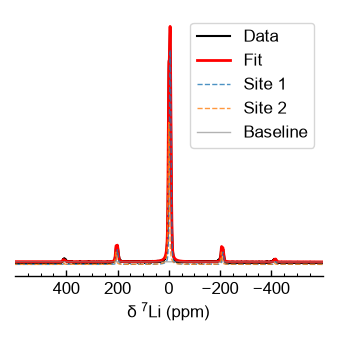

In [15]:
spec_to_fit = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\1"

# Two 7Li sites, both pseudo-Voigt-broadened. fwhm/eta held fixed (assumed
# to reflect instrumental/homogeneous broadening, determined once), CSA
# tensor parameters (span_or_Delta, skew_or_eta) left free.
peak_defs = [
    {"label": "Site 1", "d_iso": -5.693, "fwhm": 7.617, "eta": 0.350,
     "span_or_Delta": -200, "skew_or_eta": 0.8,
     "fixed": {"d_iso": True, "fwhm": True, "eta": True,
               "span_or_Delta": False, "skew_or_eta": False}},
    {"label": "Site 2", "d_iso": -0.005, "fwhm": 5.283, "eta": 0.799,
     "span_or_Delta": -200, "skew_or_eta": 1.0,
     "fixed": {"d_iso": True, "fwhm": True, "eta": True,
               "span_or_Delta": False, "skew_or_eta": True}},
]

reference_check = nmr.NMRCSAFitWorkflow(
    spec_to_fit,
    p0=peak_defs,
    static=False,
    normalise=False,
    larmor_Hz=None,
    mas_Hz=40000,
    lineshape="pseudo_voigt",
    fit_regions=[(-600, 600)],
    baseline_regions=[(50, 150), (-150, -50)],
    show_plot=True,
    show_report=True,
    show_components=True,
    powder_scheme='zcw',
    n_zcw=320,
)

### 10.2. Fit the whole T1 (or T2) series

`NMR2D_csa_relaxation_workflow` imports the pseudo-2D dataset once, extracts
the requested rows (delay slices), fits the CSA lineshape (frozen after one
reference-slice fit by default), extracts each site's integral vs. delay,
and fits a relaxation model to each -- see `nmr.RELAXATION_MODELS` for the
available models (`inversion_recovery`, `exponential_decay`,
`saturation_recovery`, `stretched_decay`, `stretched_recovery`,
`biexponential_decay`, `biexponential_recovery`).

`rows` are the 1-based F1 (delay) indices to extract -- set these to match
your pseudo-2D experiment (e.g. `list(range(1, n_delays + 1))` for every
row). `vdlist=None` auto-resolves delay times (seconds) from the Bruker
vdlist file found in `datapath`; pass an explicit path, a
`nmrtools.utils.read_vdlist()` dict, or a plain array of seconds instead if
that resolution doesn't apply to your dataset.


CSA FIT REPORT (Haeberlen convention, 2 sites)

Parameters:
------------------------------------------------------------
  Site 1: d_iso      = -5.721159 ± 0.010136
  Site 1: Delta      = -184.052598 ± 1.492782
  Site 1: eta        = 0.669000 ± 0.038917
  Site 1: fwhm       = 7.762532 ± 0.021318
  Site 1: amplitude  = 314276776.986876 ± 508159.935600
  Site 1: pv_mix_eta = 0.331301 ± 0.006912
  Site 2: d_iso      = -0.048912 ± 0.008508
  Site 2: Delta      = -204.126035 ± 2.317472
  Site 2: eta        = 0.859578 ± 0.045116
  Site 2: fwhm       = 4.981145 ± 0.021114
  Site 2: amplitude  = 210027003.853811 ± 840731.685727
  Site 2: pv_mix_eta = 0.780697 ± 0.010257
  b0                 = 4144098.118627 (fixed)
  b1                 = -1412.212351 (fixed)

Fit quality:
------------------------------------------------------------
RMSE          : 1.122592e+06
Chi^2         : 7.706201e+15
Reduced Chi^2 : 1.263105e+12


--- Site 1 ---

RELAXATION FIT REPORT (inversion_recovery)
  M0      = 3.2

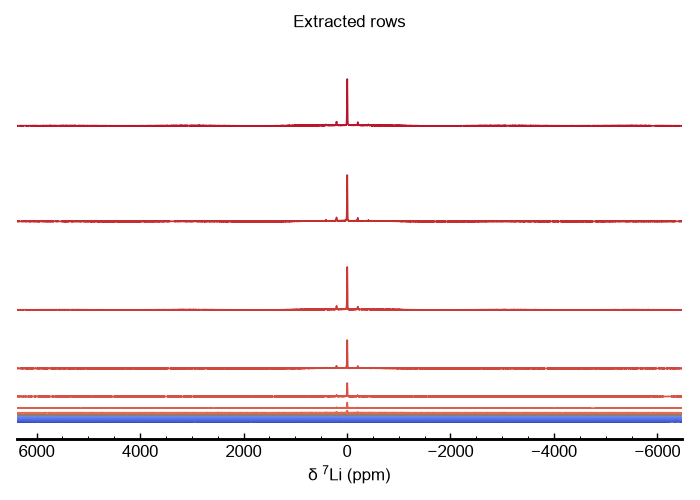

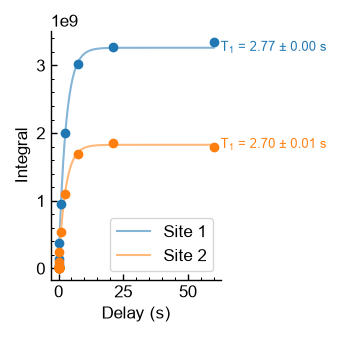

In [16]:
datapath = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2"

result = nmr.NMR2D_csa_relaxation_workflow(
    datapath,
    p0=peak_defs,
    procno=1,
    rows=list(range(1, 17)),            # adjust to the number of delays in your series
    static=False,
    normalise=False,
    larmor_Hz=None,
    mas_Hz=40000,
    lineshape="pseudo_voigt",
    fit_regions=[(-600, 600)],
    baseline_regions=[(50, 150), (-150, -50)],
    powder_scheme='zcw',
    n_zcw=320,
    freeze_shape=True,                  # default: fit the CSA shape once, amplitude+baseline per slice thereafter
    reference="max_amplitude",          # or an explicit 0-based index into the selected rows
    model="inversion_recovery",         # T1; use "exponential_decay" for a T2/T1rho decay series
    vdlist=None,                        # auto-resolved from the Bruker vdlist file in `datapath`
    show_slices=True,
    show_fit=True,
    show_report=True,
)

### 10.3. Inspect the results

`result` contains:

- `"dataset"`, `"slices"` -- the imported dataset and extracted row traces.
- `"series"` -- one CSA fit per delay slice (from `NMR2D_fit_csa_slices`):
  each has `"popt"`, `"pcov"`, `"integrals"`, `"integral_errors"`, `"index"`,
  `"is_reference"`, etc.
- `"relaxation_fits"` -- one relaxation-curve fit per site (from
  `NMR2D_fit_relaxation`): `"params"`, `"errors"`, `"rate_param"`,
  `"fit_quality"`, `"t"`, `"y"`, `"y_fit"`.
- `"figure"`/`"axes"` -- the relaxation plot; `"slices_figure"`/
  `"slices_axes"` -- the stacked raw spectra, if `show_slices=True`.

In [9]:
for fit in result["relaxation_fits"]:
    rate_name = fit["rate_param"]
    if rate_name is None:
        # biexponential models have two rate constants, not one -- print both
        print(f"{fit['peak_label']}: {fit['params']}")
        continue
    rate_value = fit["params"][rate_name]
    rate_error = fit["errors"][rate_name]
    print(f"{fit['peak_label']}: {rate_name} = {rate_value:.4g} +/- {rate_error:.2g} s")

Site 1: T1 = 2.766 +/- 0.0034 s
Site 2: T1 = 2.705 +/- 0.006 s


In [14]:
# Per-slice CSA fit quality and integrals, in delay order as fitted
# (result["series"] is in the row order NMR2D_get_slices returned them, not
# necessarily delay order -- result["relaxation_fits"][i]["t"]/["y"] are the
# sorted, delay-ordered series actually used for the relaxation fit).
for s in result["series"]:
    flag = " (reference fit)" if s["is_reference"] else ""
    print(f"row index {s['index']:>3}{flag}: "
          f"rmse={s['fit_quality']['rmse']:.4f}  "
          f"integrals={np.round(s['integrals'], 3)}")

row index   1: rmse=322003.5409  integrals=[5445856.611 7295024.145]
row index   2: rmse=327737.1237  integrals=[7949053.94  2991206.543]
row index   3: rmse=328035.6527  integrals=[4277953.944 7200525.64 ]
row index   4: rmse=328616.7707  integrals=[5003721.582 7689375.886]
row index   5: rmse=340272.1386  integrals=[6208317.204 7829487.654]
row index   6: rmse=324659.6207  integrals=[9309672.723 7187112.874]
row index   7: rmse=327516.5030  integrals=[13576226.753  9892044.99 ]
row index   8: rmse=327760.0192  integrals=[23868186.407 18561306.654]
row index   9: rmse=337496.0058  integrals=[53457272.524 42004949.979]
row index  10: rmse=337800.2726  integrals=[1.42522325e+08 1.01218761e+08]
row index  11: rmse=357604.9703  integrals=[3.79229591e+08 2.36687615e+08]
row index  12: rmse=505233.0048  integrals=[9.45559424e+08 5.45173360e+08]
row index  13: rmse=813264.9097  integrals=[1.99836829e+09 1.10658897e+09]
row index  14: rmse=1069712.3473  integrals=[3.01950609e+09 1.68867654e+0

### 10.4. Lower-level control (optional)

If you want to inspect or adjust the per-slice CSA fits before committing to
a relaxation fit -- e.g. try a different `reference` slice, compare
`freeze_shape=True` vs `False`, or refit only a subset of sites -- call the
building blocks directly instead of the one-shot workflow function:

```python
dataset = nmr.NMR2dimport(datapath, procno=1)

slices = nmr.NMR2D_get_slices(dataset, rows=list(range(1, 17)))

csa_fits = nmr.NMR2D_fit_csa_slices(
    slices, peak_defs, mode="rows",
    static=False, larmor_Hz=None, mas_Hz=40000,
    lineshape="pseudo_voigt",
    fit_regions=[(-600, 600)],
    baseline_regions=[(50, 150), (-150, -50)],
    powder_scheme='zcw', n_zcw=320,
    freeze_shape=True, reference="max_amplitude",
    show_report=True,
)["rows"]

labels = csa_fits[0]["labels"]

relaxation_fits = nmr.NMR2D_fit_relaxation(
    csa_fits, model="inversion_recovery", peak_labels=labels,
)

fig, ax = nmr.NMR2D_plot_relaxation(relaxation_fits, annotate=True)
```

This is exactly what `NMR2D_csa_relaxation_workflow` does internally --
useful when you want to pause and inspect `csa_fits` (e.g. plot a couple of
individual slice fits with `nmr.NMR1dplot_with_csa_fit`) before running the
relaxation fit, or when you want to reuse the same `csa_fits` against two
different relaxation models for comparison without re-running the (more
expensive) CSA fitting step.

### A few things worth checking before trusting the result

- **Look at the reference-slice fit** (`show_report=True` above, or
  `reference_check` from Section 1) -- if the shape parameters there are
  poorly determined (large uncertainties, parameters sitting at a bound),
  everything downstream inherits that, silently, since every other slice
  reuses it verbatim.
- **Check `result["series"]`'s `fit_quality["r_squared"]`** across all
  slices, not just the reference -- a frozen shape that fits the reference
  slice well can still fit a late-delay (low S/N) slice badly if the true
  baseline or a nearby unmodelled feature becomes non-negligible relative to
  the shrinking signal.
- **`freeze_shape=True`'s reported integral errors treat the reference
  slice's shape as exact** (see `compute_csa_integral_errors` docs) -- if
  the reference fit's `span_or_Delta`/`skew_or_eta`/`eta` themselves have
  large uncertainties, your relaxation-curve error bars are probably
  optimistic. Consider this a known limitation, not a bug.
- **If a site's integral doesn't look monotonic with delay** (ignoring
  noise), check whether `positive_intensity=True` (the default) is
  clipping an amplitude that legitimately wants to go negative partway
  through an inversion-recovery series.

## 10. BMS Simulation: predicting Bulk Magnetic Susceptibility shifts from a particle packing

The `bms` sub-package predicts the NMR shift caused by the bulk magnetic
susceptibility (BMS) of a packing of anisotropic particles -- e.g. platelets
or needles of a magnetic phase dispersed in a diamagnetic matrix. Given the
particles' positions, sizes/shapes, orientations, and principal-axis
magnetic susceptibility, it computes the demagnetizing field on a 3-d grid,
converts that into a bulk-susceptibility shift tensor at every grid point,
and (optionally) turns the resulting distribution of shifts into a
MAS-spinning-sideband-broadened lineshape.

The top-level, recommended entry point is `nmr.generate_bms_spectrum_dict`,
which returns the same 10-key `spectrum_dict` as every other spectrum in
`opennmr` (`x_ppm`, `real_spectrum`, `normalised_real_spectrum`, ...) --
so a BMS-predicted lineshape plots and overlays with an experimental one
using the exact same `plot_spectrum_dict`/`plot_comparison` functions from
Section 1, no BMS-specific plotting code required.

The lower-level pieces it's built from (`run_bms`, `run`, `build_box`,
`particles_to_array`, `assemble_spectrum`, ...) aren't re-exported at the
top level -- import them from `opennmr.notebook.bms` directly, as shown in
9.5-9.8 below, if you want the per-voxel table without a spectrum, or want
to drive an individual step yourself.

### 10.1 Build particles with `make_particle`

`make_particle(x, y, z, size, quaternion=(1,0,0,0), id=None)` builds one
particle record -- no LAMMPS dump file required. `size` is a 3-tuple whose
meaning depends on the `equation` you pass to the simulation call below:

| `equation`   | `size` meaning                          |
|--------------|------------------------------------------|
| `"ellipsoid"`| (semi-axis-x, semi-axis-y, semi-axis-z)  |
| `"hexagonal"`| (hex radius, unused, height)             |
| `"donut"`    | (major radius R0, minor radius r0, unused)|

`quaternion` is `(qw, qx, qy, qz)` (scalar-first, needn't be pre-normalized);
the default `(1,0,0,0)` is "no rotation".

In [27]:
particles = [
    nmr.make_particle(x=0,   y=0, z=0, size=(60, 60, 10)),
    nmr.make_particle(x=150, y=0, z=0, size=(60, 60, 10),
                       quaternion=(0.707, 0.707, 0, 0)),   # tilted 90 deg about x
    nmr.make_particle(x=-150, y=0, z=0, size=(60, 60, 10)),
]
particles

[{'id': None,
  'x': 0,
  'y': 0,
  'z': 0,
  'v1': 60,
  'v2': 60,
  'v3': 10,
  'qi': 0.0,
  'qj': 0.0,
  'qk': 0.0,
  'qr': 1.0},
 {'id': None,
  'x': 150,
  'y': 0,
  'z': 0,
  'v1': 60,
  'v2': 60,
  'v3': 10,
  'qi': 0.707,
  'qj': 0,
  'qk': 0,
  'qr': 0.707},
 {'id': None,
  'x': -150,
  'y': 0,
  'z': 0,
  'v1': 60,
  'v2': 60,
  'v3': 10,
  'qi': 0.0,
  'qj': 0.0,
  'qk': 0.0,
  'qr': 1.0}]

### 10.2 One-call simulation + spectrum: `generate_bms_spectrum_dict`

This runs the full pipeline -- demagnetizing field -> BMS shift tensor ->
MAS-sideband-broadened spectrum -- and packages the result as a standard
`spectrum_dict`. `nuclide` + `B0_tesla` are resolved to `BF1`/`SFO1` through
the same gyromagnetic-ratio table used by `NMR1dimport`, so a BMS-predicted
spectrum references identically to an imported experimental one.

In [28]:
bms_spectrum, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),  # (chi_1, chi_2, chi_3), principal-axis

    nuclide="7Li",
    B0_tesla=18.8,
    spin_rate_hz=60000,

    # -- particle-shape parameters (match the `equation` used in make_particle above) --
    box_size=600.0,        # full side length of the (cubic, origin-centred) sim box, or (sx, sy, sz)
    gridpoints=128,        # FFT grid resolution per axis
    equation="hexagonal",  # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",       # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=2, t=2,               # shape-function exponents
    slope_filter=2000,      # steepness of the particle edge (higher = sharper boundary)
    threshold=0.99,         # shape-function value above which a grid point counts as "inside" a particle

    # local_shift_contribution / rotor_contribution: (3,3) arrays added to the
    # shift tensor at "inside" grid points -- leave as None (-> zero) unless
    # you have real values for these.
    local_shift_contribution=[[-850, -126, -80.42],
                              [-126.47, 529.61, 39.46],
                              [-80.42, 39.46, 368.39]],
    rotor_contribution=[[327.5, 0, 0], [0, 327.5, 0], [0, 0, -655.0]],

    # -- spectrum-assembly parameters --
    linewidth_hz=50.0,     # Lorentzian linewidth (Hz), applied as a T2 decay
    n_points=16384,        # number of points in the output ppm axis
    sw_ppm=5000.0,          # total ppm sweep width, centred on 0 ppm
    max_order=8,           # highest spinning-sideband order kept in the lookup table
    offset_ppm=0.0,        # carrier offset from BF1, in ppm

    # -- bookkeeping --
    output_dir=None,        # None -> ./bms_simulation ; spectrum_dict['path'] is set to this
    save_voxel_table=True,  # also write <output_dir>/<nuclide>_bms_voxel_table.csv
    n_jobs=4,             # worker processes for the per-particle loop; None -> os.cpu_count()
)

### 10.3 Plot it -- exactly like any other `spectrum_dict`

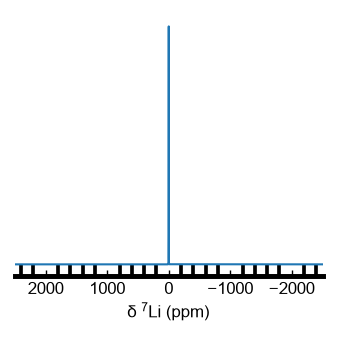

In [29]:
ax = nmr.plot_spectrum_dict(bms_spectrum, axis="ppm", channel="real", normalised=True)
plt.tight_layout()
plt.show()

# Overlay against an experimental spectrum the same way as Section 8.4:
# experimental_dict = nmr.NMR1dimport(r"...")
# ax = nmr.plot_comparison(bms_spectrum, experimental_dict)

### 10.4 Inspect the per-voxel table

`voxel_table` (also returned alongside `bms_spectrum`, and written to CSV
when `save_voxel_table=True`) has one row per evaluation grid point, with
columns `x, y, z, d_iso, delta, eta, N1, N2, N3` -- the position, the
Haeberlen-convention shift parameters, and the three demagnetizing-tensor
eigenvalues at that point.

In [ ]:
voxel_table.head()

,x,y,z,d_iso,delta,eta,N1,N2,N3
0,-300.0,-300.0,-300.0000,-0.003284,1.301802,0.085989,-0.000508,0.000240,0.000268
1,-300.0,-300.0,-295.3125,-0.002213,1.325775,0.086122,-0.000517,0.000244,0.000273
2,-300.0,-300.0,-290.6250,-0.001085,1.350211,0.086216,-0.000526,0.000248,0.000277
3,-300.0,-300.0,-285.9375,0.000101,1.375112,0.086270,-0.000535,0.000252,0.000282
4,-300.0,-300.0,-281.2500,0.001348,1.400484,0.086283,-0.000544,0.000257,0.000287


### 10.5 Lower-level: just the per-voxel table, no spectrum

If you only want the demag/shift calculation (e.g. to inspect the field
directly, or assemble several spectra from one simulation without
re-running the FFT step each time -- see 9.8), call `run_bms` directly. It
takes the same particle/box/shape parameters as `generate_bms_spectrum_dict`
minus the nuclide-specific spectrum-assembly ones, and returns just the
DataFrame.

In [30]:
from opennmr.notebook.bms import run_bms, build_box, particles_to_array

df = run_bms(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    box_size=600.0,
    gridpoints=128,
    equation="ellipsoid",
    deformation="A",
    out_dir=None,   # pass a directory to also write BMS_out.csv
    n_jobs=None,
)
df.head()

,x,y,z,d_iso,delta,eta,N1,N2,N3
0,-300.0,-300.0,-300.0000,-0.003284,1.301802,0.085989,-0.000508,0.000240,0.000268
1,-300.0,-300.0,-295.3125,-0.002213,1.325775,0.086122,-0.000517,0.000244,0.000273
2,-300.0,-300.0,-290.6250,-0.001085,1.350211,0.086216,-0.000526,0.000248,0.000277
3,-300.0,-300.0,-285.9375,0.000101,1.375112,0.086270,-0.000535,0.000252,0.000282
4,-300.0,-300.0,-281.2500,0.001348,1.400484,0.086283,-0.000544,0.000257,0.000287


### 10.6 Particles from a raw array, a LAMMPS dump, or a JSON input file

`particles_to_array` normalises a raw `(N,10)`/`(N,11)` array
(`x,y,z,v1,v2,v3,qi,qj,qk,qr`, optionally with a leading id column -- the
same layout a LAMMPS dump uses) into what `run_bms(particles=...)` expects,
as an alternative to building a list of `make_particle()` dicts by hand:

```python
particles_arr = particles_to_array(my_raw_array)  # -> (N,11) array
df = run_bms(particles=particles_arr, magnetic_susceptibility=(...), ...)
```

`build_box(size, gridpoints)` builds just the origin-centred box dict, if
you're assembling an input structure yourself rather than using `run_bms`'s
`box_size=`/`gridpoints=` shortcut.

For the original MATLAB-style workflow -- a `BMS_input*.json` file that
points at a LAMMPS particle-dump file on disk -- use `run` (imported as
`from opennmr.notebook.bms import run`) instead of `run_bms`:

```python
from opennmr.notebook.bms import run
df = run("BMS_input.json", out_dir="./bms_out", n_jobs=None)
```

### 10.7 Performance: `n_jobs`

Each particle's demagnetizing-field/shift calculation is independent of
every other particle, so `run`/`run_bms` parallelise the per-particle loop
across a process pool. `n_jobs=None` (the default) uses `os.cpu_count()`;
pass `n_jobs=1` to run serially in a single process, which is useful when
debugging or for very small particle counts where pool startup overhead
isn't worth it.

### 10.8 Advanced building blocks

These live in `opennmr.notebook.bms.<module>` and are what
`generate_bms_spectrum_dict`/`run_bms` are built from -- reach for them
directly only if you need to deviate from the standard pipeline:

- **`bms.spectrum.assemble_spectrum(df, spin_rate_hz, BF1, SFO1, nuclide, path, ...)`**
  -- turns a per-voxel table (from `run`/`run_bms`) into a `spectrum_dict`.
  Call this directly if you already have `BF1`/`SFO1` from elsewhere, or
  want to re-broaden/re-assemble the *same* voxel table (different
  `spin_rate_hz`, `linewidth_hz`, `sw_ppm`, ...) without re-running the
  demag/shift calculation.
- **`bms.mas_sidebands.sideband_manifold(delta, eta, spin_rate, iso=0.0, ...)`**
  -- computes the powder-averaged MAS spinning-sideband manifold (orders and
  relative intensities) for a single CSA-like `(delta, eta)` site, given a
  spin rate. Useful for checking a sideband pattern in isolation, without
  running a full particle simulation.
- **`bms.geometry.shape_function(sim_part, x, y, z)`** (and
  `ellipsoid_mask`/`hexagonal_mask`/`donut_mask`) -- the particle mask
  functions used internally; handy for plotting/checking a particle's shape
  directly (e.g. slicing it with matplotlib) before running the full
  simulation.

`verify_rotation_convention.py` (a standalone script, not a notebook
function -- run it from a terminal, not imported here) is worth running
once against your own particle-orientation data: it checks that the
quaternion rotation convention used by `geometry.py` matches what your
particle generator actually produces, using a tilted needle-shaped test
particle with a known expected orientation.

### 10.9 Visualizing particle shapes (`geometry.py`)

`shape_function(sim_part, x, y, z)` dispatches on `sim_part["Equation"]` to
`ellipsoid_mask`, `hexagonal_mask`, or `donut_mask` -- each returns a smooth
`0..1` occupancy value (`1` = fully inside the particle). Calling the mask
functions directly instead of through `shape_function` is identical --
`shape_function` is just the `Equation`-based dispatcher.

Note that `sim_part` here is one of the richer per-particle dicts built
internally by `inp_part` (or, for a one-off demo like below, hand-built) --
it carries the shape-function parameters (`r`, `t`, `sl`, `thresh`)
alongside the geometry (`v1, v2, v3`, `q`, `Deformation`), unlike the plain
dict `make_particle` returns. `quat_to_rotmat(q)` is the shared
quaternion-to-rotation-matrix helper all three mask functions use
internally -- see the orientation-convention caveats in `geometry.py`'s
module docstring and 9.14 below before trusting orientation-sensitive
results.

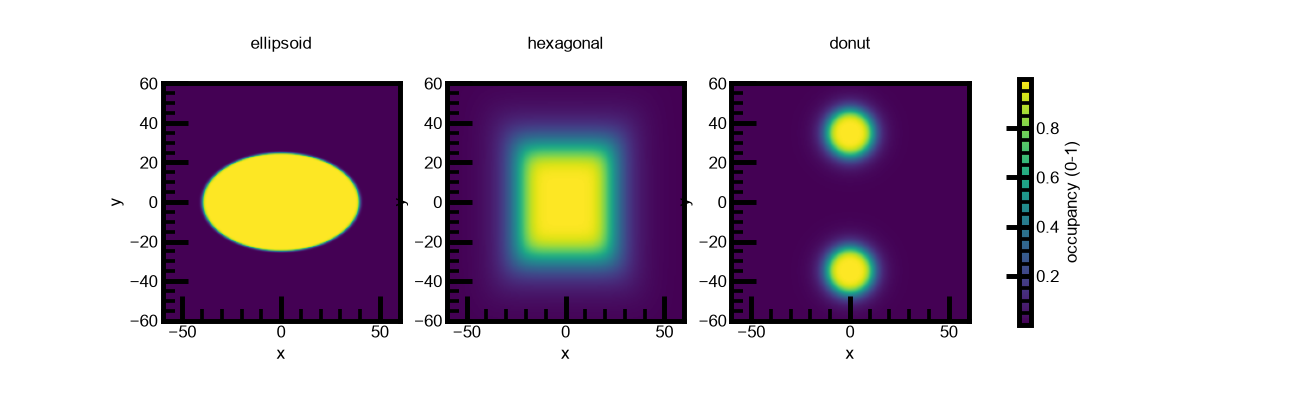

shape_function == ellipsoid_mask directly: True


array([[ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -2.22044605e-16,  1.00000000e+00],
       [ 0.00000000e+00, -1.00000000e+00, -2.22044605e-16]])

In [31]:
from opennmr.notebook.bms.geometry import (
    shape_function, ellipsoid_mask, hexagonal_mask, donut_mask, quat_to_rotmat,
)

def make_sim_part(equation, deformation, v1, v2, v3, q=(1, 0, 0, 0),
                   r=2, t=2, sl=50, thresh=0.99, posc=(0.0, 0.0, 0.0)):
    """A minimal stand-in for what `inp_part` builds, for demo purposes below."""
    return {
        "Equation": equation, "Deformation": deformation,
        "v1": v1, "v2": v2, "v3": v3,
        "q": np.array(q, dtype=float),
        "r": r, "t": t, "sl": sl, "thresh": thresh,
        "posc": np.array(posc, dtype=float),   # needed by simulate.evaluate, 9.12
        "vol": (4.0 / 3.0) * np.pi * v1 * v2 * v3,  # needed by evaluate's far-field fallback
    }

# a 2-d grid through z=0 to visualize each shape's cross-section
lin = np.linspace(-60, 60, 200)
X_, Y_ = np.meshgrid(lin, lin, indexing="ij")
Z_ = np.zeros_like(X_)

shapes = {
    "ellipsoid": make_sim_part("ellipsoid", "A", v1=40, v2=25, v3=25),
    "hexagonal": make_sim_part("hexagonal", "A", v1=30, v2=0, v3=50, sl=6),  # sl reused as hex exponent p
    "donut":     make_sim_part("donut",     "A", v1=35, v2=12, v3=0, sl=6), # sl reused as donut exponent p
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, sp) in zip(axes, shapes.items()):
    c0 = shape_function(sp, X_, Y_, Z_)
    im = ax.imshow(c0.T, origin="lower", extent=[lin[0], lin[-1], lin[0], lin[-1]])
    ax.set_title(name)
    ax.set_xlabel("x"); ax.set_ylabel("y")
fig.colorbar(im, ax=axes, shrink=0.8, label="occupancy (0-1)")
plt.show()

# shape_function is just the Equation-based dispatcher:
sp = shapes["ellipsoid"]
print("shape_function == ellipsoid_mask directly:",
      np.allclose(shape_function(sp, X_, Y_, Z_), ellipsoid_mask(sp, X_, Y_, Z_)))

# quat_to_rotmat on its own -- e.g. to check what rotation a given
# make_particle(..., quaternion=...) actually applies:
quat_to_rotmat([0.707, 0.707, 0, 0])  # ~90 deg about x, (qw,qx,qy,qz)

### 10.10 Visualizing the demagnetizing field for one particle (`demag.py`)

`build_kspace_kernel(sim_str)` builds the box's real-space/k-space grids
once -- this is the expensive part that `run`/`run_bms` build once per
worker process and reuse across particles (9.7). `demag_calc(sim_str,
sim_part, kernel=...)` then computes the raw (no `-1/3` correction)
demagnetizing tensor field for one particle on that grid via the
FFT/dipolar-kernel trick, returning a `(nx, ny, nz, 3, 3)` array. Passing
`kernel=None` (the default) rebuilds it automatically -- convenient for a
single one-off particle like below, but wasteful in a loop over many
particles on the same box.

kernel components: ['KX', 'KY', 'KZ', 'X', 'Y', 'Z', 'knsq', 'xvec', 'yvec', 'zvec']
demag_tensor shape: (32, 32, 32, 3, 3)


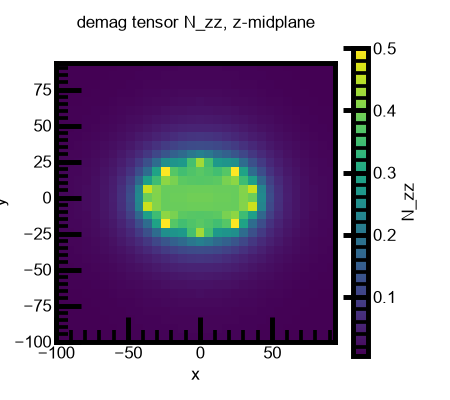

In [32]:
from opennmr.notebook.bms import build_box  # (already imported in 9.5, shown again here for clarity)
from opennmr.notebook.bms.io_utils import inp_sim
from opennmr.notebook.bms.demag import build_kspace_kernel, demag_calc

sim_str_demo = inp_sim(build_box(200, gridpoints=32))
kernel = build_kspace_kernel(sim_str_demo)
print("kernel components:", sorted(kernel.keys()))

sim_part_demo = make_sim_part("ellipsoid", "A", v1=40, v2=25, v3=25)
demag_tensor, (xvec, yvec, zvec) = demag_calc(sim_str_demo, sim_part_demo, kernel=kernel)
print("demag_tensor shape:", demag_tensor.shape)  # (nx, ny, nz, 3, 3)

# slice through the mid-plane (grid index nearest z=0)
zi = np.argmin(np.abs(zvec))
plt.figure(figsize=(4.5, 4))
plt.imshow(demag_tensor[:, :, zi, 2, 2].T, origin="lower",
           extent=[xvec[0], xvec[-1], yvec[0], yvec[-1]])
plt.colorbar(label="N_zz")
plt.title("demag tensor N_zz, z-midplane")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

### 10.11 Shift tensors for one particle (`shift.py`)

- `point_dipole(x, y, z)` -- the vectorized far-field point-dipole formula,
  used by `simulate.evaluate` (9.12) for evaluation points that fall
  outside the FFT grid.
- `shielding_bms(sim_part, demag_tensor)` -- multiplies by the particle's
  susceptibility tensor and applies the `-1/3` Lorentz-sphere correction
  wherever `trace(demag_tensor) > sim_part["thresh"]` (i.e. "inside" the
  particle core). Needs `sim_part["Chi_tensor"]` and `sim_part["thresh"]`
  -- both are set by `inp_part`, not by plain `make_particle`, so they're
  added by hand below for this one-off demo particle.
- `tensor2haeberlen(tensor)` -- eigendecomposes a `(..., 3, 3)` symmetric
  tensor field into `[iso, delta, eta]` (Haeberlen convention).

point_dipole shape: (3, 3, 3)
shift_tensor: (32, 32, 32, 3, 3)  haeb: (32, 32, 32, 3)


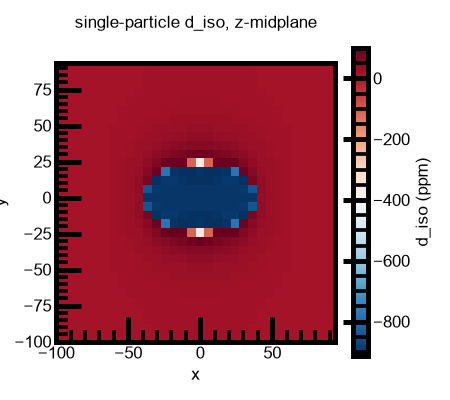

In [33]:
from opennmr.notebook.bms.shift import point_dipole, shielding_bms, tensor2haeberlen

# point_dipole is fully vectorized over array inputs
xs = np.array([100.0, 150.0, 200.0]); ys = np.zeros(3); zs = np.zeros(3)
T_dip = point_dipole(xs, ys, zs)
print("point_dipole shape:", T_dip.shape)  # (3, 3, 3)

sim_part_demo["Chi_tensor"] = np.diag([2.87e-3, 3.13e-3, 2.27e-3])
sim_part_demo["thresh"] = 0.99

shift_tensor = shielding_bms(sim_part_demo, demag_tensor)
haeb = tensor2haeberlen(shift_tensor)          # (..., [iso, delta, eta])
print("shift_tensor:", shift_tensor.shape, " haeb:", haeb.shape)

# visualize this one particle's own d_iso (haeb[...,0]) on the z-midplane
plt.figure(figsize=(4.5, 4))
plt.imshow(haeb[:, :, zi, 0].T, origin="lower", cmap="RdBu_r",
           extent=[xvec[0], xvec[-1], yvec[0], yvec[-1]])
plt.colorbar(label="d_iso (ppm)")
plt.title("single-particle d_iso, z-midplane")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

### 10.12 Low-level `simulate.evaluate`

This is what `run`/`run_bms` call once per particle: it takes the
`(nx, ny, nz, 3, 3)` demag tensor field from `demag_calc` and interpolates
it onto arbitrary evaluation points (`sim_str["evalpoints"]`, built by
`inp_sim`), falling back to `point_dipole` for points outside the FFT
grid. `compute_haeberlen=True` additionally returns that one particle's
own Haeberlen decomposition (off by default -- `run()` only needs it for
the *summed* tensor across all particles, not each one individually).

In [ ]:
from opennmr.notebook.bms.simulate import evaluate

result = evaluate(sim_str_demo, sim_part_demo, demag_tensor, (xvec, yvec, zvec),
                   compute_haeberlen=True)
print(sorted(result.keys()))
print("demag_tensor:", result["demag_tensor"].shape)
print("shift_tensor:", result["shift_tensor"].shape)
print("haeb_shift_tensor:", result["haeb_shift_tensor"].shape)

['demag_tensor', 'haeb_shift_tensor', 'pos', 'shift_tensor']
demag_tensor: (35937, 3, 3)
shift_tensor: (35937, 3, 3)
haeb_shift_tensor: (35937, 3)


### 10.13 Visualizing MAS sideband manifolds (`mas_sidebands.py`)

`haeberlen_to_principal(iso, delta, eta)` converts a Haeberlen-convention
`(iso, delta, eta)` triple back to principal-axis values `(sxx, syy, szz)`.
`sideband_manifold(delta, eta, spin_rate, iso=0.0, ...)` computes the
powder-averaged MAS spinning-sideband intensities for a single CSA-like
site by direct numerical simulation -- returns `(orders, intensities)`
with `orders` the integer sideband index (`0` = centerband) and
`intensities` normalized to sum to 1. This is the same manifold
calculation `assemble_spectrum` (9.2) runs per voxel internally; useful
on its own to check a sideband pattern in isolation.

Units: `delta`/`eta`/`iso`/`spin_rate` must all be in the same units
(e.g. ppm, with the MAS rate converted from Hz via `spin_rate_Hz /
BF1_MHz`).

principal values: sxx=-26.00, syy=-14.00, szz=40.00
Parseval check (sideband intensities should sum to ~1.0): 1.0


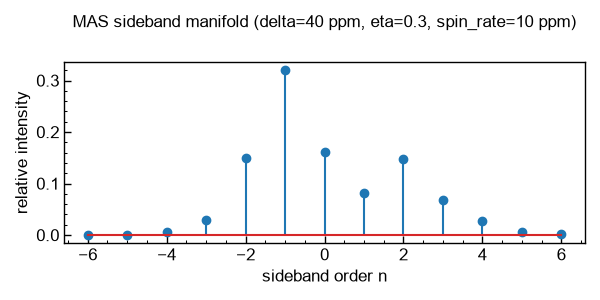

delta=0 (no anisotropy): [0] [1.]
very fast spinning, centerband fraction: 0.999754943969225


In [ ]:
from opennmr.notebook.bms.mas_sidebands import sideband_manifold, haeberlen_to_principal

sxx, syy, szz = haeberlen_to_principal(iso=0.0, delta=40.0, eta=0.3)
print(f"principal values: sxx={sxx:.2f}, syy={syy:.2f}, szz={szz:.2f}")

orders, intens = sideband_manifold(delta=40.0, eta=0.3, spin_rate=10.0, max_order=6)
print("Parseval check (sideband intensities should sum to ~1.0):", intens.sum())

plt.figure(figsize=(6, 3))
plt.stem(orders, intens)
plt.xlabel("sideband order n"); plt.ylabel("relative intensity")
plt.title("MAS sideband manifold (delta=40 ppm, eta=0.3, spin_rate=10 ppm)")
plt.tight_layout()
plt.show()

# sanity cases: delta=0 -> single centerband; very fast spinning -> centerband-dominated
o0, i0 = sideband_manifold(delta=0.0, eta=0.0, spin_rate=10.0)
print("delta=0 (no anisotropy):", o0, i0)

o_fast, i_fast = sideband_manifold(delta=40.0, eta=0.3, spin_rate=1000.0, max_order=3)
print("very fast spinning, centerband fraction:", i_fast[o_fast == 0][0])

### 10.14 Rotation-convention self-check

`bms/verify_rotation_convention.py` is a standalone script (not a plain
importable function) that cross-checks `geometry.quat_to_rotmat` +
`_to_local_frame` against an independently-written textbook
quaternion-to-rotation-matrix, confirming the *algebraic* identity
documented in `geometry.py`'s module docstring. It does **not** tell you
whether that net convention matches what your particle dump intends
(body->world vs world->body) -- that depends on your upstream data
generation, and needs the manual visual check its own
`part2_orientation_sanity_check_template()` prints instructions for.

Worth running once after any change to `geometry.py`, or before trusting
orientation-sensitive results for the first time on a new dataset.

In [ ]:
import runpy, os
import opennmr.notebook.bms as _bms_pkg

runpy.run_path(
    os.path.join(r"C:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\scripts\verify_rotation_convention.py"),
    run_name="__main__",
)

Part 1: checking pts @ quat_to_rotmat(q) == R_std(q) @ pt ...
  max abs error over 200 random quaternions/points: 4.441e-16
  PASS: current code's net effect is pts@R == R_std(q) @ pt, as documented.

Part 2: orientation sanity-check template (needs your judgement)
----------------------------------------------------------------------
  mask value 15 units out along world x-axis: 0.0000  (outside -> not the long axis)
  mask value 15 units out along world y-axis: 1.0000  (inside/near particle -> long axis is here)
  mask value 15 units out along world z-axis: 0.0000  (outside -> not the long axis)

  A 90 deg rotation about world x should swap which of world y/z
  the long (v3) axis points along, leaving world x unaffected.
  Confirm the printed pattern matches what YOUR quaternion
  convention (body->world vs world->body, as produced by your
  particle generator) predicts -- this script does not know that
  convention for you.


{'__name__': '__main__',
 '__doc__': '\nStandalone check of what geometry.quat_to_rotmat + geometry._to_local_frame\nactually compute, and a template for validating the orientation convention\nagainst a known case.\n\nPart 1 (always run, no ground truth needed): confirms the algebraic identity\ndescribed in geometry.py\'s module docstring --\n\n    pts @ quat_to_rotmat(q)  ==  R_std(q) @ pt   for every point pt\n\nwhere R_std(q) is the textbook (non-conjugated) quaternion-to-rotation-matrix,\nbuilt independently here so it isn\'t just checking the code against itself.\n\nPart 2 (a template, not a finished test): shows how to sanity-check the\nconvention against a case you *can* reason about by eye -- a long, thin\nellipsoid rotated by a known angle about a known axis. Fill in the\n"expected" direction for your own dump\'s quaternion convention (body->world\nor world->body) and confirm the mask agrees. This script cannot tell you\nwhich convention your particle dump actually uses -- onl

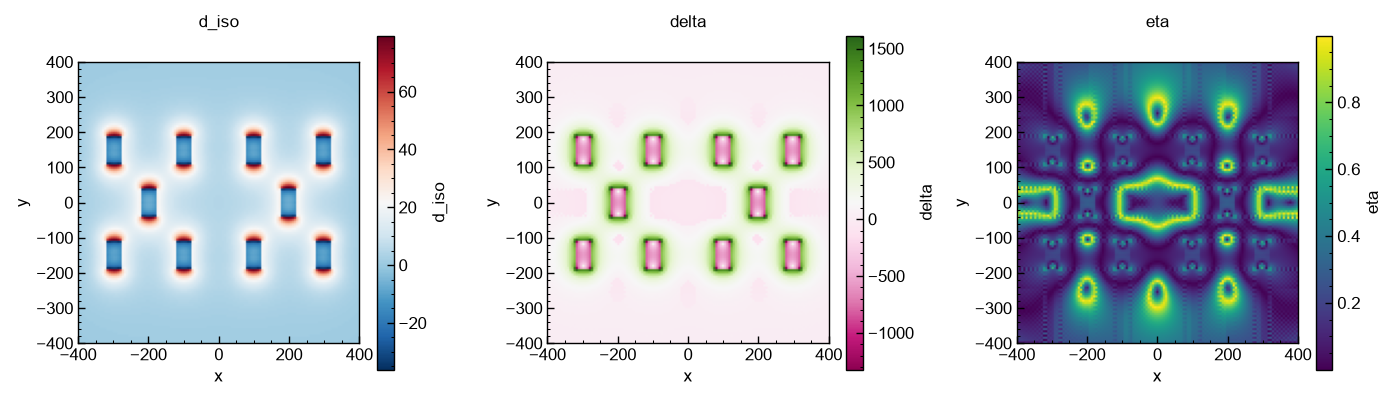

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from opennmr.notebook.bms import run_bms

particles_10 = [
    nmr.make_particle(x=x, y=y, z=0, size=(40, 40, 40))
    for x, y in [(-300,-150),(-100,-150),(100,-150),(300,-150),(-300,150),
                 (-100,150),(100,150),(300,150),(-200,0),(200,0)]
]

df10 = run_bms(
    particles_10,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    box_size=800.0,     # must comfortably enclose all 10 particle positions/sizes
    gridpoints=128,
    equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)
    n_jobs=None,
)

# plot d_iso, delta, eta side by side on the z-midplane
zmid = df10["z"].unique()[np.argmin(np.abs(df10["z"].unique()))]
mid = df10[np.isclose(df10["z"], zmid)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, cmap in zip(axes, ["d_iso", "delta", "eta"], ["RdBu_r", "PiYG", "viridis"]):
    pivot = mid.pivot(index="y", columns="x", values=col)
    im = ax.imshow(pivot.values, origin="lower", cmap=cmap,
                    extent=[pivot.columns.min(), pivot.columns.max(),
                            pivot.index.min(), pivot.index.max()])
    fig.colorbar(im, ax=ax, label=col)
    ax.set_title(col); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

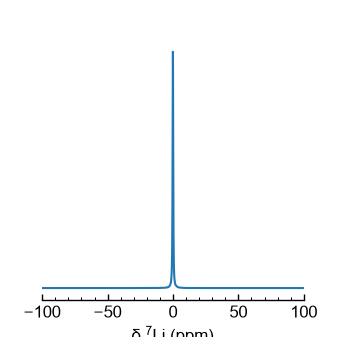

In [ ]:
particles_20 = [
    nmr.make_particle(x=x, y=y, z=z, size=(32, 30, 42))
    for x, y, z in [(-300,-150, 5),(-100,-150, 5),(100,-150, 5),(300,-150, 5),(-300,150, 5),
                    (-100,150, 5),(100,150, 5),(300,150, 5),(-200,0, 5),(200,0, 5),
                    (60, 0, 5), (60, 0, -5), (-60, 0, 5), (-60, 0, -5), (0, 60, 5),
                    (0, -60, 5), (0, 0, 5), (0, 0, -5), (0, 0, 0)]   # however you're generating/loading them
]

local_shift_contribution = [[-850,    -126,   -80.42],
                            [-126.47,  529.61,  39.46],
                            [-80.42,    39.46, 368.39]]

rotor_contribution = [[327.5, 0, 0],
                      [0, 327.5, 0],
                      [0, 0, -655.0]]

bms_spectrum, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles_20,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    nuclide="7Li",
    B0_tesla=9.4,                  # 400 MHz spectrometer
    spin_rate_hz=30000,           # MAS rate -> sideband spacing on the ppm axis

    box_size=1200.0,              # enclose all 20 particles
    gridpoints=32,                # FFT grid resolution per axis
    equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)

    local_shift_contribution=local_shift_contribution,
    rotor_contribution=rotor_contribution,

    linewidth_hz=50.0,
    n_points=32768,
    sw_ppm=2000.0,
    max_order=8,                  # highest sideband order kept
    n_jobs=None,                  # parallelize over the 20 particles
)

ax = nmr.plot_spectrum_dict(bms_spectrum, axis="ppm", channel="real", normalised=True, xlims=[-100, 100])
plt.tight_layout()
plt.show()

sample_particle_sizes: nominal vs realised (post-truncation), per axis (v1,v2,v3):
  mean requested : [30. 33. 42.]
  mean realised  : [30.0763157  32.5574845  42.05100996]
  spread requested (meaning depends on kind='gaussian'): [ 5.  5. 10.]
  std realised   : [4.80589434 5.12642779 9.99652734]
random_close_pack: placed 200/200 particles (100.0%), achieved volume fraction = 0.040


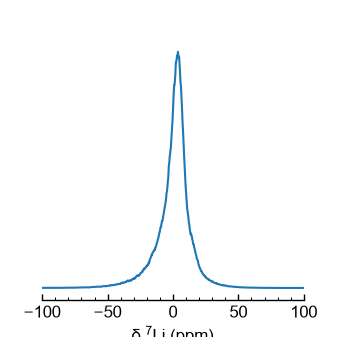

In [ ]:
from opennmr.notebook.bms.packing import random_close_pack

particles, stats = random_close_pack(
    n=200, box_size=800.0,
    mean_size=(30, 33, 42), spread_size=(5, 5, 10),
    size_dist="gaussian", equation="hexagonal", seed=0,
)

local_shift_contribution = [[-850,    -126,   -80.42],
                            [-126.47,  529.61,  39.46],
                            [-80.42,    39.46, 368.39]]

rotor_contribution = [[327.5, 0, 0],
                      [0, 327.5, 0],
                      [0, 0, -655.0]]

spectrum_dict, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    nuclide="7Li",
    B0_tesla=9.4,                  # 400 MHz spectrometer
    spin_rate_hz=30000,           # MAS rate -> sideband spacing on the ppm axis

    gridpoints=64,                # FFT grid resolution per axis
    #equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    #deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)

    local_shift_contribution=local_shift_contribution,
    rotor_contribution=rotor_contribution,

    linewidth_hz=50.0,
    n_points=32768,
    sw_ppm=2000.0,
    max_order=8,                  # highest sideband order kept
    n_jobs=None,
)

ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True, xlims=[-100, 100])
plt.tight_layout()
plt.show()

sample_particle_sizes: nominal vs realised (post-truncation), per axis (v1,v2,v3):
  mean requested : [30. 33. 42.]
  mean realised  : [29.97039092 32.7607101  41.59922364]
  spread requested (meaning depends on kind='gaussian'): [ 5.  5. 10.]
  std realised   : [5.08605617 5.04769638 9.56075282]
grow_and_separate_pack: placed 250/250 particles (100.0%), 0/250 at full nominal size, mean achieved size fraction = 0.261, achieved volume fraction = 0.257
  Some particles were shrunk (isotropically, aspect ratio preserved) to fit -- check achieved_size_fraction per-particle (`s` in the source) if the size distribution fidelity matters for your analysis, or lower n / mean_size / packing density expectations.


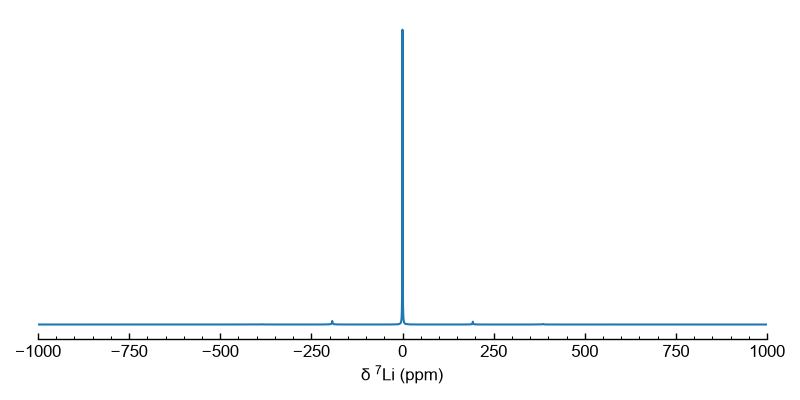

In [ ]:
from opennmr.notebook.bms.packing import grow_and_separate_pack

particles, stats = grow_and_separate_pack(
    n=250, box_size=120.0,
    mean_size=(30, 33, 42), spread_size=(5, 5, 10),
    size_dist="gaussian", equation="hexagonal", seed=0,
    relax_iters_per_step=100, 
)
# stats['achieved_volume_fraction'], stats['n_at_full_size'], stats['mean_achieved_size_fraction']

local_shift_contribution = [[-850,    -126,   -80.42],
                            [-126.47,  529.61,  39.46],
                            [-80.42,    39.46, 368.39]]

rotor_contribution = [[327.5, 0, 0],
                      [0, 327.5, 0],
                      [0, 0, -655.0]]

spectrum_dict, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    nuclide="7Li",
    B0_tesla=9.4,                  # 400 MHz spectrometer
    spin_rate_hz=30000,           # MAS rate -> sideband spacing on the ppm axis

    gridpoints=64,                # FFT grid resolution per axis
    equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)

    local_shift_contribution=local_shift_contribution,
    rotor_contribution=rotor_contribution,

    linewidth_hz=50.0,
    n_points=32768,
    sw_ppm=2000.0,
    max_order=8,                  # highest sideband order kept
    n_jobs=4,
)

ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True, xlims=[-1000, 1000], 
                            pl_width=8.0, pl_height=4.0)
plt.tight_layout()
plt.show()

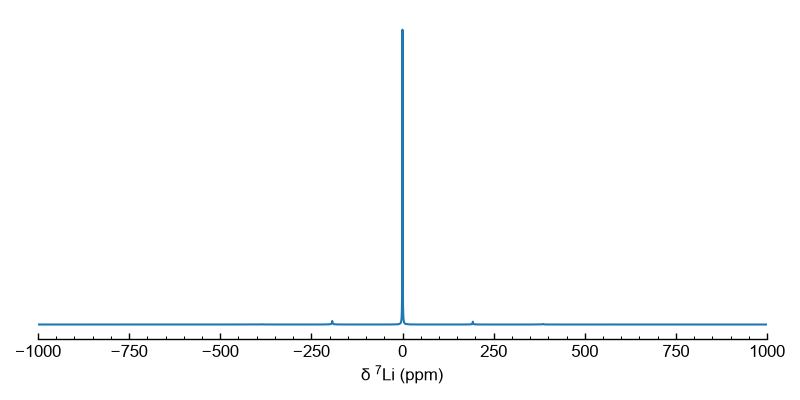

In [ ]:
ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True, xlims=[-1000, 1000], 
                            pl_width=8.0, pl_height=4.0)
plt.tight_layout()
plt.show()